# EDA — Perfiles de investigadores UTEC

Análisis exploratorio de los datos extraídos del portal de investigación de UTEC (Pure / CRIS, `cris.utec.edu.pe`), en la carpeta `utec_perfiles/`:

| Archivo | Contenido |
|---|---|
| `perfiles.csv` | una fila por investigador: cargos, identificadores (ORCID, Scopus, Scholar…), citas, índice h, educación, temas, RENACYT |
| `publicaciones.csv` | una fila por par (investigador, publicación) |
| `huella_digital.csv` | *fingerprint* de conceptos (Elsevier) por investigador: concepto, área y peso |
| `datos_completos.json` | la misma información, anidada por investigador (fuente de la que salen los CSV) |
| `fotos/` | foto de perfil de cada investigador |

Y en la subcarpeta `utec_perfiles/utec_publicaciones_detalle/`, la ficha completa de cada publicación:

| Archivo | Contenido |
|---|---|
| `publicaciones_detalle.csv` | una fila por publicación única: autores completos, resumen, revista/evento, DOI, Scopus, idioma, estado, filiación UTEC, conferencia (país, ciudad, fechas), huella por publicación, BibTeX |
| `publicaciones_detalle.json` | lo mismo, anidado; añade los autores UTEC enlazados a su perfil y la lista de enlaces |
| `publicacion_investigador.csv` | tabla puente (investigador, publicación) con DOI |

**Estructura del notebook**

1. Carga e inventario
2. Calidad de datos: tipos, nulos, consistencia JSON ↔ CSV
3. Limpieza y variables derivadas
4. Perfiles: análisis univariado
5. Perfiles: relaciones entre variables
6. Publicaciones
7. Detalle de publicaciones: filiación, editoriales, conferencias, resúmenes y huella por publicación
8. Red de coautoría interna
9. Huella digital (temas de investigación)
10. Fotos
11. Tabla integrada y conclusiones

## 0. Configuración

In [1]:
import json, re, hashlib, unicodedata, warnings
from pathlib import Path
from collections import Counter
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap, ListedColormap
import seaborn as sns
import networkx as nx
from PIL import Image
from IPython.display import display, Markdown

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_colwidth", 80)
pd.set_option("display.width", 200)

DATA = Path("utec_perfiles")
HOY = pd.Timestamp("2026-10-25")   # fecha de referencia del análisis (extracción: oct-2026)

# --- Paleta (validada para daltonismo; orden fijo, nunca ciclado) ---
SERIES = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
BLUE, ORANGE, AQUA = SERIES[:3]
OTHER = "#b5b3ab"                       # gris para "Otros" / contexto
INK, INK2, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
BLUES_RAMP = ["#cde2fb", "#b7d3f6", "#9ec5f4", "#86b6ef", "#6da7ec", "#5598e7", "#3987e5",
              "#2a78d6", "#256abf", "#1c5cab", "#184f95", "#104281", "#0d366b"]
CMAP_SEQ = LinearSegmentedColormap.from_list("blues", [SURFACE] + BLUES_RAMP)
CMAP_DIV = LinearSegmentedColormap.from_list("div", ["#104281", "#3987e5", "#f0efec", "#e66767", "#a8302f"])
CMAP_MISS = ListedColormap(["#f0efec", "#2a78d6"])  # 0 = falta, 1 = presente

mpl.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "figure.dpi": 110, "font.family": ["Segoe UI", "DejaVu Sans"], "font.size": 9.5,
    "text.color": INK, "axes.labelcolor": INK2, "axes.edgecolor": AXIS, "axes.linewidth": 0.8,
    "axes.titlesize": 12, "axes.titleweight": "semibold", "axes.titlelocation": "left", "axes.titlepad": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6, "axes.axisbelow": True,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.labelcolor": INK2, "ytick.labelcolor": INK2,
    "legend.frameon": False, "lines.linewidth": 2,
})

# --- Utilidades ---
def strip_accents(s):
    return "".join(c for c in unicodedata.normalize("NFKD", str(s)) if not unicodedata.combining(c))

def norm(s):
    return strip_accents(s).lower().strip()

def split_pipe(s):
    return [] if pd.isna(s) else [t.strip() for t in str(s).split(" | ") if t.strip()]

def barh(ax, s, color=BLUE, fmt="{:,.0f}", title=None, xlabel=None):
    """Barras horizontales ordenadas (mayor arriba) con valor al final de cada barra."""
    s = s.sort_values()
    colors = color if isinstance(color, (list, np.ndarray, pd.Series)) else [color] * len(s)
    ax.barh(s.index.astype(str), s.values, color=colors, height=0.68, edgecolor=SURFACE, linewidth=1)
    xmax = s.max() if len(s) else 1
    for y, v in enumerate(s.values):
        ax.text(v + xmax * 0.01, y, fmt.format(v), va="center", fontsize=8.5, color=INK2)
    ax.set_xlim(0, xmax * 1.12)
    ax.grid(axis="y", visible=False)
    ax.spines["left"].set_visible(False)
    ax.tick_params(axis="y", length=0)
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel)
    return ax

def corto(nombre):
    """Nombre corto para etiquetas: nombre + primer apellido."""
    t = nombre.split()
    if len(t) <= 2: return nombre
    if len(t) == 3 and (t[1].endswith(".") or t[1].endswith(("vich", "vna"))): return f"{t[0]} {t[2]}"
    if len(t) == 3: return f"{t[0]} {t[1]}"
    ap = t[-3] if t[-2] in ("Del", "De", "La") else t[-2]
    return f"{t[0]} {ap}"

def hist_log(ax, x, color=BLUE, nbins=20):
    """Histograma de log10(x+1), con ticks en valores originales (admite ceros)."""
    lx = np.log10(np.asarray(x, dtype=float) + 1)
    ax.hist(lx, bins=np.linspace(0, lx.max() * 1.001, nbins + 1), color=color, edgecolor=SURFACE, linewidth=1)
    cand = [0, 1, 3, 10, 30, 100, 300, 1000, 3000] if lx.max() < 3.6 else [0, 1, 10, 100, 1000, 10000, 100000]
    ticks = [v for v in cand if v <= 10 ** lx.max()]
    ax.set_xticks(np.log10(np.array(ticks) + 1), [f"{v:,}" for v in ticks])
    ax.grid(axis="x", visible=False)

def gini(x):
    x = np.sort(np.asarray(x, dtype=float))
    n = len(x)
    return (2 * np.arange(1, n + 1) - n - 1).dot(x) / (n * x.sum())

def resumen(df):
    """Tipo, nulos (contando strings vacíos), cardinalidad y un ejemplo por columna."""
    vacio = df.apply(lambda c: c.isna() | c.astype(str).str.strip().eq(""))
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "nulos": vacio.sum(),
        "% nulos": (vacio.mean() * 100).round(1),
        "únicos": df.nunique(),
        "ejemplo": df.apply(lambda c: str(c.dropna().iloc[0])[:60] if c.notna().any() else ""),
    })

## 1. Carga e inventario

In [2]:
perfiles = pd.read_csv(DATA / "perfiles.csv")
pubs_raw = pd.read_csv(DATA / "publicaciones.csv")
huella_raw = pd.read_csv(DATA / "huella_digital.csv")
with open(DATA / "datos_completos.json", encoding="utf-8") as f:
    raw = json.load(f)

DET = DATA / "utec_publicaciones_detalle"
det_raw = pd.read_csv(DET / "publicaciones_detalle.csv", dtype=str, keep_default_na=False)
pub_inv = pd.read_csv(DET / "publicacion_investigador.csv", dtype=str, keep_default_na=False)
with open(DET / "publicaciones_detalle.json", encoding="utf-8") as f:
    det_json = json.load(f)

fotos = sorted((DATA / "fotos").iterdir())
inventario = pd.DataFrame([
    ("perfiles.csv", *perfiles.shape),
    ("publicaciones.csv", *pubs_raw.shape),
    ("huella_digital.csv", *huella_raw.shape),
    ("datos_completos.json", len(raw), len(raw[0])),
    ("fotos/", len(fotos), None),
    ("utec_publicaciones_detalle/publicaciones_detalle.csv", *det_raw.shape),
    ("utec_publicaciones_detalle/publicaciones_detalle.json", len(det_json), len(det_json[0])),
    ("utec_publicaciones_detalle/publicacion_investigador.csv", *pub_inv.shape),
], columns=["archivo", "filas / registros", "columnas / claves"])
inventario["tamaño (KB)"] = [round((DATA / a).stat().st_size / 1024) if a != "fotos/"
                             else round(sum(f.stat().st_size for f in fotos) / 1024)
                             for a in inventario.archivo]
inventario

,archivo,filas / registros,columnas / claves,tamaño (KB)
0,perfiles.csv,104,22.0,218
1,publicaciones.csv,2976,8.0,6242
2,huella_digital.csv,4683,4.0,337
3,datos_completos.json,104,19.0,7091
4,fotos/,104,NaN,635
5,utec_publicaciones_detalle/publicaciones_detalle.csv,2479,44.0,18672
6,utec_publicaciones_detalle/publicaciones_detalle.json,2479,21.0,20769
7,utec_publicaciones_detalle/publicacion_investigador.csv,2976,6.0,865


## 2. Calidad de datos

### 2.1 Tipos, nulos y cardinalidad

In [3]:
display(Markdown("**perfiles.csv**")); display(resumen(perfiles))
display(Markdown("**publicaciones.csv**")); display(resumen(pubs_raw))
display(Markdown("**huella_digital.csv**")); display(resumen(huella_raw))

**perfiles.csv**

,dtype,nulos,% nulos,únicos,ejemplo
nombre,str,0,0.0,104,Luz Antuanet Adanaque Infante
cargos,str,0,0.0,84,"Docente Enseñanza e Investigador, Departamento de Ciencia de"
email,str,8,7.7,96,ladanaque@utec.edu.pe
orcid,str,8,7.7,96,https://orcid.org/0000-0002-9475-3788
telefono,float64,104,100.0,0,
direccion,str,0,0.0,5,"Jr. Medrano Silva 165, Barranco 15063Perú"
google_scholar,str,26,25.0,77,https://scholar.google.com/citations?hl=es&user=mP764MYAAAAJ
linkedin,str,85,81.7,19,https://pe.linkedin.com/in/luz-adanaque-infante
scopus,str,23,22.1,81,https://www.scopus.com/authid/detail.uri?authorId=5721977326
otros_links,str,14,13.5,90,https://dina.concytec.gob.pe/appDirectorioCTI/VerDatosInvest


**publicaciones.csv**

,dtype,nulos,% nulos,únicos,ejemplo
investigador,str,0,0.0,80,Luz Antuanet Adanaque Infante
email_investigador,str,1216,40.9,74,ladanaque@utec.edu.pe
titulo,str,0,0.0,2460,Deep Neural Network-Assisted Microfluidic pH Sensor
anio,str,0,0.0,1090,2025
tipo,str,0,0.0,9,Artículo
autores,str,1012,34.0,252,"Adanaque-Infante, L."
referencia,str,0,0.0,2478,Deep Neural Network-Assisted Microfluidic pH SensorVentura-G
url,str,0,0.0,2479,https://cris.utec.edu.pe/es/publications/deep-neural-network


**huella_digital.csv**

,dtype,nulos,% nulos,únicos,ejemplo
investigador,str,0,0.0,80,Luz Antuanet Adanaque Infante
concepto,str,0,0.0,3356,CubeSat
area,str,0,0.0,20,Engineering
peso,str,0,0.0,87,100%


**Observaciones**

- `perfiles.csv` tiene **104 investigadores × 22 columnas**. Las columnas multivalor (`cargos`, `educacion`, `temas_interes`, `otros_links`, `huella_digital_top10`) vienen como texto separado por ` | `, así que hay que separarlas antes de analizarlas.
- **`telefono` está 100 % vacío** y `direccion` es en la práctica constante (la sede de Barranco, con 5 variantes del código postal). Ninguna de las dos aporta información.
- `citas` e `indice_h` son numéricas, pero faltan en el 25 % de los perfiles.
- En `publicaciones.csv` el campo **`anio` es texto con tres formatos** (`2025`, `ago. 2004`, `18 dic. 2020`). `email_investigador` falta en el 41 % de las filas y `autores` en el 34 %. Más abajo se ve que casi todos esos huecos son de un solo investigador.
- En `huella_digital.csv`, `peso` es texto con `%` y hay que convertirlo a número.

### 2.2 Mapa de completitud de los perfiles

findfont: Failed to find font weight semibold, now using 700.


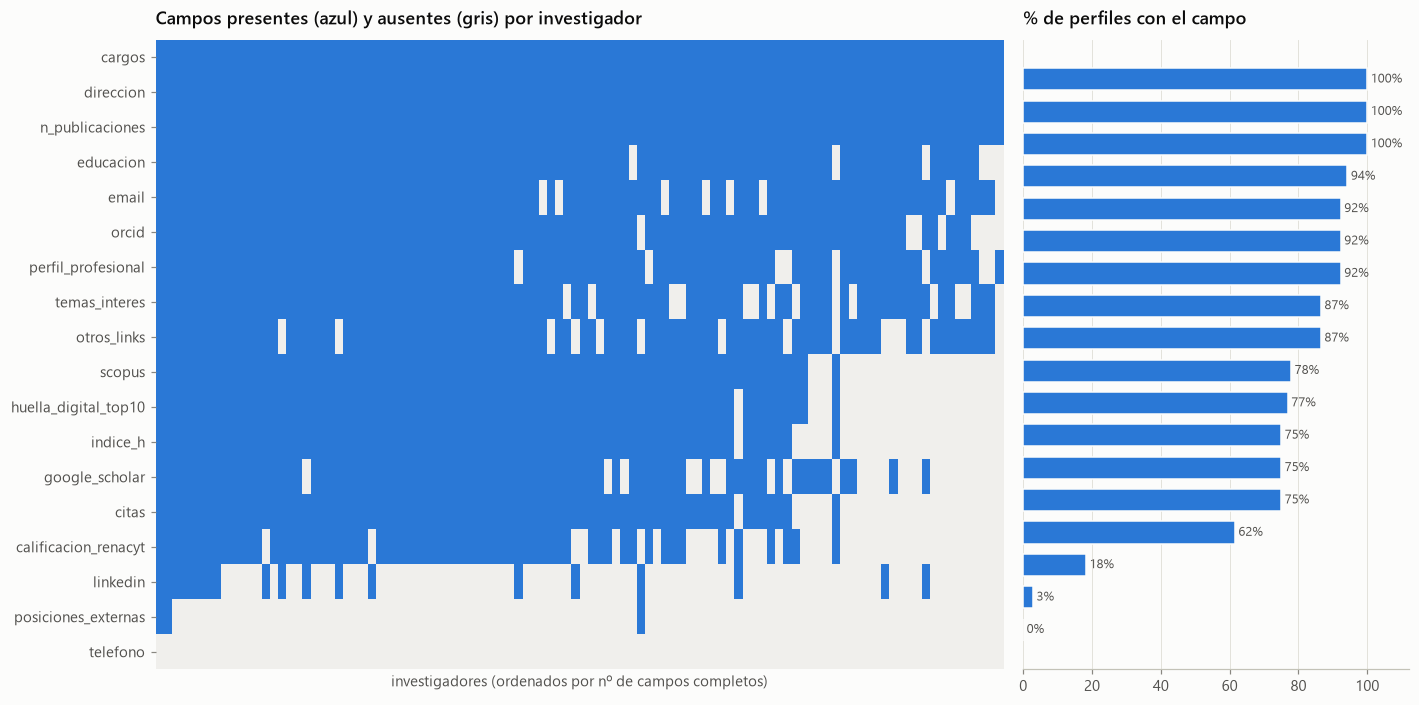

In [4]:
campos = [c for c in perfiles.columns if c not in ("nombre", "archivo_foto", "url_perfil", "foto_url")]
presente = perfiles[campos].notna() & perfiles[campos].astype(str).apply(lambda c: c.str.strip().ne(""))
orden_filas = presente.sum(axis=1).sort_values(ascending=False).index
orden_cols = presente.mean().sort_values(ascending=False).index

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 6.5), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.imshow(presente.loc[orden_filas, orden_cols].T.astype(int).values, aspect="auto",
           cmap=CMAP_MISS, interpolation="nearest")
ax1.set_yticks(range(len(orden_cols)), orden_cols)
ax1.set_xlabel("investigadores (ordenados por nº de campos completos)")
ax1.set_xticks([]); ax1.grid(False)
ax1.set_title("Campos presentes (azul) y ausentes (gris) por investigador")
for s in ax1.spines.values(): s.set_visible(False)

barh(ax2, presente.mean()[orden_cols] * 100, fmt="{:.0f}%", title="% de perfiles con el campo")
ax2.set_yticks([])
plt.tight_layout(); plt.show()

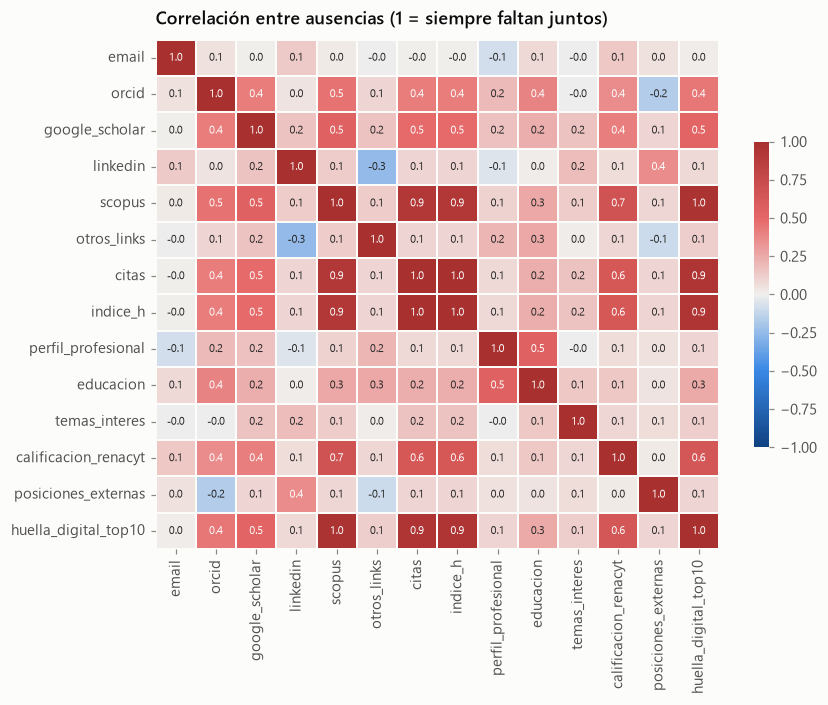

¿De dónde vienen las citas? Ausencia de citas vs ausencia de Scopus / Google Scholar:


scopus ausente       scholar ausente      
scopus                 False True            False True 
citas ausente                                           
False                     78     0              68    10
True                       3    23              10    16

In [5]:
# ¿Qué campos faltan juntos?  (correlación entre indicadores de ausencia)
ausente = ~presente[[c for c in campos if 0 < presente[c].mean() < 1]]
fig, ax = plt.subplots(figsize=(8, 6.5))
sns.heatmap(ausente.corr(), cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".1f",
            annot_kws={"fontsize": 7.5}, linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Correlación entre ausencias (1 = siempre faltan juntos)")
plt.tight_layout(); plt.show()

print("¿De dónde vienen las citas? Ausencia de citas vs ausencia de Scopus / Google Scholar:")
display(pd.concat({"scopus ausente": pd.crosstab(ausente["citas"], ausente["scopus"]),
                   "scholar ausente": pd.crosstab(ausente["citas"], ausente["google_scholar"])}, axis=1)
        .rename_axis("citas ausente"))

**Patrones de ausencia**

- Los campos bibliométricos **faltan en bloque**: `scopus`, `citas`, `indice_h` y `huella_digital_top10` tienen correlaciones de ausencia entre 0,9 y 1,0. La tabla cruzada lo confirma: **si no hay Scopus, no hay citas** (23 de 23), y solo 3 perfiles tienen enlace a Scopus sin citas. Con Google Scholar la relación es mucho más débil (10 + 10 discrepancias). Conclusión: **las citas y el índice h vienen de Scopus** (Pure las sincroniza con Scopus), no de Google Scholar.
- Los 24 perfiles sin huella digital son exactamente los 24 sin publicaciones en CRIS (se comprueba en la sección 9).
- `calificacion_renacyt` también se asocia a la ausencia de Scopus (0,7): quien no está indexado rara vez tiene RENACYT.
- `email`, `perfil_profesional` y `educacion` faltan de forma casi independiente del resto. Son huecos de mantenimiento del perfil, no un patrón sistemático.

### 2.3 Consistencia entre el JSON y los CSV

In [6]:
chk = {}
chk["mismos investigadores (JSON vs perfiles.csv)"] = [r["nombre"] for r in raw] == perfiles.nombre.tolist()
chk["nº publicaciones JSON == filas publicaciones.csv"] = sum(len(r["publicaciones"]) for r in raw) == len(pubs_raw)
chk["nº conceptos JSON == filas huella_digital.csv"] = sum(len(r["huella_digital"]) for r in raw) == len(huella_raw)
cnt = pubs_raw.groupby("investigador").size()
chk["n_publicaciones == conteo en publicaciones.csv"] = (
    perfiles.set_index("nombre").n_publicaciones == cnt.reindex(perfiles.nombre).fillna(0).astype(int).values).all()
chk["citas JSON == citas CSV"] = all(
    (r["citas"] == "" and pd.isna(c)) or (r["citas"] != "" and float(r["citas"]) == c)
    for r, c in zip(raw, perfiles.citas))
chk["nombres únicos"] = perfiles.nombre.is_unique
chk["URLs de perfil únicas"] = perfiles.url_perfil.is_unique
chk["toda foto referenciada existe"] = all((DATA / f).exists() for f in perfiles.archivo_foto)
display(pd.Series(chk, name="OK").to_frame())

# Secciones de "perfil" en el JSON: cuántos investigadores tienen cada una
secciones = Counter(k for r in raw for k in r["perfil"])
display(pd.Series(secciones, name="investigadores").sort_values(ascending=False).to_frame())

,OK
mismos investigadores (JSON vs perfiles.csv),True
nº publicaciones JSON == filas publicaciones.csv,True
nº conceptos JSON == filas huella_digital.csv,True
n_publicaciones == conteo en publicaciones.csv,True
citas JSON == citas CSV,True
nombres únicos,True
URLs de perfil únicas,True
toda foto referenciada existe,True


,investigadores
Educación,98
Perfil profesional,96
Temas de Interés de Investigación,90
Calificación Renacyt,64
Posiciones externas,3
Intereses de la investigación,3
Palabras clave,1


In [7]:
# Campos constantes o sin información
print("telefono  -> valores no nulos:", perfiles.telefono.notna().sum())
print("direccion -> variantes:")
print(perfiles.direccion.value_counts().to_string())
print("\nfoto_url repetidas (placeholder 'no-portrait'):")
print(perfiles.loc[perfiles.foto_url.duplicated(keep=False), ["nombre", "foto_url"]].to_string(index=False))

telefono  -> valores no nulos: 0
direccion -> variantes:
direccion
Jr. Medrano Silva 165, Barranco 15063Perú              90
Jr. Medrano Silva 165, Barranco 15076Perú               7
Jr. Medrano Silva 165, Barranco 15073Perú               3
Jr. Medrano Silva 165, Barranco 15075Perú               3
Jr. Medrano Silva 165, Barranco 1506315063 LimaPerú     1

foto_url repetidas (placeholder 'no-portrait'):
                  nombre                                                                         foto_url
    Eric Javier Biagioli https://cris.utec.edu.pe/assets/no-portrait-473c6d005990baa1f418d9c668dcd4ec.png
Luis Ernesto Flores Luyo https://cris.utec.edu.pe/assets/no-portrait-473c6d005990baa1f418d9c668dcd4ec.png


**Consistencia**: el JSON y los CSV coinciden en todo lo que se comprobó (investigadores, conteos, citas). `n_publicaciones` equivale exactamente al número de filas de cada investigador en `publicaciones.csv`. Los CSV son, por tanto, una versión aplanada y completa del JSON, **con dos excepciones**: las secciones `Intereses de la investigación` (3 perfiles) y `Palabras clave` (1 perfil) solo existen en el JSON. Su cobertura es mínima y se pueden ignorar.

Otros detalles: dos perfiles no tienen foto real y usan el *placeholder* `no-portrait` de Pure.

### 2.4 Detalle de publicaciones: consistencia y completitud

`publicaciones_detalle.csv` tiene una fila por publicación única. Se comprueba que describe el mismo universo que `publicaciones.csv` y que el CSV y el JSON coinciden.

In [8]:
J = pd.DataFrame(det_json)
chk = {}
chk["mismas URLs que publicaciones.csv"] = set(det_raw.url) == set(pubs_raw.url)
chk["una fila por URL"] = det_raw.url.is_unique
chk["pares (investigador, URL) == publicaciones.csv"] = (
    set(zip(pub_inv.investigador, pub_inv.url)) == set(zip(pubs_raw.investigador, pubs_raw.url)))
m = pub_inv.merge(pubs_raw, on=["investigador", "url"], suffixes=("", "_p"))
chk["título y tipo == publicaciones.csv"] = (m.titulo == m.titulo_p).all() and (m.tipo == m.tipo_p).all()
chk["año == año del campo anio original"] = all(a in b for a, b in zip(m.anio, m.anio_p))
chk["DOI tabla puente == DOI del detalle"] = (pub_inv.merge(det_raw[["url", "doi"]], on="url")
                                             .pipe(lambda d: d.doi_x == d.doi_y).all())
chk["JSON y CSV en el mismo orden"] = (J.url.values == det_raw.url.values).all()
for c in ["titulo", "autores", "resumen", "doi", "scopus"]:
    chk[f"JSON == CSV: {c}"] = (J[c].values == det_raw[c].values).all()
chk["JSON == CSV: huella"] = (J.huella.str.join(" | ").values == det_raw.huella.values).all()
chk["JSON == CSV: investigadores_utec"] = (J.investigadores_utec_perfil.str.join(" | ").values
                                           == det_raw.investigadores_utec.values).all()
chk["JSON == CSV: organizaciones_utec"] = (J.organizaciones.str.join(" | ").values
                                           == det_raw.organizaciones_utec.values).all()
chk["'Publicado de forma externa' = Sí ⇔ sin organización UTEC"] = (
    (det_raw["Publicado de forma externa"] == "Sí") == (det_raw.organizaciones_utec == "")).all()
display(pd.Series(chk, name="OK").to_frame())

vinc = pd.Series([re.search(r"<(.*)>", a).group(1) for r in det_json for a in r["autores_utec"]])
display(pd.Series({
    "tipo_familia (valores)": J.tipo_familia.unique().tolist(),
    "tipo_padre == categoria": (J.tipo_padre.str.rstrip(" ›").values == det_raw.categoria.values).all(),
    "publicaciones con ≥1 autor UTEC enlazado (autores_utec)": int(J.autores_utec.str.len().gt(0).sum()),
    "personas UTEC distintas enlazadas": vinc.nunique(),
    "enlazadas que están entre los 104 perfiles": vinc.isin(perfiles.url_perfil).sum() == len(vinc),
    "archivos no vacíos": int(J.archivos.str.len().gt(0).sum()),
    "citas_texto no vacías": int(J.citas_texto.ne("").sum()),
    "citar_apa no vacías": int(J.citar_apa.ne("").sum()),
    "otros_enlaces (CSV) no vacíos": int(det_raw.otros_enlaces.ne("").sum()),
}, name="valor").to_frame())

,OK
mismas URLs que publicaciones.csv,True
una fila por URL,True
"pares (investigador, URL) == publicaciones.csv",True
título y tipo == publicaciones.csv,True
año == año del campo anio original,True
DOI tabla puente == DOI del detalle,True
JSON y CSV en el mismo orden,True
JSON == CSV: titulo,True
JSON == CSV: autores,True
JSON == CSV: resumen,True


,valor
tipo_familia (valores),[Producción científica:]
tipo_padre == categoria,True
publicaciones con ≥1 autor UTEC enlazado (autores_utec),1870
personas UTEC distintas enlazadas,80
enlazadas que están entre los 104 perfiles,True
archivos no vacíos,0
citas_texto no vacías,0
citar_apa no vacías,0
otros_enlaces (CSV) no vacíos,0


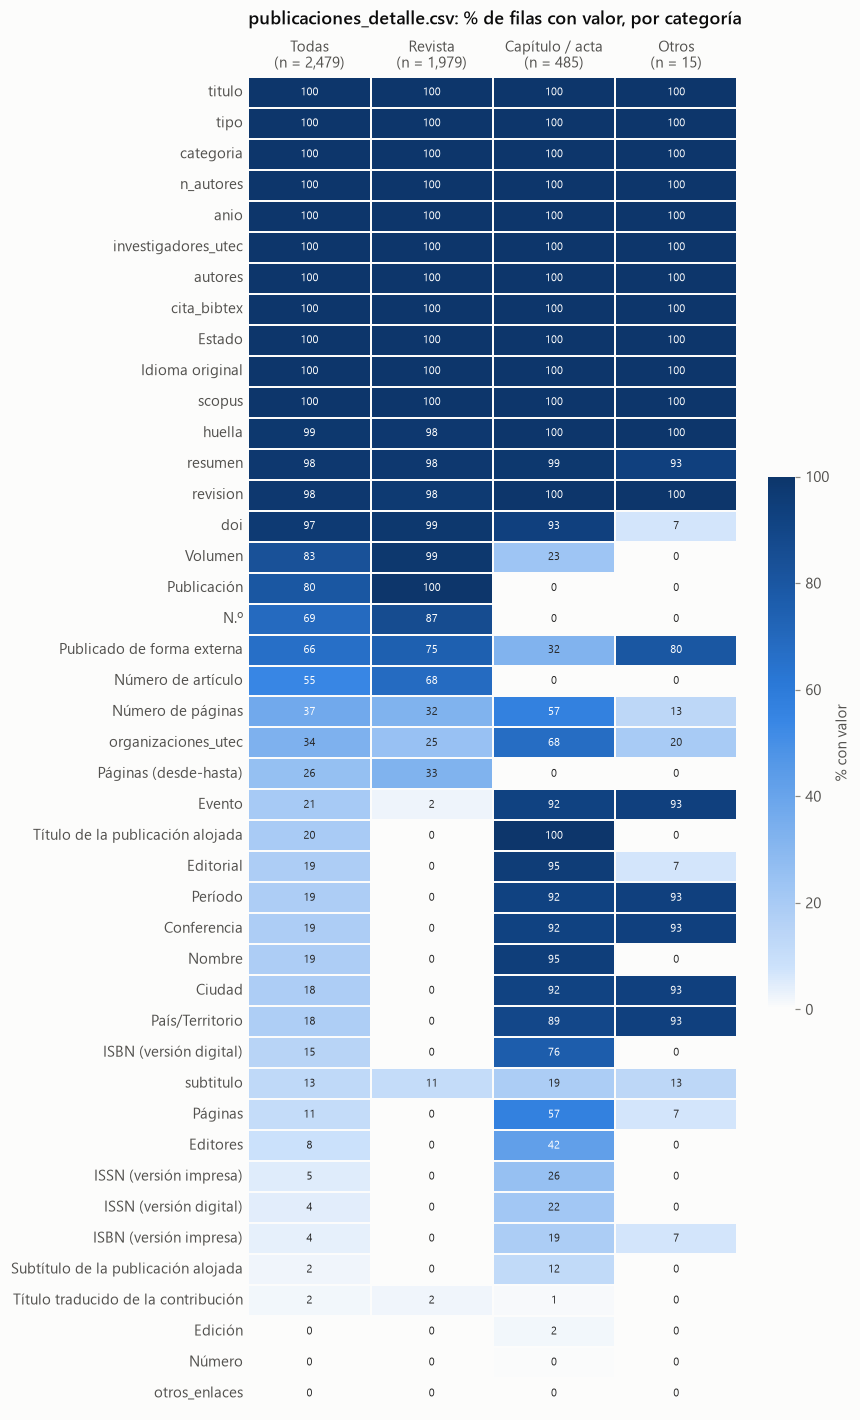

In [9]:
# Completitud por campo y categoría de publicación: muchos huecos son estructurales
# (p. ej. 'Volumen' solo aplica a revistas; 'Conferencia', 'Ciudad' o 'ISBN' solo a actas)
CAT = {"Contribución a una revista": "Revista", "Capítulo del libro/informe/acta de congreso": "Capítulo / acta"}
cat = det_raw.categoria.map(CAT).fillna("Otros")
lleno = det_raw.drop(columns=["url"]).ne("")
C = lleno.groupby(cat).mean().T * 100
C = C[["Revista", "Capítulo / acta", "Otros"]]
C.columns = [f"{c}\n(n = {(cat == c).sum():,})" for c in C.columns]
C.insert(0, f"Todas\n(n = {len(det_raw):,})", lleno.mean() * 100)
C = C.sort_values(C.columns[0], ascending=False)

fig, ax = plt.subplots(figsize=(8, 13))
sns.heatmap(C, cmap=CMAP_SEQ, vmin=0, vmax=100, annot=True, fmt=".0f", annot_kws={"fontsize": 7.5},
            linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": .4, "label": "% con valor"}, ax=ax)
ax.set_title("publicaciones_detalle.csv: % de filas con valor, por categoría")
ax.tick_params(axis="x", labeltop=True, labelbottom=False, length=0); ax.tick_params(axis="y", length=0)
ax.set_ylabel(""); plt.tight_layout(); plt.show()

**Calidad del detalle de publicaciones**

- **Universo idéntico**: las mismas 2479 URLs y los mismos 2976 pares (investigador, publicación) que `publicaciones.csv`, con título, tipo, año y DOI coincidentes. `publicacion_investigador.csv` es la tabla puente de `publicaciones.csv` más el DOI.
- **JSON y CSV coinciden** campo a campo. El JSON solo añade `autores_utec` (los autores UTEC enlazados a su perfil: 80 personas, todas entre los 104 perfiles), la lista de enlaces y campos que siempre están vacíos (`archivos`, `citas_texto`, `citar_apa`). En el CSV, `otros_enlaces` también está siempre vacío.
- **Los huecos son estructurales**. Los campos de revista (`Publicación`, `Volumen`, `N.º`, `Número de artículo`) están casi completos en artículos y vacíos en actas. Los de evento (`Conferencia`, `Ciudad`, `País/Territorio`, `Período`, `ISBN`, `Editorial`) siguen el patrón inverso. No hay que imputarlos: hay que analizarlos dentro de la categoría que corresponde.
- Están casi completos: resumen (98 %), huella (99 %), DOI (97 %), enlace a Scopus (99,8 %) e idioma (100 %).
- `Publicado de forma externa` solo toma el valor "Sí" o vacío, y es exactamente el complemento de `organizaciones_utec`. Funciona como **indicador de filiación UTEC**.

## 3. Limpieza y variables derivadas

### 3.1 Perfiles

- **Cargos** → se separan en (rol, unidad). La unidad se clasifica por tipo (Departamento, Grupo, Centro, Instituto, Facultad…). El *departamento principal* es el primer departamento listado.
- **Categoría docente** → a partir de los roles (Principal / Asociado / Auxiliar / Docente de Enseñanza e Investigación…). Además, un indicador de cargo **directivo** (director, decano, rector, coordinador).
- **Educación** → grado más alto *concluido* (los grados con fecha de fin `…` se marcan como en curso) e institución del doctorado.
- **RENACYT** → se unifican las dos nomenclaturas: la antigua (Nivel I–VII) y la del reglamento 2021 (*Carlos Monge Medrano* I–IV ≡ Nivel I–IV; *María Rostworowski* I–III ≡ Nivel V–VII). *Investigador Distinguido* es la categoría máxima. Nivel I es el más alto.

In [10]:
TIPOS_UNIDAD = ("Departamento", "Grupo", "Centro", "Instituto", "Facultad", "Dirección", "Universidad")

def parse_cargo(c):
    if c.startswith(TIPOS_UNIDAD):
        return None, c
    pos = [c.find(", " + t) for t in TIPOS_UNIDAD if c.find(", " + t) > 0]
    if not pos:
        return c, None
    i = min(pos)
    return c[:i].strip(), c[i + 2:].strip()

cargos = (perfiles[["nombre", "cargos"]]
          .assign(cargo=perfiles.cargos.map(split_pipe)).explode("cargo").dropna(subset=["cargo"]))
cargos[["rol", "unidad"]] = cargos.cargo.apply(lambda c: pd.Series(parse_cargo(c)))
cargos["tipo_unidad"] = cargos.unidad.str.split().str[0]
cargos = cargos.drop(columns="cargos")

dep = (cargos[cargos.tipo_unidad == "Departamento"].groupby("nombre").unidad.first()
       .str.replace("Departamento de ", "", regex=False))
perfiles["departamento"] = perfiles.nombre.map(dep).fillna("Sin departamento")
perfiles["n_departamentos"] = perfiles.nombre.map(
    cargos[cargos.tipo_unidad == "Departamento"].groupby("nombre").unidad.nunique()).fillna(0).astype(int)
perfiles["n_grupos_centros"] = perfiles.nombre.map(
    cargos[cargos.tipo_unidad.isin(["Grupo", "Centro", "Instituto"])].groupby("nombre").unidad.nunique()
).fillna(0).astype(int)

def categoria_docente(roles):
    r = " ".join(norm(x) for x in roles if isinstance(x, str))
    if "profesor principal" in r: return "Profesor Principal"
    if "profesor asociado" in r or "docente asociado" in r: return "Profesor Asociado"
    if "profesor auxiliar" in r: return "Profesor Auxiliar"
    if "ensenanza e investiga" in r: return "Docente de Enseñanza e Inv."
    if "docente" in r: return "Docente (otro)"
    if "investigador" in r: return "Solo investigador"
    return "Sin rol explícito"

roles = cargos.groupby("nombre").rol.apply(list)
perfiles["categoria"] = perfiles.nombre.map(roles).map(categoria_docente)
perfiles["directivo"] = perfiles.nombre.map(
    roles.map(lambda rs: any(re.search(r"director|decan|rector|coordinador", norm(x)) for x in rs if isinstance(x, str))))

display(cargos.tipo_unidad.value_counts().rename("menciones").to_frame().T)
display(cargos.head(8))

tipo_unidad,Universidad,Departamento,Grupo,Centro,Instituto,Facultad,Dirección
menciones,104,96,43,22,5,2,1


,nombre,cargo,rol,unidad,tipo_unidad
0,Luz Antuanet Adanaque Infante,"Docente Enseñanza e Investigador, Departamento de Ciencia de Computación y d...",Docente Enseñanza e Investigador,Departamento de Ciencia de Computación y de Datos,Departamento
0,Luz Antuanet Adanaque Infante,Universidad de Ingeniería y Tecnología - UTEC,NaN,Universidad de Ingeniería y Tecnología - UTEC,Universidad
1,José Manuel Aguilar Alfaro,"Investigador, Grupo de Investigación en Analítica de Datos y Ciencias de Dec...",Investigador,Grupo de Investigación en Analítica de Datos y Ciencias de Decisión (DADS),Grupo
1,José Manuel Aguilar Alfaro,"Docente Asociado, Departamento de Negocios Digitales",Docente Asociado,Departamento de Negocios Digitales,Departamento
1,José Manuel Aguilar Alfaro,Universidad de Ingeniería y Tecnología - UTEC,NaN,Universidad de Ingeniería y Tecnología - UTEC,Universidad
2,Helard Alvarez Sanchez,Departamento de Ingeniería Mecánica y de la Energía,NaN,Departamento de Ingeniería Mecánica y de la Energía,Departamento
2,Helard Alvarez Sanchez,"Investigador, Grupo de investigación en energía y minas",Investigador,Grupo de investigación en energía y minas,Grupo
2,Helard Alvarez Sanchez,"Investigador, Grupo de Investigación en Diseño de Productos con Simulación C...",Investigador,Grupo de Investigación en Diseño de Productos con Simulación Computacional (...,Grupo


In [11]:
PERU = ("peru", "pucp", "san marcos", "nacional de ingenieria", "san agustin", "esan", "cayetano",
        "utec", "del pacifico", "la molina", "lima", "piura", "antenor orrego", "trujillo", "cusco", "cuzco",
        "san antonio abad", "arequipa", "huancayo", "ricardo palma", "villarreal", "san martin de porres",
        "ingenieria y tecnologia", "callao", "cajamarca", "ayacucho", "huamanga", "ucsur", "cientifica del sur")
PAISES = {"brasil", "brazil", "mexico", "méxico", "peru", "perú", "chile", "espana", "españa", "usa", "eeuu"}
FECHA = re.compile(r"(Fecha de beca:.*)$|\s*((\d{1,2}\s)?(\w{3,4}\.\s)?\d{4})?(\s*→\s*((\d{1,2}\s)?(\w{3,4}\.\s)?\d{4}|…))?\s*$")

def parse_educacion(item):
    t = norm(item)
    if re.search(r"doctor|ph\.?\s?d|dphil", t): g = "Doctorado"
    elif re.search(r"master|maestr|magister|m\.?sc", t): g = "Maestría"
    elif "bachiller" in t: g = "Bachiller"
    elif re.search(r"titulo|ingenier|licenciad|abogad|arquitect|economista", t): g = "Título profesional"
    else: g = "Otro"
    en_curso = "→ …" in item
    partes = [p.strip() for p in FECHA.sub("", FECHA.sub("", item)).split(",") if p.strip()]
    inst = partes[-1] if partes else None
    if inst and norm(inst) in PAISES and len(partes) > 1:
        inst = partes[-2]
    return g, en_curso, inst

edu = (perfiles[["nombre", "educacion"]].assign(item=perfiles.educacion.map(split_pipe))
       .explode("item").dropna(subset=["item"]))
edu[["grado", "en_curso", "institucion"]] = edu["item"].apply(lambda s: pd.Series(parse_educacion(s)))
edu["inst_peru"] = edu.institucion.map(lambda s: any(k in norm(s) for k in PERU) if s else None)

ORDEN_GRADO = ["Doctorado", "Maestría", "Título profesional", "Bachiller", "Otro"]
rank = {g: i for i, g in enumerate(ORDEN_GRADO)}
gmax = edu[~edu.en_curso].assign(r=lambda d: d.grado.map(rank)).sort_values("r").groupby("nombre").grado.first()
perfiles["grado_max"] = perfiles.nombre.map(gmax).fillna("Sin dato")
perfiles["doctorado_en_curso"] = perfiles.nombre.isin(edu[(edu.grado == "Doctorado") & edu.en_curso].nombre)

display(edu[["nombre", "grado", "en_curso", "institucion", "inst_peru"]].sample(8, random_state=4))

,nombre,grado,en_curso,institucion,inst_peru
4,Sergio Aranda Egusquiza,Bachiller,False,Universidad Privada Antenor Orrego,True
52,Wangdo Kim,Doctorado,False,Lehigh University,False
1,José Manuel Aguilar Alfaro,Maestría,False,Universidad ESAN,True
84,Yamilet Rosario Serrano Llerena,Doctorado,False,National University of Singapore,False
19,Ana Rocio Cardenas Maita,Bachiller,False,Universidad Nacional De San Antonio Abad Del Cusco,True
13,Aoife Bennett,Título profesional,False,Trinity College Dublin,False
66,Sergio Quispe Rodriguez,Maestría,False,University of Campinas (UNICAMP),False
61,Vanessa Orihuela Munive,Título profesional,False,Pontificia Universidad Católica del Perú,True


In [12]:
ROMANO = {"i": 1, "ii": 2, "iii": 3, "iv": 4, "v": 5, "vi": 6, "vii": 7}

def renacyt_nivel(s):
    """0 = Investigador Distinguido; 1..7 = Nivel I..VII (1 es el más alto); NaN = sin calificación."""
    if pd.isna(s): return np.nan
    t = norm(s)
    if "distinguido" in t: return 0
    m = re.search(r"\b([iv]+)$", t)
    n = ROMANO[m.group(1)]
    return n + 4 if "rostworowski" in t else n

perfiles["renacyt_nivel"] = perfiles.calificacion_renacyt.map(renacyt_nivel)
ETQ_RENACYT = {0: "Distinguido", 1: "I", 2: "II", 3: "III", 4: "IV", 5: "V", 6: "VI", 7: "VII"}
perfiles["renacyt"] = perfiles.renacyt_nivel.map(ETQ_RENACYT).fillna("Sin RENACYT")
display(pd.crosstab(perfiles.calificacion_renacyt.fillna("—"), perfiles.renacyt))

renacyt,Distinguido,I,II,III,IV,Sin RENACYT,V,VI,VII
calificacion_renacyt,,,,,,,,,
Carlos Monge III,0,0,0,1,0,0,0,0,0
Carlos Monge IV,0,0,0,0,2,0,0,0,0
Investigador Distinguido,1,0,0,0,0,0,0,0,0
Investigador distinguido,1,0,0,0,0,0,0,0,0
MARIA ROSTWOROWSKI I,0,0,0,0,0,0,1,0,0
Nivel I,0,1,0,0,0,0,0,0,0
Nivel II,0,0,5,0,0,0,0,0,0
Nivel III,0,0,0,8,0,0,0,0,0
Nivel IV,0,0,0,0,10,0,0,0,0


In [13]:
# Indicadores simples
for c in ["orcid", "google_scholar", "scopus", "linkedin", "otros_links", "email"]:
    perfiles["tiene_" + c] = perfiles[c].notna()
perfiles["n_temas"] = perfiles.temas_interes.map(split_pipe).map(len)
perfiles["len_perfil"] = perfiles.perfil_profesional.fillna("").str.len()
perfiles["n_identificadores"] = perfiles[["tiene_orcid", "tiene_google_scholar", "tiene_scopus",
                                          "tiene_linkedin", "tiene_otros_links"]].sum(axis=1)
perfiles[["nombre", "departamento", "categoria", "directivo", "grado_max", "renacyt",
          "citas", "indice_h", "n_publicaciones", "n_temas"]].head(10)

,nombre,departamento,categoria,directivo,grado_max,renacyt,citas,indice_h,n_publicaciones,n_temas
0,Luz Antuanet Adanaque Infante,Ciencia de Computación y de Datos,Docente de Enseñanza e Inv.,False,Maestría,VII,15.0,3.0,5,3
1,José Manuel Aguilar Alfaro,Negocios Digitales,Profesor Asociado,False,Doctorado,Sin RENACYT,NaN,NaN,0,4
2,Helard Alvarez Sanchez,Ingeniería Mecánica y de la Energía,Solo investigador,False,Maestría,VII,10.0,2.0,3,2
3,Grace Alexandrino Ocaña,"Humanidades, Artes y Ciencias Sociales",Profesor Auxiliar,False,Sin dato,VII,17.0,2.0,3,3
4,Sergio Aranda Egusquiza,Ingeniería Electrónica y Mecatrónica,Sin rol explícito,False,Maestría,Sin RENACYT,1.0,1.0,6,10
5,Claudia Antonini Bova,Ingeniería Industrial y Gestión de la Ingeniería,Solo investigador,False,Doctorado,Sin RENACYT,28.0,3.0,4,7
6,Patricia Araujo Pantoja,Ingeniería Mecánica y de la Energía,Docente (otro),False,Doctorado,VI,72.0,4.0,6,7
7,Andrés Julián Arias Moreno,Bioingeniería e Ingeniería Química,Solo investigador,False,Doctorado,Sin RENACYT,82.0,4.0,4,4
8,Walter Sebastian Barrutia Alta,Ingeniería Electrónica y Mecatrónica,Docente de Enseñanza e Inv.,False,Doctorado,VII,32.0,3.0,4,3
9,Jesús Edwin Bellido Angulo,Sin departamento,Sin rol explícito,True,Doctorado,Sin RENACYT,85.0,4.0,6,4


### 3.2 Publicaciones

- **Fecha**: el campo `anio` mezcla tres precisiones (`2025`, `ago. 2004`, `18 dic. 2020`). Se extrae el año y se registra la precisión.
- **Referencia**: tiene el formato `Título + Autores, fecha, Revista/Evento…`. De ahí se obtienen los autores, una primera estimación del número total de autores y la revista/evento. (El conteo de autores se reemplaza en 3.3 por el del archivo de detalle, más fiable).
- **Duplicados**: una misma publicación aparece una vez por cada investigador UTEC que la firma. Se crea una tabla de **publicaciones únicas** (por URL).

In [14]:
MESES = {"ene": 1, "feb": 2, "mar": 3, "abr": 4, "may": 5, "jun": 6, "jul": 7, "ago": 8, "set": 9, "sep": 9,
         "oct": 10, "nov": 11, "dic": 12}
INICIAL = re.compile(r"^(?:[A-ZÀ-ÝŁŠŽČ][a-zà-ÿ]{0,2}\.[\s-]?)+$")

pubs = pubs_raw.copy()
pubs["anio_num"] = pubs.anio.str.extract(r"(\d{4})")[0].astype(int)
pubs["mes"] = pubs.anio.str.extract(r"([a-z]{3})\.")[0].map(MESES)
pubs["precision_fecha"] = np.select(
    [pubs.anio.str.fullmatch(r"\d{4}"), pubs.anio.str.fullmatch(r"[a-z]{3}\. \d{4}")],
    ["año", "mes"], default="día")

def parse_referencia(r):
    ref = r.referencia
    resto = ref[len(r.titulo):] if ref.startswith(r.titulo) else ref
    m = re.search(r",\s*" + re.escape(r.anio) + r"(?:,\s*|\.?$)", resto)
    if not m:
        return pd.Series({"autores_ref": None, "venue": None, "n_autores": np.nan, "consorcio": False})
    autores, fuente = resto[:m.start()], resto[m.end():]
    otros = re.search(r" y (\d+) otros", autores)
    toks = [t.strip() for t in re.sub(r" y \d+ otros", "", autores).replace(" & ", ", ").split(",")]
    n = sum(bool(INICIAL.match(t)) for t in toks) + (int(otros.group(1)) if otros else 0)
    consorcio = bool(re.search(r"collaboration", autores, re.I))
    fuente = re.sub(r"^\(Aceptada/en prensa\)\s*", "", fuente)
    if fuente.startswith("En: "):
        venue = re.split(r"\.\s(?=\d|p\.)|\.\s*$|, \d", fuente[4:])[0]
    else:
        venue = re.split(r"\.\s", fuente)[0]
    return pd.Series({"autores_ref": autores, "venue": venue.strip() or None,
                      "n_autores": np.nan if consorcio or n == 0 else n, "consorcio": consorcio})

pubs = pubs.join(pubs.apply(parse_referencia, axis=1))
print("Referencias parseadas:", pubs.autores_ref.notna().mean().round(3))
print(pubs.precision_fecha.value_counts().to_string())
pubs[["investigador", "anio", "anio_num", "tipo", "n_autores", "consorcio", "venue"]].sample(8, random_state=7)

Referencias parseadas: 1.0
precision_fecha
día    1528
mes     811
año     637


,investigador,anio,anio_num,tipo,n_autores,consorcio,venue
664,Jose Larco Martinelli,2026,2026,Artículo,4.0,False,Consumer Behavior in Tourism and Hospitality
2836,Evgenii Vladimirovich Shmanin,13 ene. 2020,2020,Artículo,NaN,True,Physical Review D
1767,Diego Alejandro Milanés Carreño,1 dic. 2017,2017,Artículo,NaN,True,Journal of High Energy Physics
2507,Evgenii Vladimirovich Shmanin,dic. 2025,2025,Artículo,NaN,True,Journal of High Energy Physics
2043,Diego Alejandro Milanés Carreño,nov. 2013,2013,Artículo,1236.0,False,Journal of High Energy Physics
224,Fabien Cornillier,mar. 2015,2015,Artículo,2.0,False,Operations Research Letters
964,José Ramos Saravia,2022,2022,Contribución a la conferencia,15.0,False,Proceedings of WHEC 2022 - 23rd World Hydrogen Energy Conference: Bridging C...
2800,Evgenii Vladimirovich Shmanin,17 ene. 2020,2020,Artículo de la conferencia,1.0,False,Journal of Physics: Conference Series


In [15]:
# Publicaciones únicas: una fila por URL, con el nº de investigadores UTEC del dataset que la firman
u = pubs.groupby("url")
pubs_u = u.first().drop(columns=["investigador", "email_investigador", "autores"])
pubs_u["n_investigadores_utec"] = u.investigador.nunique()
pubs_u["investigadores"] = u.investigador.apply(lambda s: sorted(set(s)))
pubs_u = pubs_u.reset_index()

# Colaboraciones masivas (física de altas energías: LHCb, BaBar…): ≥100 autores o firmadas por un consorcio
pubs_u["mega"] = (pubs_u.n_autores >= 100) | pubs_u.consorcio
pubs["mega"] = pubs.url.map(pubs_u.set_index("url").mega)

print(f"Filas (investigador, publicación): {len(pubs):,}")
print(f"Publicaciones únicas (URL):        {len(pubs_u):,}")
print(f"Títulos únicos:                    {pubs_u.titulo.nunique():,}")
print(f"Publicaciones firmadas por >1 investigador del dataset: {(pubs_u.n_investigadores_utec > 1).sum():,}")
print(f"\nColaboraciones masivas: {pubs_u.mega.sum():,} publicaciones únicas ({pubs_u.mega.mean():.0%})")
print("Investigadores que firman colaboraciones masivas:")
print(pubs[pubs.mega].investigador.value_counts().to_string())

Filas (investigador, publicación): 2,976
Publicaciones únicas (URL):        2,479
Títulos únicos:                    2,460
Publicaciones firmadas por >1 investigador del dataset: 493

Colaboraciones masivas: 1,128 publicaciones únicas (46%)
Investigadores que firman colaboraciones masivas:
investigador
Diego Alejandro Milanés Carreño    1121
Evgenii Vladimirovich Shmanin       433
José Tomás Gálvez Ghersi              3
Jimmy Tarrillo Olano                  3


In [16]:
# Títulos repetidos con URL distinta: ¿duplicados reales?
rep = pubs_u[pubs_u.titulo.duplicated(keep=False)].sort_values("titulo")
print("Títulos con más de una URL:", rep.titulo.nunique())
rep[["titulo", "anio", "tipo", "venue"]].head(12)

Títulos con más de una URL: 14


,titulo,anio,tipo,venue
5,3D characterization and localization of anatomical landmarks of the foot,2004,Artículo de la conferencia,SAE Technical Papers
7,3D characterization and localization of anatomical landmarks of the foot,2004,Contribución a la conferencia,Proceedings VRCAI 2004 - ACM SIGGRAPH International Conference on Virtual Re...
8,3D characterization and localization of anatomical landmarks of the foot,2004,Contribución a la conferencia,Proceedings of the IASTED International Conference on Biomedical Engineering
185,An entropy-based classification scheme of meandering rivers,2016,Contribución a la conferencia,River Flow - Proceedings of the International Conference on Fluvial Hydrauli...
186,An entropy-based classification scheme of meandering rivers,22 jun. 2016,Capítulo,"River Flow 2016: Iowa City, USA, July 11-14, 2016"
213,Analytical study on residual displacements in reinforced concrete cantilever...,2016,Contribución a la conferencia,Proceedings of the 11th fib International PhD Symposium in Civil Engineering...
214,Analytical study on residual displacements in reinforced concrete cantilever...,2016,Contribución a la conferencia,Proceedings of the 11th fib International PhD Symposium in Civil Engineering...
593,Dynamical evolution of rotating globular clusters with embedded black holes,2009,Contribución a la conferencia,Globular Clusters - Guides to Galaxies: Proceedings of the Joint ESO-FONDAP ...
594,Dynamical evolution of rotating globular clusters with embedded black holes,set. 2007,Artículo,Proceedings of the International Astronomical Union
595,Dynamical evolution of rotating globular clusters with embedded black holes,2012,Contribución a la conferencia,Star Clusters in the Era of Large Surveys - Proceedings of Symposium 5 of JE...


**Observaciones sobre publicaciones**

- Las 2976 filas corresponden a **2479 publicaciones únicas**. 493 publicaciones aparecen bajo más de un investigador del dataset, así que **cualquier conteo agregado debe hacerse sobre `pubs_u`** para no contar dos veces.
- **Colaboraciones masivas**: 1128 publicaciones únicas (**46 %**) tienen ≥100 autores o están firmadas por un consorcio (LHCb, BaBar). Casi todas pertenecen a **dos físicos de altas energías** (Diego Milanés: 1121; Evgenii Shmanin: 433, prácticamente todas compartidas con Milanés). En la referencia, 635 de ellas citan al consorcio; en 603 el investigador UTEC ni siquiera aparece por nombre (ver 3.3). **Si no se separan, distorsionan cualquier análisis de producción, tamaño de equipos o temas**. En adelante se analizan aparte.
- Hay 14 títulos con más de una URL. Algunos son versiones legítimamente distintas (conferencia y luego revista); otros son el mismo registro duplicado en Pure (mismo título, año y *proceedings*).
- En la huella digital hay 380 pares (investigador, concepto) repetidos. **No es un error**: un mismo concepto puede pertenecer a varias áreas (p. ej. *Arterial Stiffness* aparece en tres). Al construir vectores por concepto se toma el peso máximo.

### 3.3 Detalle de publicaciones

- **Autores**: la lista completa viene en `autores`, pero con un artefacto del *scraping*. Cuando el portal oculta parte de la lista, el texto termina en `Mostrar N otrosMostrar menos`, y los N autores ocultos aparecen **pegados al último visible sin separador** (`…Maria Amalia PesantesJuan Pablo Murillo, …`). Por eso `n_autores` subcuenta en 1. El conteo correcto es *nº de nombres separados por coma + 1* cuando hay autores ocultos (se valida contra el BibTeX, que no se trunca hasta los 50 autores).
- **Firma colectiva**: `autores_utec` (JSON) enlaza a cada autor UTEC con su perfil. Si ninguno aparece enlazado, el investigador no figura por nombre en la lista y la publicación está firmada solo por un consorcio. En ese caso el nº de autores es desconocido.
- **Filiación UTEC**: `Publicado de forma externa = Sí` (equivale a no tener `organizaciones_utec`) indica que la publicación **no se hizo con filiación UTEC**. En su mayoría es producción anterior a la incorporación del investigador.
- **Otras variables**: revisión por pares, estado (publicada / en prensa), prefijo DOI (→ editorial), conferencia (país, ciudad, modalidad virtual, fecha de inicio), longitud del resumen y huella por publicación (hasta 8 conceptos con área y peso).

In [17]:
det = det_raw.copy()
det["autores_ocultos"] = det.autores.str.extract(r"Mostrar (\d+) otros")[0].astype(float).fillna(0).astype(int)
det["autores"] = det.autores.str.replace(r"Mostrar \d+ otrosMostrar menos$", "", regex=True)
det["n_autores_det"] = det.autores.map(lambda s: len([t for t in s.split(", ") if t])) + det.autores_ocultos.gt(0)
det["n_autores_utec_vinc"] = [len(r["autores_utec"]) for r in det_json]
det["autores_utec_nombres"] = [[re.sub(r"\s*<.*>$", "", a) for a in r["autores_utec"]] for r in det_json]
det["firma_colectiva"] = det.n_autores_utec_vinc.eq(0)
det["afiliacion_utec"] = det["Publicado de forma externa"].ne("Sí")
det["revisada_pares"] = det.revision.eq("revisión exhaustiva")
det["estado"] = det.Estado.str.split(" - ").str[0]
det["idioma_original"] = det["Idioma original"]
det["revista"] = det["Publicación"].replace("", np.nan)
det["doi_prefijo"] = det.doi.str.extract(r"doi\.org/(10\.\d+)/")[0]
det["pais_conf"] = det["País/Territorio"].replace({"Espana": "España", "": np.nan})
det["ciudad_conf"] = det.Ciudad.replace("", np.nan)
det["virtual"] = det.Ciudad.str.contains("virtual|online", case=False) | det.Evento.str.contains("virtual", case=False)
det["conf_inicio"] = pd.to_datetime(det["Período"].str.split(" → ").str[0], format="%d/%m/%y", errors="coerce")
det["len_resumen"] = det.resumen.str.len()
det["n_conceptos_pub"] = det.huella.map(lambda s: len(split_pipe(s)))

# Validación del conteo de autores contra el BibTeX (Pure lo trunca a 50 autores + "others")
bib = det.cita_bibtex.str.extract(r'author = "([^"]*)"')[0].fillna("")
n_bib = bib.map(lambda s: s.count(" and ") + 1 if s else 0)
val = (det.n_autores_det < 50) & ~det.firma_colectiva
print(f"Conteo corregido == BibTeX (listas < 50, sin firma colectiva): {(det.n_autores_det == n_bib)[val].mean():.1%}")
print(f"Conteo ingenuo (n_autores del CSV) == BibTeX en esas filas:     "
      f"{(det.n_autores.astype(int) == n_bib)[val].mean():.1%}")
print(f"Publicaciones con autores ocultos: {det.autores_ocultos.gt(0).sum():,} | firma colectiva: {det.firma_colectiva.sum():,}")

Conteo corregido == BibTeX (listas < 50, sin firma colectiva): 99.6%
Conteo ingenuo (n_autores del CSV) == BibTeX en esas filas:     98.2%
Publicaciones con autores ocultos: 545 | firma colectiva: 609


In [18]:
# Comparación con el conteo extraído de la referencia (sección 3.2)
cmp = pubs_u[["url", "n_autores", "consorcio", "mega"]].merge(
    det[["url", "n_autores_det", "autores_ocultos", "firma_colectiva"]], on="url")
ok = cmp.dropna(subset=["n_autores"])
dif = ok[ok.n_autores != ok.n_autores_det]
print(f"Referencia vs detalle: coinciden en {(ok.n_autores == ok.n_autores_det).mean():.1%} de {len(ok):,} publicaciones")
print(f"Discrepancias: {len(dif)} | explicadas por doble conteo (referencia = detalle + ocultos): "
      f"{(dif.n_autores == dif.n_autores_det + dif.autores_ocultos).sum()}")
print("→ La referencia dice 'A, B, … y N otros' y luego lista igualmente a esos N: el parseo de 3.2 los contaba dos veces.")

# Se reemplaza el conteo por el del detalle (desconocido si la firma es colectiva)
n_det = det.set_index("url").n_autores_det.where(~det.set_index("url").firma_colectiva)
pubs_u["n_autores_ref"] = pubs_u.n_autores
pubs_u["n_autores"] = pubs_u.url.map(n_det)
pubs["n_autores"] = pubs.url.map(n_det)
mega_nuevo = (pubs_u.n_autores >= 100) | pubs_u.consorcio
print("\n¿Cambia la definición de colaboración masiva con el conteo corregido?", not (mega_nuevo == pubs_u.mega).all())
print("Firma colectiva fuera de las colaboraciones masivas:")
print(det.loc[det.firma_colectiva & ~det.url.map(pubs_u.set_index("url").mega), ["titulo", "autores"]]
      .assign(titulo=lambda d: d.titulo.str[:70], autores=lambda d: d.autores.str[:60]).to_string(index=False))

Referencia vs detalle: coinciden en 72.0% de 1,838 publicaciones
Discrepancias: 515 | explicadas por doble conteo (referencia = detalle + ocultos): 500
→ La referencia dice 'A, B, … y N otros' y luego lista igualmente a esos N: el parseo de 3.2 los contaba dos veces.

¿Cambia la definición de colaboración masiva con el conteo corregido? False
Firma colectiva fuera de las colaboraciones masivas:
                                                                titulo                                                      autores
Evaluating antimicrobial prescriptions in primary health care across a                 on behalf of the CAMO-Net Brazil Study Group
Colonisation by multidrug-resistant organisms in health workers in pri                              the CAMO-Net Brazil Study Group
Multidimensional insights about healthy aging from the cohort study fo                                        the SONIC study group
Genetics of Latin American Diversity Project: Insights into population Lat

In [19]:
# Variables del detalle que se incorporan a la tabla de publicaciones únicas
COLS_DET = ["url", "autores", "n_autores_det", "autores_ocultos", "n_autores_utec_vinc", "autores_utec_nombres", "firma_colectiva",
            "afiliacion_utec", "organizaciones_utec", "revisada_pares", "estado", "idioma_original", "revista",
            "doi", "doi_prefijo", "scopus", "pais_conf", "ciudad_conf", "virtual", "conf_inicio", "resumen",
            "len_resumen", "n_conceptos_pub"]
pubs_u = pubs_u.drop(columns=[c for c in COLS_DET[1:] if c in pubs_u], errors="ignore").merge(det[COLS_DET], on="url")
pubs["afiliacion_utec"] = pubs.url.map(pubs_u.set_index("url").afiliacion_utec)

# DOI repetidos: duplicados que no se detectan por título (fórmulas renderizadas de forma distinta)
dd = pubs_u[pubs_u.doi.ne("") & pubs_u.doi.duplicated(keep=False)].sort_values("doi")
print(f"DOI repetidos: {dd.doi.nunique()} DOI en {len(dd)} registros "
      f"(de ellos {dd.groupby('doi').titulo.nunique().gt(1).sum()} con títulos escritos distinto)")
display(dd[["doi", "titulo", "anio_num"]].assign(titulo=dd.titulo.str[:80]))

# Huella por publicación en formato largo
hp = (det[["url", "huella"]].assign(item=det.huella.map(split_pipe)).explode("item")
      .dropna(subset=["item"]).reset_index(drop=True))
huella_pub = hp[["url"]].join(hp.item.str.extract(r"^(?P<concepto>.*) \[(?P<area>[^\]]+)\] (?P<peso>\d+)%$"))
huella_pub["peso"] = huella_pub.peso.astype(float) / 100
huella_pub = huella_pub.reset_index(drop=True)
print(f"\nHuella por publicación: {len(huella_pub):,} filas | {huella_pub.url.nunique():,} publicaciones | "
      f"{huella_pub.concepto.nunique():,} conceptos | sin parsear: {huella_pub.concepto.isna().sum()}")

DOI repetidos: 5 DOI en 10 registros (de ellos 3 con títulos escritos distinto)

,doi,titulo,anio_num
1152,https://doi.org/10.1103/PhysRevD.111.092004,Measurement of CP asymmetries in Λ0b → ph− decays,2025
1153,https://doi.org/10.1103/PhysRevD.111.092004,Measurement of CP asymmetries in Λ0b → ph− decays,2025
1111,https://doi.org/10.1103/PhysRevLett.133.261804,"Measurement of Λb 0, Λc +, and Λ Decay Parameters Using Λb 0 → Λc +h− Decays",2024
1112,https://doi.org/10.1103/PhysRevLett.133.261804,"Measurement of Λb0, Λc+, and Λ Decay Parameters Using Λb0 → Λc+h− Decays",2024
1275,https://doi.org/10.1103/PhysRevLett.134.061801,Measurement of the Branching Fraction Ratios (Formula presented) and (Formul...,2025
1276,https://doi.org/10.1103/PhysRevLett.134.061801,Measurement of the Branching Fraction Ratios R(D^{+}) and R(D^{*+}) Using Mu...,2025
790,https://doi.org/10.1103/PhysRevLett.134.081901,"First Determination of the Spin-Parity of Ξ_{c}(3055)^{+,0} Baryons",2025
791,https://doi.org/10.1103/PhysRevLett.134.081901,First Determination of the Spin-Parity of (Formula presented) Baryons,2025
1572,https://doi.org/10.1103/pdyy-cc7t,Numerical tiling-based simulations of decoherence in multifield models of in...,2026
1573,https://doi.org/10.1103/pdyy-cc7t,Numerical tiling-based simulations of decoherence in multifield models of in...,2026



Huella por publicación: 12,161 filas | 2,442 publicaciones | 4,913 conceptos | sin parsear: 0


**Observaciones sobre la limpieza del detalle**

- **Conteo de autores corregido**: 545 publicaciones tienen autores ocultos tras el botón "Mostrar N otros". El conteo corregido coincide con el BibTeX en el 99,6 % de las listas de menos de 50 autores.
- **El conteo de la sección 3.2 estaba inflado** en 500 publicaciones: la referencia escribe "…y N otros" y luego lista igualmente a esos N, y el parseo los sumaba dos veces. En las colaboraciones masivas, el tamaño típico baja de ~1200 a ~600 autores. En equipos normales el efecto es pequeño (p. ej. 30 → 25). **La definición de colaboración masiva no cambia**.
- **609 publicaciones tienen firma colectiva**: ningún investigador UTEC aparece por nombre. Son 603 de LHCb y 6 de consorcios biomédicos y de salud pública (CAMO-Net, SONIC, LARGE-PD, Global Wastewater Action Group), en las que la persona contribuye como miembro del grupo. En todas ellas el nº de autores se deja como desconocido.
- **5 DOI duplicados** (10 registros, todos de física). Tres no se habían detectado por título porque las fórmulas se escriben distinto: `(Formula presented)` frente a `R(D^{+})`. Sumados a los 14 títulos repetidos, son duplicados a eliminar antes de contar publicaciones con precisión.
- La huella por publicación tiene 12 161 conceptos (4913 distintos) en 2442 publicaciones. Su formato `Concepto [Área] NN%` se parsea sin excepciones.

### 3.4 Huella digital

In [20]:
huella = huella_raw.copy()
huella["peso"] = huella.peso.str.rstrip("%").astype(float) / 100
huella["rank"] = huella.groupby("investigador").cumcount() + 1   # orden en el que aparece en el perfil
print(huella.peso.describe().round(3).to_string())
print("\nInvestigadores con huella:", huella.investigador.nunique(),
      "| conceptos distintos:", huella.concepto.nunique(), "| áreas:", huella.area.nunique())
print("Pares (investigador, concepto) duplicados:", huella.duplicated(["investigador", "concepto"]).sum())
huella.head()

count    4683.000
mean        0.254
std         0.215
min         0.050
25%         0.110
50%         0.180
75%         0.330
max         1.000

Investigadores con huella: 80 | conceptos distintos: 3356 | áreas: 20
Pares (investigador, concepto) duplicados: 380


,investigador,concepto,area,peso,rank
0,Luz Antuanet Adanaque Infante,CubeSat,Engineering,1.0,1
1,Luz Antuanet Adanaque Infante,Diode Model,Engineering,0.5,2
2,Luz Antuanet Adanaque Infante,Reverse Bias,Engineering,0.5,3
3,Luz Antuanet Adanaque Infante,Power Engineering,Engineering,0.5,4
4,Luz Antuanet Adanaque Infante,Waveguide,Engineering,0.5,5


## 4. Perfiles — análisis univariado

### 4.1 Departamentos, categoría docente y grado académico

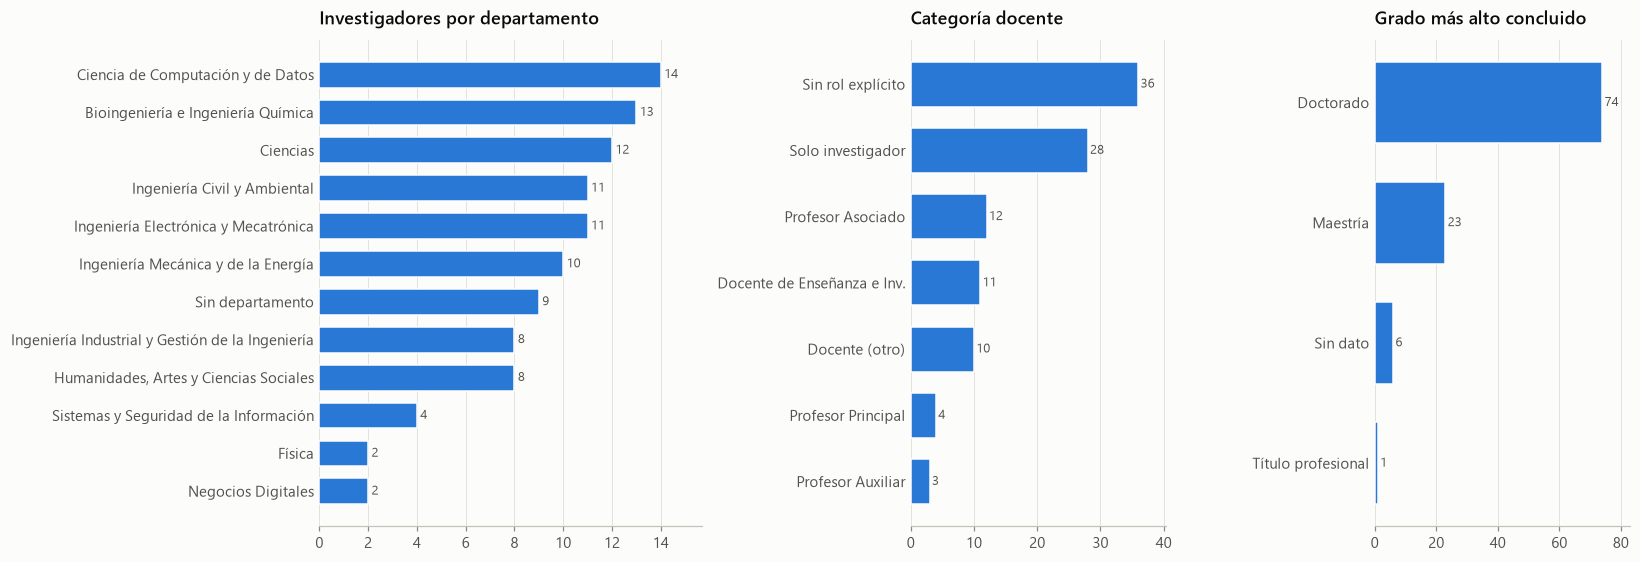

Con cargo directivo: 26 (25%)
Doctorado en curso:  1
Con más de un departamento: 0
Nº de grupos/centros/institutos por persona:
n_grupos_centros
0    46
1    48
2     8
3     2


In [21]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5.2), gridspec_kw={"width_ratios": [1.5, 1, 1]})
barh(axes[0], perfiles.departamento.value_counts(), title="Investigadores por departamento")
barh(axes[1], perfiles.categoria.value_counts(), title="Categoría docente")
g = perfiles.grado_max.value_counts().reindex(ORDEN_GRADO + ["Sin dato"]).dropna()
barh(axes[2], g, title="Grado más alto concluido")
plt.tight_layout(); plt.show()

print(f"Con cargo directivo: {perfiles.directivo.sum()} ({perfiles.directivo.mean():.0%})")
print(f"Doctorado en curso:  {perfiles.doctorado_en_curso.sum()}")
print(f"Con más de un departamento: {(perfiles.n_departamentos > 1).sum()}")
print("Nº de grupos/centros/institutos por persona:")
print(perfiles.n_grupos_centros.value_counts().sort_index().to_string())

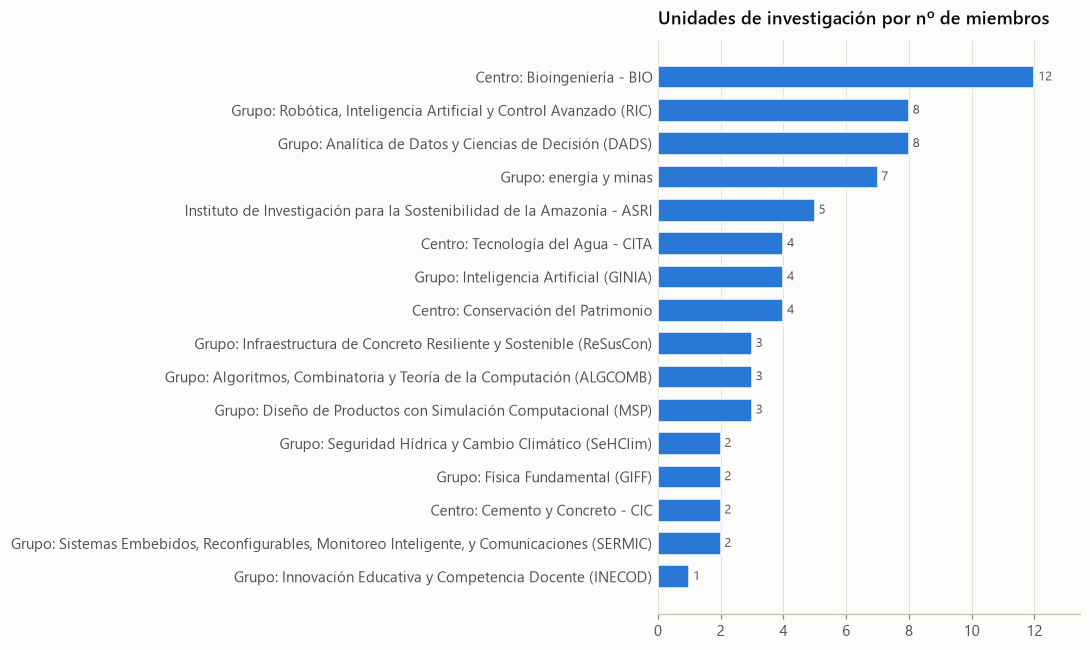

In [22]:
# Unidades de investigación (grupos, centros, institutos) con más miembros en el dataset
unid = cargos[cargos.tipo_unidad.isin(["Grupo", "Centro", "Instituto"])]
unid_n = unid.groupby("unidad").nombre.nunique()
unid_n.index = unid_n.index.str.replace(r"Grupo de [Ii]nvestigación (en |de )?", "Grupo: ", regex=True) \
                           .str.replace(r"Centro de Investigación (en |y |del |de )?", "Centro: ", regex=True)
fig, ax = plt.subplots(figsize=(10, 6))
barh(ax, unid_n.sort_values(ascending=False).head(18), title="Unidades de investigación por nº de miembros")
plt.tight_layout(); plt.show()

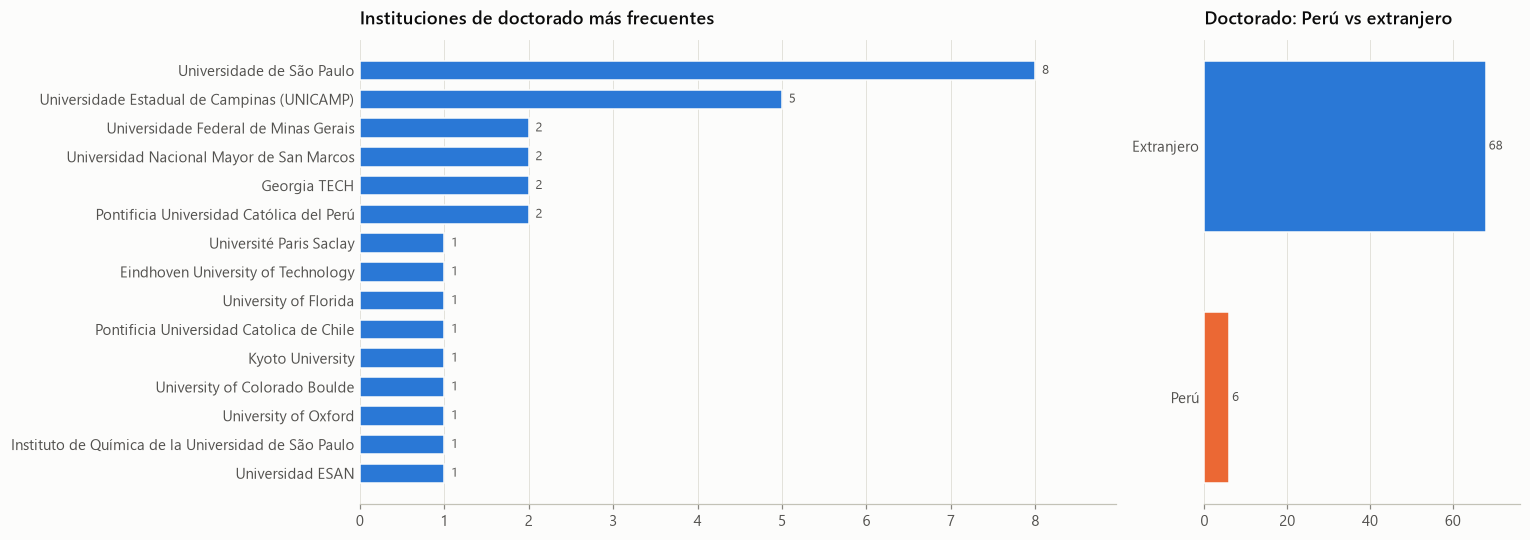

Doctores con institución identificada: 74  (clasificación Perú/extranjero por palabras clave, aproximada)


In [23]:
# ¿Dónde obtuvieron su doctorado?
doc = edu[(edu.grado == "Doctorado") & ~edu.en_curso].drop_duplicates("nombre")
inst = doc.institucion.str.replace(r"\s+", " ", regex=True).str.strip()
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [2.4, 1]})
barh(ax1, inst.value_counts().head(15), title="Instituciones de doctorado más frecuentes")
loc = doc.inst_peru.map({True: "Perú", False: "Extranjero"}).value_counts()
barh(ax2, loc, title="Doctorado: Perú vs extranjero", color=[ORANGE, BLUE])
plt.tight_layout(); plt.show()
print(f"Doctores con institución identificada: {len(doc)}  "
      f"(clasificación Perú/extranjero por palabras clave, aproximada)")

**Estructura organizativa y formación**

- Hay **12 departamentos**. Los más representados son Ciencia de la Computación y de Datos (14), Bioingeniería e Ingeniería Química (13) y Ciencias (12). **9 personas no tienen departamento**: sus cargos solo mencionan un centro, instituto o la propia universidad (directivos, investigadores de centros).
- **La categoría docente es poco fiable**: en 36 perfiles el cargo es solo `Departamento de X`, sin rol, y 28 figuran solo como "Investigador". Solo 19 declaran una categoría formal (4 principales, 12 asociados y 3 auxiliares). No conviene usarla para analizar la jerarquía académica.
- El 25 % tiene algún cargo directivo (dirección, decanato, coordinación de grupo). Ninguna persona pertenece a más de un departamento.
- **El 71 % (74) tiene doctorado concluido** y el 22 % maestría. La única persona con doctorado en curso coincide con su perfil ("candidata a doctora").
- El 44 % no declara pertenecer a ningún grupo o centro. La unidad más grande es el **Centro de Investigación en Bioingeniería (12 miembros)**, seguida de los grupos RIC y DADS (8 cada uno).
- **La gran mayoría de los doctorados se obtuvo en el extranjero** (≈ 92 %, clasificación heurística por palabras clave). Brasil es el destino más frecuente (USP, UNICAMP, UFMG).

### 4.2 RENACYT

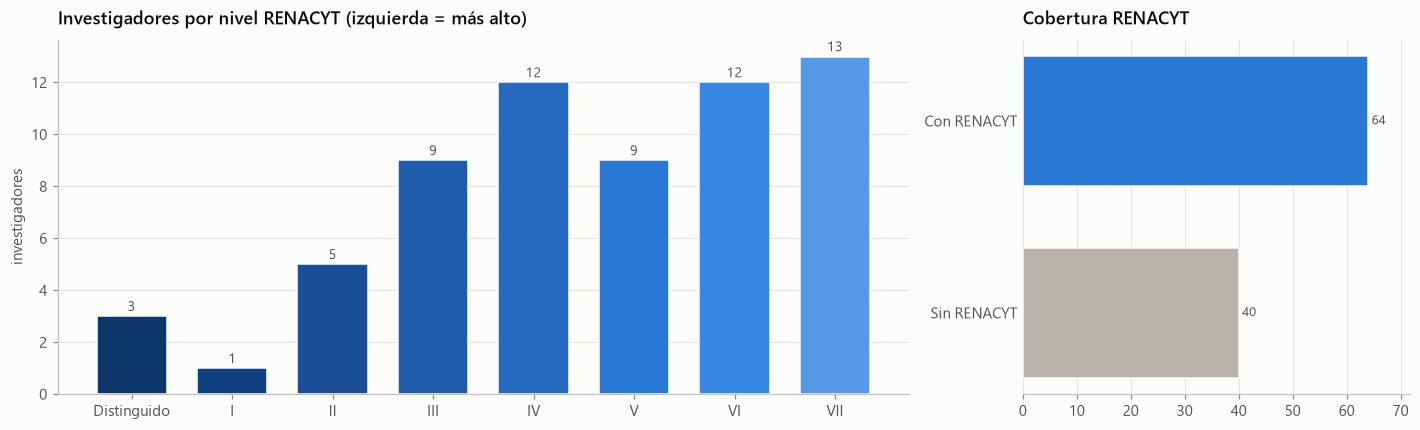

renacyt,Distinguido,I,II,III,IV,V,VI,VII,Sin RENACYT
departamento,,,,,,,,,
Bioingeniería e Ingeniería Química,1,1,1,3,1,2,0,1,3
Ciencia de Computación y de Datos,0,0,0,1,2,2,1,3,5
Ciencias,1,0,0,1,1,2,0,0,7
Física,1,0,0,0,0,0,0,0,1
"Humanidades, Artes y Ciencias Sociales",0,0,0,0,1,0,0,3,4
Ingeniería Civil y Ambiental,0,0,1,3,2,0,2,1,2
Ingeniería Electrónica y Mecatrónica,0,0,0,0,0,2,5,3,1
Ingeniería Industrial y Gestión de la Ingeniería,0,0,0,1,1,0,1,0,5
Ingeniería Mecánica y de la Energía,0,0,3,0,1,0,2,1,3


In [24]:
orden = ["Distinguido", "I", "II", "III", "IV", "V", "VI", "VII"]
r = perfiles.renacyt.value_counts().reindex(orden, fill_value=0)
ramp = BLUES_RAMP[3:][::-1][:len(orden)][::-1]   # ordinal: más oscuro = nivel más alto
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4), gridspec_kw={"width_ratios": [2.2, 1]})
ax1.bar(r.index, r.values, color=ramp[::-1], width=0.7, edgecolor=SURFACE)
for x, v in enumerate(r.values):
    ax1.text(x, v + 0.2, str(v), ha="center", fontsize=9, color=INK2)
ax1.set_title("Investigadores por nivel RENACYT (izquierda = más alto)"); ax1.grid(axis="x", visible=False)
ax1.set_ylabel("investigadores")
c = perfiles.renacyt.eq("Sin RENACYT").map({False: "Con RENACYT", True: "Sin RENACYT"}).value_counts()
barh(ax2, c, color=[OTHER, BLUE], title="Cobertura RENACYT")
plt.tight_layout(); plt.show()
display(pd.crosstab(perfiles.departamento, perfiles.renacyt).reindex(columns=orden + ["Sin RENACYT"], fill_value=0))

**RENACYT**

- El 62 % (64) tiene calificación RENACYT. Había **13 etiquetas distintas** (mayúsculas, "Nivel Investigador Distinguido", y la nomenclatura nueva Carlos Monge / María Rostworowski) que se unificaron en 8 niveles.
- La distribución pesa hacia los niveles intermedios y bajos: IV, VI y VII concentran 37 de 64 personas, y solo hay 3 Distinguidos y 1 Nivel I.
- Quienes no tienen RENACYT se concentran en Ciencias (7 de 12), Industrial (5 de 8) y Computación (5 de 14). En cambio, Electrónica y Mecatrónica tiene RENACYT en 10 de 11 perfiles, casi todos en los niveles V a VII.

### 4.3 Identificadores y presencia digital

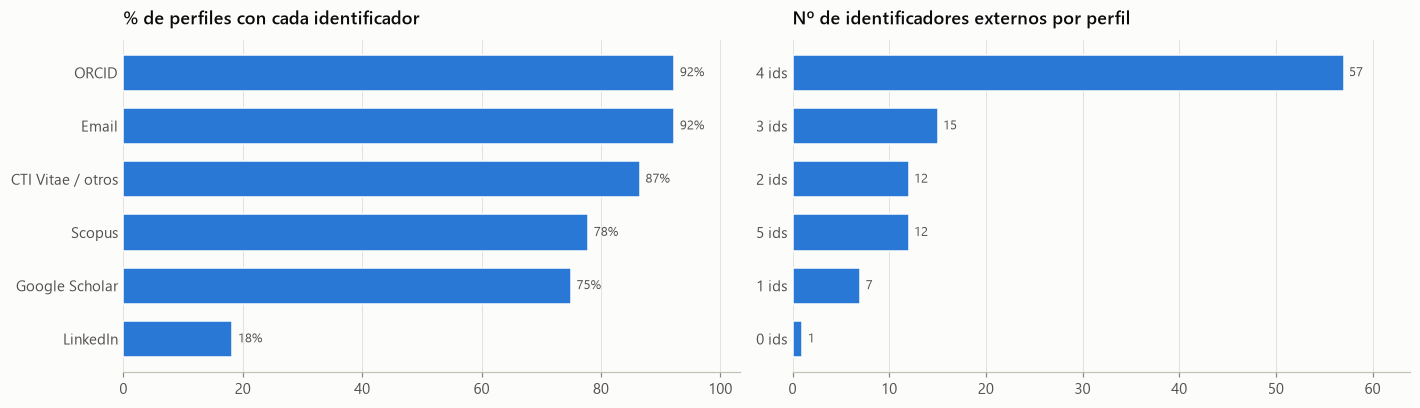

Dominios en 'otros_links':
0
dina.concytec.gob.pe        49
ctivitae.concytec.gob.pe    41
sashwattanay.github.io       1


In [25]:
ids = perfiles[["tiene_email", "tiene_orcid", "tiene_scopus", "tiene_google_scholar",
                "tiene_otros_links", "tiene_linkedin"]].mean() * 100
ids.index = ["Email", "ORCID", "Scopus", "Google Scholar", "CTI Vitae / otros", "LinkedIn"]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 3.8))
barh(ax1, ids, fmt="{:.0f}%", title="% de perfiles con cada identificador")
barh(ax2, perfiles.n_identificadores.value_counts().sort_index(ascending=False).rename(lambda i: f"{i} ids"),
     title="Nº de identificadores externos por perfil")
plt.tight_layout(); plt.show()

dominios = perfiles.otros_links.map(split_pipe).explode().dropna().str.extract(r"https?://([^/]+)")[0]
print("Dominios en 'otros_links':"); print(dominios.value_counts().head(8).to_string())

### 4.4 Métricas bibliométricas: citas, índice h y nº de publicaciones

,count,mean,std,min,10%,25%,50%,75%,90%,max
citas,78.0,1319.2,7578.3,1.0,12.7,37.2,145.5,420.5,745.3,65585.0
indice_h,78.0,8.6,15.2,1.0,2.0,3.0,5.5,8.0,12.6,122.0
n_publicaciones,104.0,28.6,118.7,0.0,0.0,1.8,7.0,17.2,39.7,1132.0
n_temas,104.0,3.8,2.6,0.0,0.0,2.8,3.0,5.0,7.0,15.0
len_perfil,104.0,798.1,475.4,0.0,214.3,491.0,760.5,1049.0,1381.6,1951.0
n_grupos_centros,104.0,0.7,0.7,0.0,0.0,0.0,1.0,1.0,1.0,3.0


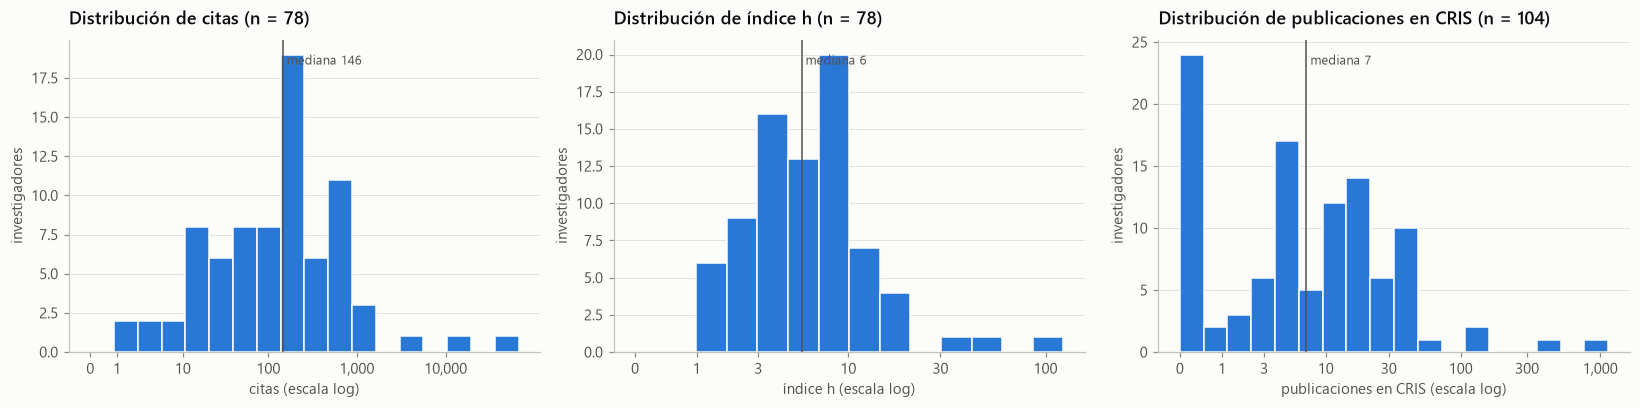

Investigadores con 0 publicaciones en CRIS: 24
Asimetría (skew): {'citas': 8.21, 'indice_h': 6.1, 'n_publicaciones': 8.36}


In [26]:
num = ["citas", "indice_h", "n_publicaciones", "n_temas", "len_perfil", "n_grupos_centros"]
display(perfiles[num].describe(percentiles=[.1, .25, .5, .75, .9]).T.round(1))

fig, axes = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, col, lab in zip(axes, ["citas", "indice_h", "n_publicaciones"],
                        ["citas", "índice h", "publicaciones en CRIS"]):
    x = perfiles[col].dropna()
    hist_log(ax, x, nbins=18 if col != "indice_h" else 14)
    med = np.log10(x.median() + 1)
    ax.axvline(med, color=INK2, lw=1)
    ax.text(med, ax.get_ylim()[1] * 0.92, f" mediana {x.median():.0f}", color=INK2, fontsize=8.5)
    ax.set_title(f"Distribución de {lab} (n = {len(x)})"); ax.set_xlabel(lab + " (escala log)")
    ax.set_ylabel("investigadores")
plt.tight_layout(); plt.show()

print("Investigadores con 0 publicaciones en CRIS:", (perfiles.n_publicaciones == 0).sum())
print("Asimetría (skew):", perfiles[["citas", "indice_h", "n_publicaciones"]].skew().round(2).to_dict())

In [27]:
# Top 10 por cada métrica
top = pd.concat({m: perfiles.nlargest(10, m)[["nombre", m]].reset_index(drop=True)
                 for m in ["citas", "indice_h", "n_publicaciones"]}, axis=1)
top

citas                                  indice_h                           n_publicaciones                
                            nombre    citas                           nombre indice_h                           nombre n_publicaciones
0  Diego Alejandro Milanés Carreño  65585.0  Diego Alejandro Milanés Carreño    122.0  Diego Alejandro Milanés Carreño            1132
1    Evgenii Vladimirovich Shmanin  15052.0    Evgenii Vladimirovich Shmanin     60.0    Evgenii Vladimirovich Shmanin             441
2       José Luis Mantari Laureano   4411.0       José Luis Mantari Laureano     33.0       José Luis Mantari Laureano             128
3         José Tomás Gálvez Ghersi   1551.0      Juan Carlos Rodríguez Reyes     18.0     Deyby Huamanchahua Canchanya             115
4      Heinner Hilario Guio Chunga   1040.0      Heinner Hilario Guio Chunga     17.0      Heinner Hilario Guio Chunga              68
5           Ada Congrains Castillo    904.0                 Pedro Rau Lavado     16.0                       Wangdo Kim              47
6      Juan Carlos Rodríguez Reyes    825.0             Samuel Charca Mamani     15.0       Emir Augusto Vela Saavedra              44
7                    Aoife Bennett    753.0                       Wangdo Kim     14.0      Juan Carlos Rodríguez Reyes              43
8                 Pedro Rau Lavado    742.0     Deyby Huamanchahua Canchanya     12.0                Oscar Ramos Ponce              42
9               José Ramos Saravia    680.0            Monica C. Santa-Maria     12.0             Samuel Charca Mamani              40

**Distribuciones bibliométricas**

- Las tres métricas son **muy asimétricas** (*skew* entre 6 y 8): la mediana es de 146 citas, 5,5 de índice h y 7 publicaciones, pero los máximos son 65 585 citas, h = 122 y 1132 publicaciones. **Hay que usar escala logarítmica o rangos** en cualquier visualización.
- Los dos valores extremos son los físicos de colaboraciones masivas (Milanés y Shmanin). Sin ellos, el máximo es José Luis Mantari (4411 citas, h = 33, 128 publicaciones).
- **24 investigadores (23 %) no tienen ninguna publicación en CRIS**: probablemente docentes con perfil recién creado o enfocados en la enseñanza (ver 11.1).
- Citas e índice h solo existen para 78 personas, las indexadas en Scopus.

## 5. Perfiles — relaciones entre variables

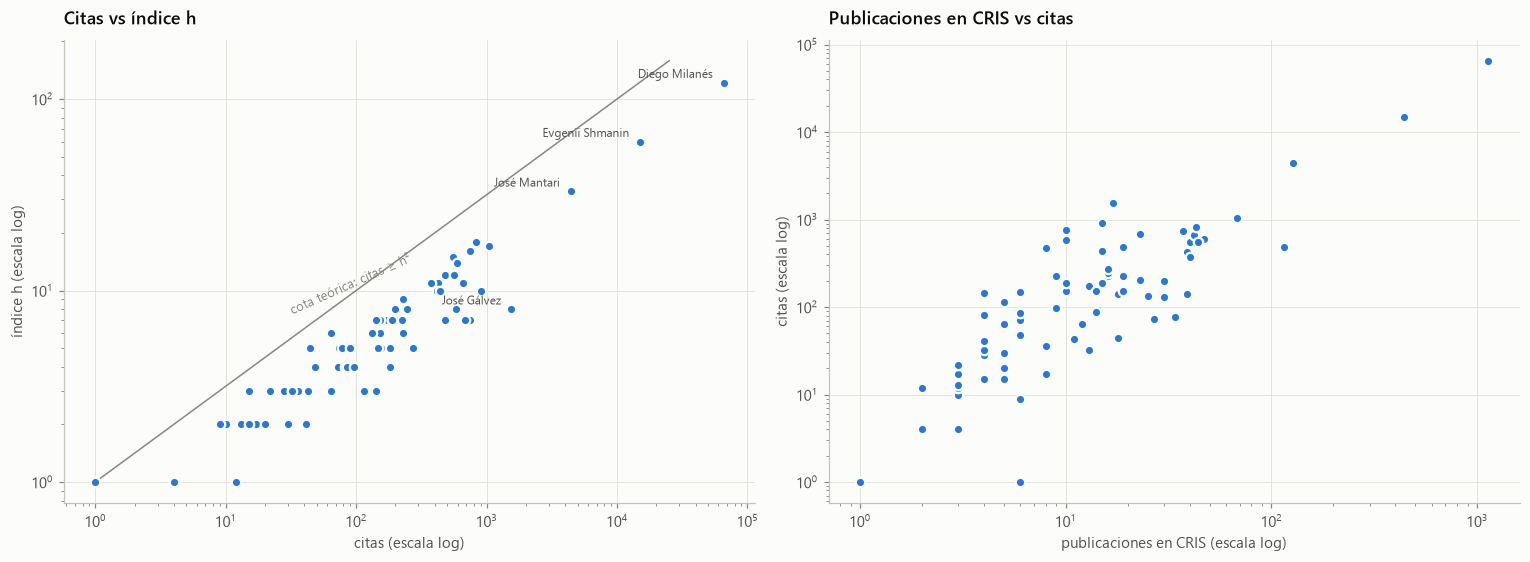

Spearman citas–h: 0.936 | Spearman pubs–citas: 0.786


In [28]:
d = perfiles.dropna(subset=["citas", "indice_h"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5.2))

ax1.scatter(d.citas, d.indice_h, s=38, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
hh = np.linspace(1, d.indice_h.max() * 1.3, 100)
ax1.plot(hh ** 2, hh, color=MUTED, lw=1, zorder=2)
ax1.text(30, 7.5, "cota teórica: citas ≥ h²", color=MUTED, fontsize=8.5, rotation=24)
ax1.set_xscale("log"); ax1.set_yscale("log")
for _, r in d.nlargest(4, "citas").iterrows():
    ax1.annotate(corto(r.nombre), (r.citas, r.indice_h),
                 xytext=(-7, 3), textcoords="offset points", ha="right", fontsize=8, color=INK2)
ax1.set_xlabel("citas (escala log)"); ax1.set_ylabel("índice h (escala log)"); ax1.set_title("Citas vs índice h")

d2 = perfiles.dropna(subset=["citas"])
ax2.scatter(d2.n_publicaciones, d2.citas, s=38, color=BLUE, edgecolor=SURFACE, linewidth=1.5, zorder=3)
ax2.set_xscale("log"); ax2.set_yscale("log")
ax2.set_xlabel("publicaciones en CRIS (escala log)"); ax2.set_ylabel("citas (escala log)")
ax2.set_title("Publicaciones en CRIS vs citas")
plt.tight_layout(); plt.show()

print("Spearman citas–h:", round(d.citas.corr(d.indice_h, method="spearman"), 3),
      "| Spearman pubs–citas:", round(d2.n_publicaciones.corr(d2.citas, method="spearman"), 3))

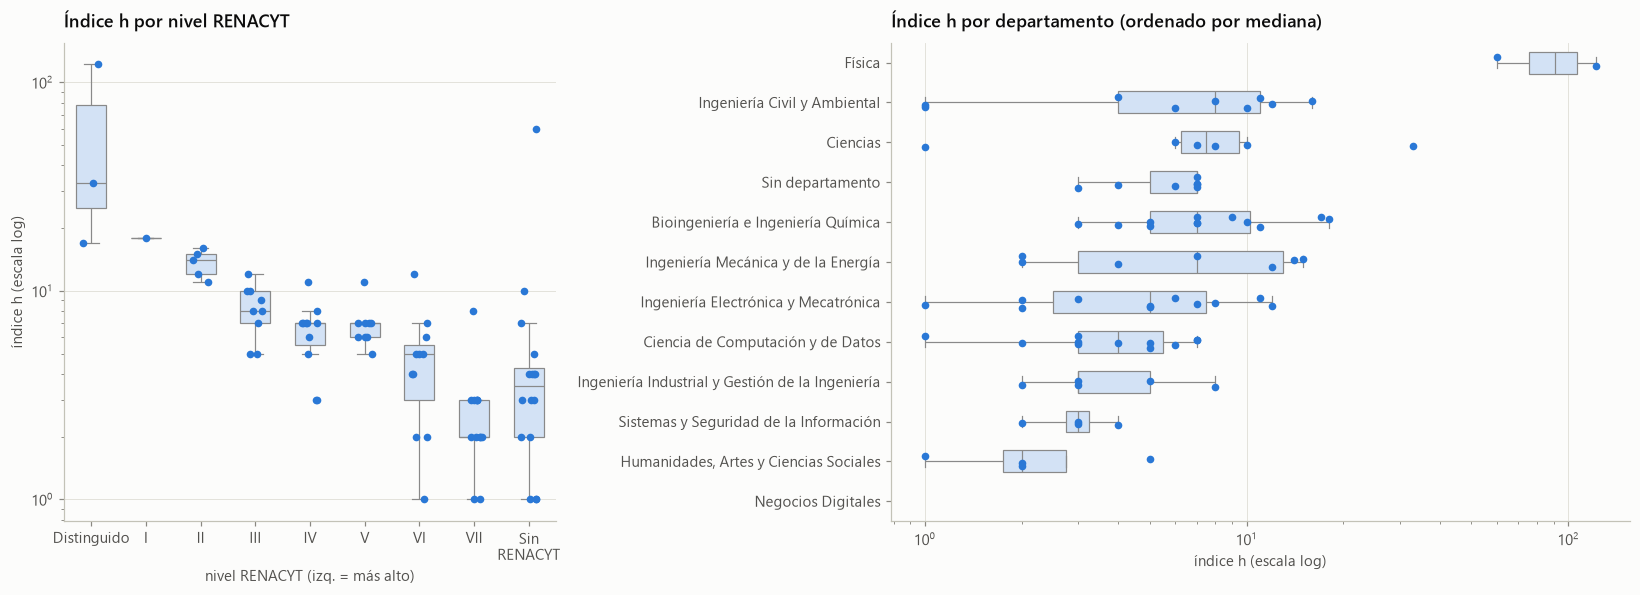

Spearman nivel RENACYT (0 = mejor) vs índice h: -0.791


In [29]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1, 1.5]})
orden_r = ["Distinguido", "I", "II", "III", "IV", "V", "VI", "VII", "Sin RENACYT"]
sns.boxplot(data=perfiles, x="renacyt", y="indice_h", order=orden_r, color="#cde2fb", width=.55,
            fliersize=0, linewidth=0.8, ax=axes[0])
sns.stripplot(data=perfiles, x="renacyt", y="indice_h", order=orden_r, color=BLUE, size=5, jitter=.15, ax=axes[0])
axes[0].set_title("Índice h por nivel RENACYT"); axes[0].set_xlabel("nivel RENACYT (izq. = más alto)")
axes[0].set_ylabel("índice h (escala log)"); axes[0].grid(axis="x", visible=False); axes[0].set_yscale("log")
axes[0].set_xticks(range(len(orden_r)), [o.replace("Sin RENACYT", "Sin\nRENACYT") for o in orden_r])

od = perfiles.groupby("departamento").indice_h.median().sort_values(ascending=False).index
sns.boxplot(data=perfiles, y="departamento", x="indice_h", order=od, color="#cde2fb", width=.55,
            fliersize=0, linewidth=0.8, ax=axes[1])
sns.stripplot(data=perfiles, y="departamento", x="indice_h", order=od, color=BLUE, size=5, jitter=.15, ax=axes[1])
axes[1].set_title("Índice h por departamento (ordenado por mediana)"); axes[1].set_ylabel("")
axes[1].set_xlabel("índice h (escala log)"); axes[1].grid(axis="y", visible=False); axes[1].set_xscale("log")
plt.tight_layout(); plt.show()

print("Spearman nivel RENACYT (0 = mejor) vs índice h:",
      round(perfiles.renacyt_nivel.corr(perfiles.indice_h, method="spearman"), 3))

In [30]:
# Métricas por categoría docente y grado
agg = lambda g: perfiles.groupby(g).agg(n=("nombre", "size"), h_mediana=("indice_h", "median"),
                                        citas_mediana=("citas", "median"), pubs_mediana=("n_publicaciones", "median"),
                                        con_renacyt=("renacyt_nivel", lambda s: f"{s.notna().mean():.0%}"))
display(agg("categoria").sort_values("h_mediana", ascending=False))
display(agg("grado_max").reindex(ORDEN_GRADO + ["Sin dato"]).dropna(how="all"))

,n,h_mediana,citas_mediana,pubs_mediana,con_renacyt
categoria,,,,,
Profesor Principal,4,18.0,825.0,41.5,75%
Profesor Asociado,12,8.0,480.0,19.0,92%
Sin rol explícito,36,5.5,120.5,2.0,36%
Solo investigador,28,5.0,132.0,10.0,64%
Docente (otro),10,5.0,148.0,11.0,80%
Docente de Enseñanza e Inv.,11,3.0,64.0,5.0,73%
Profesor Auxiliar,3,2.0,15.0,3.0,100%


,n,h_mediana,citas_mediana,pubs_mediana,con_renacyt
grado_max,,,,,
Doctorado,74.0,6.0,153.0,13.0,76%
Maestría,23.0,2.5,14.0,0.0,26%
Título profesional,1.0,NaN,NaN,0.0,0%
Sin dato,6.0,2.0,18.5,0.0,33%


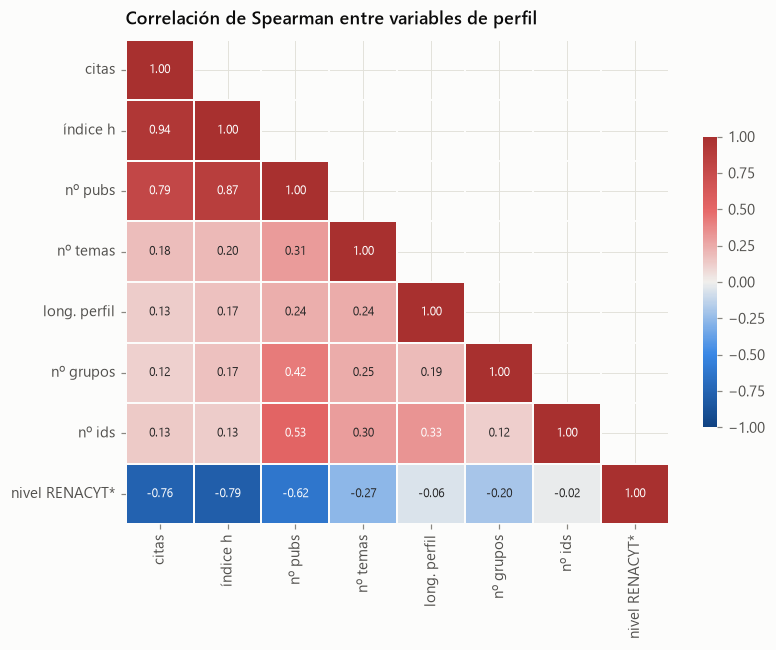

* nivel RENACYT: 0 = Distinguido … 7 = Nivel VII → una correlación negativa significa mejor nivel


In [31]:
cols = {"citas": "citas", "indice_h": "índice h", "n_publicaciones": "nº pubs", "n_temas": "nº temas",
        "len_perfil": "long. perfil", "n_grupos_centros": "nº grupos", "n_identificadores": "nº ids",
        "renacyt_nivel": "nivel RENACYT*"}
corr = perfiles[list(cols)].rename(columns=cols).corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6))
mask = np.triu(np.ones_like(corr, bool), 1)
sns.heatmap(corr, mask=mask, cmap=CMAP_DIV, vmin=-1, vmax=1, center=0, annot=True, fmt=".2f",
            annot_kws={"fontsize": 8}, linewidths=1, linecolor=SURFACE, cbar_kws={"shrink": .6}, ax=ax)
ax.set_title("Correlación de Spearman entre variables de perfil")
plt.tight_layout(); plt.show()
print("* nivel RENACYT: 0 = Distinguido … 7 = Nivel VII → una correlación negativa significa mejor nivel")

**Relaciones**

- **Citas e índice h están casi perfectamente ordenados** (Spearman 0,94) y todos los puntos respetan la cota teórica citas ≥ h², lo que confirma la coherencia interna de los datos. Publicaciones y citas también se relacionan con fuerza (0,79).
- **El nivel RENACYT sigue muy de cerca la bibliometría** (Spearman −0,79 con el índice h): cada nivel tiene un índice h más alto que el siguiente, con poco solapamiento entre los niveles II a VII. Era de esperar, porque la calificación RENACYT se basa en buena parte en la producción indexada.
- Excepción notable: Evgenii Shmanin tiene h = 60 sin RENACYT.
- Por departamento, Física queda fuera de escala por las colaboraciones masivas. Les siguen Ingeniería Civil y Ambiental y Ciencias, mientras que Humanidades y Sistemas tienen los índices h más bajos (Negocios Digitales no tiene datos de Scopus). Esto refleja en parte **culturas de publicación distintas** (libros, revistas no indexadas en Scopus) y no solo diferencias de productividad.
- Los profesores principales tienen la mediana más alta (h = 18), luego los asociados (h = 8). El doctorado marca una diferencia clara: h mediano de 6 frente a 2,5 con maestría, y 76 % con RENACYT frente a 26 %.
- La "presencia digital" (nº de identificadores, longitud del perfil) se asocia con el número de publicaciones pero **casi nada con las citas** (0,13).

## 6. Publicaciones

### 6.1 Evolución temporal

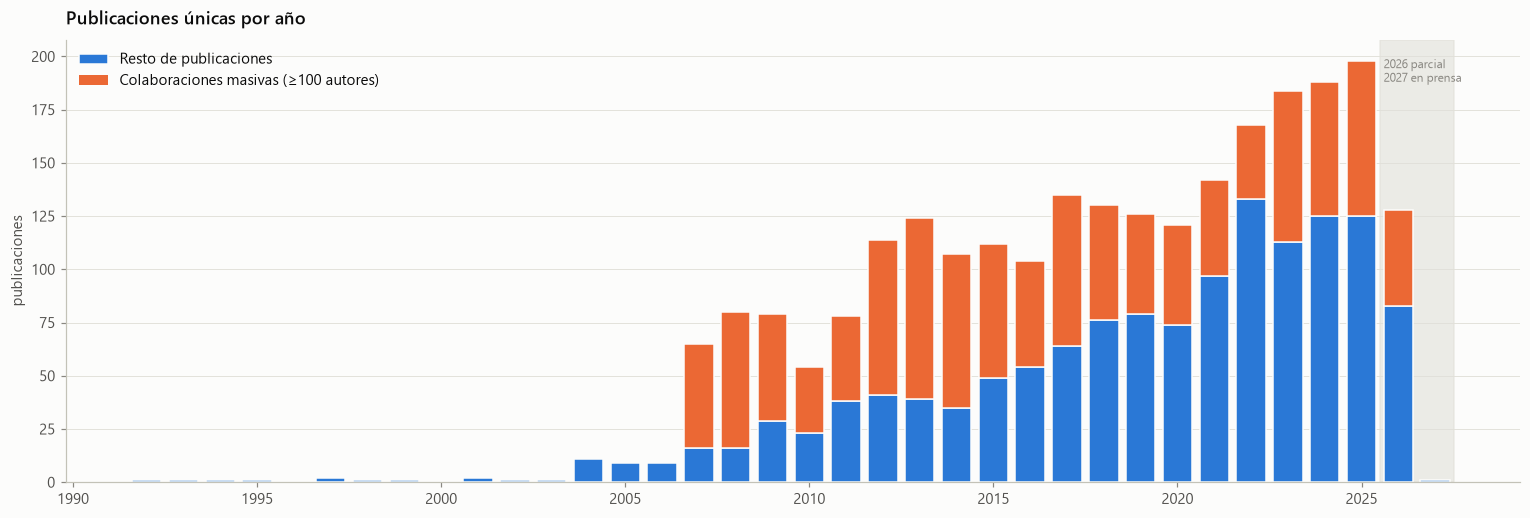

anio_num                               2016  2017  2018  2019  2020  2021  2022  2023  2024  2025  2026  2027
mega                                                                                                         
Resto de publicaciones                   54    64    76    79    74    97   133   113   125   125    83     1
Colaboraciones masivas (≥100 autores)    50    71    54    47    47    45    35    71    63    73    45     0


In [32]:
MEGA_LAB = "Colaboraciones masivas (≥100 autores)"
anual = pubs_u.groupby(["anio_num", "mega"]).size().unstack(fill_value=0).reindex(columns=[False, True], fill_value=0).rename(
    columns={False: "Resto de publicaciones", True: MEGA_LAB})
anual = anual.reindex(range(anual.index.min(), anual.index.max() + 1), fill_value=0)

fig, ax = plt.subplots(figsize=(14, 4.8))
bottom = np.zeros(len(anual))
for col, color in zip(anual.columns, [BLUE, ORANGE]):
    ax.bar(anual.index, anual[col], bottom=bottom, color=color, width=0.8, edgecolor=SURFACE,
           linewidth=[1 if v > 0 else 0 for v in anual[col]], label=col)
    bottom += anual[col].values
ax.axvspan(2025.5, anual.index.max() + 0.5, color=GRID, alpha=.6, zorder=0)
ax.text(2025.6, bottom.max() * 0.95, "2026 parcial\n2027 en prensa", fontsize=8, color=MUTED)
ax.set_title("Publicaciones únicas por año"); ax.set_ylabel("publicaciones"); ax.grid(axis="x", visible=False)
ax.legend(loc="upper left")
plt.tight_layout(); plt.show()
print(anual.tail(12).T.to_string())

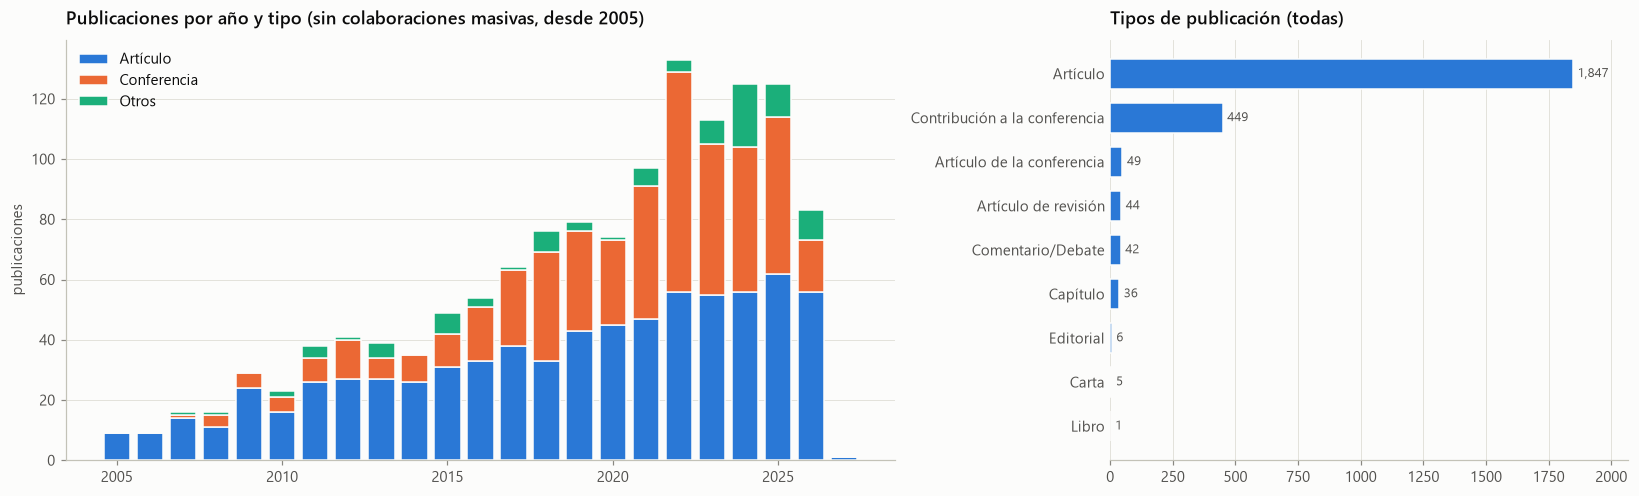

Precisión de las fechas por tipo de publicación (%):


precision_fecha,año,día,mes
tipo,,,
Artículo,11.0,60.0,29.0
Artículo de la conferencia,76.0,22.0,2.0
Artículo de revisión,16.0,36.0,48.0
Capítulo,56.0,36.0,8.0
Carta,40.0,40.0,20.0
Comentario/Debate,2.0,62.0,36.0
Contribución a la conferencia,72.0,21.0,7.0
Editorial,50.0,17.0,33.0
Libro,100.0,0.0,0.0


In [33]:
# Sin colaboraciones masivas: composición por tipo
TIPO3 = {"Artículo": "Artículo", "Contribución a la conferencia": "Conferencia",
         "Artículo de la conferencia": "Conferencia"}
r = pubs_u[~pubs_u.mega].assign(tipo3=lambda d: d.tipo.map(TIPO3).fillna("Otros"))
t = r.groupby(["anio_num", "tipo3"]).size().unstack(fill_value=0)[["Artículo", "Conferencia", "Otros"]]
t = t.loc[2005:]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(len(t))
for col, color in zip(t.columns, [BLUE, ORANGE, AQUA]):
    ax1.bar(t.index, t[col], bottom=bottom, color=color, width=.8, edgecolor=SURFACE, linewidth=1, label=col)
    bottom += t[col].values
ax1.set_title("Publicaciones por año y tipo (sin colaboraciones masivas, desde 2005)")
ax1.legend(loc="upper left"); ax1.grid(axis="x", visible=False); ax1.set_ylabel("publicaciones")

barh(ax2, pubs_u.tipo.value_counts(), title="Tipos de publicación (todas)")
plt.tight_layout(); plt.show()

print("Precisión de las fechas por tipo de publicación (%):")
display((pd.crosstab(pubs_u.tipo, pubs_u.precision_fecha, normalize="index") * 100).round(0))

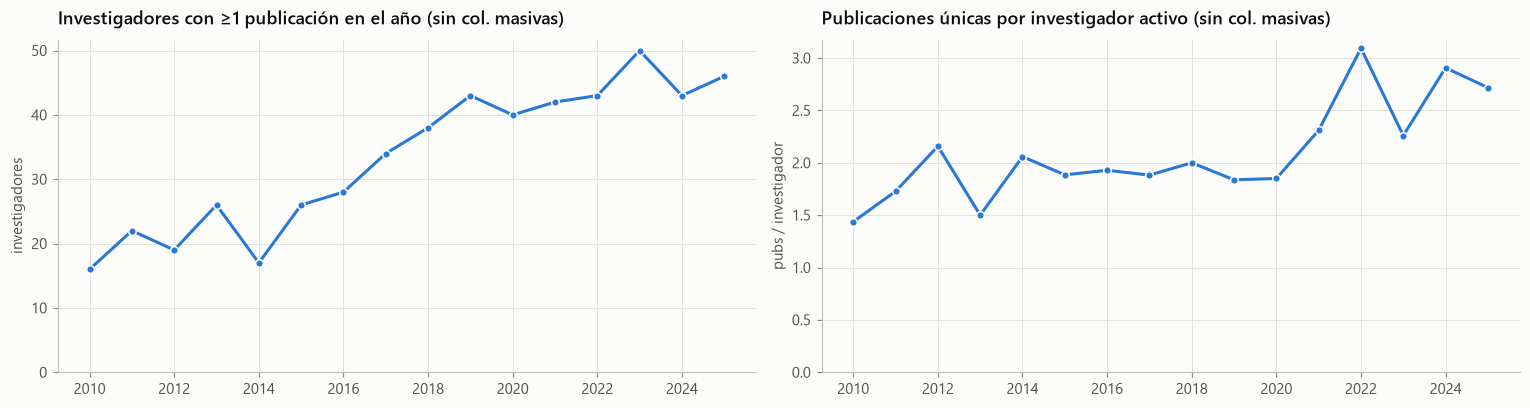

In [34]:
# Investigadores activos por año y productividad media
act = pubs[~pubs.mega].groupby("anio_num").agg(activos=("investigador", "nunique"), pubs=("url", "nunique"))
act = act.loc[2010:2025]
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 3.8))
ax1.plot(act.index, act.activos, color=BLUE, marker="o", ms=5, mec=SURFACE)
ax1.set_title("Investigadores con ≥1 publicación en el año (sin col. masivas)"); ax1.set_ylabel("investigadores")
ax2.plot(act.index, act.pubs / act.activos, color=BLUE, marker="o", ms=5, mec=SURFACE)
ax2.set_title("Publicaciones únicas por investigador activo (sin col. masivas)"); ax2.set_ylabel("pubs / investigador")
for a in (ax1, ax2): a.set_ylim(bottom=0)
plt.tight_layout(); plt.show()

**Evolución temporal**

- Sin las colaboraciones masivas, la producción **pasa de ~54 publicaciones/año en 2016 a un pico de 133 en 2022**, y se mantiene en ~125/año en 2024–2025. 2026 va por 83 a octubre (año incompleto) y hay 1 artículo ya fechado en 2027 (en prensa).
- Las colaboraciones masivas aportan un flujo estable de ~45–75 publicaciones/año desde 2007. **Antes de 2010 dominan la serie**, y si no se separan dan una impresión falsa de producción temprana.
- El crecimiento 2017–2022 se apoya en buena parte en **contribuciones a conferencias**. Los artículos de revista crecen de forma más sostenida (~30 en 2015 → ~60 en 2025).
- Los investigadores activos por año suben de 16 (2010) a 45–50 (2023–2025). Las publicaciones por investigador activo, estables en ~1,9 hasta 2020, suben a 2,3–3,1 desde 2021.
- ⚠️ CRIS incluye publicaciones **anteriores a la llegada de cada investigador a UTEC**, así que la serie refleja carreras individuales y no estrictamente producción con filiación UTEC. La sección 7.1 separa ambas con el campo de filiación del detalle.
- ⚠️ El 72–76 % de las conferencias solo tiene el año, sin mes ni día, así que **no conviene analizar por mes**.

### 6.2 Concentración de la producción

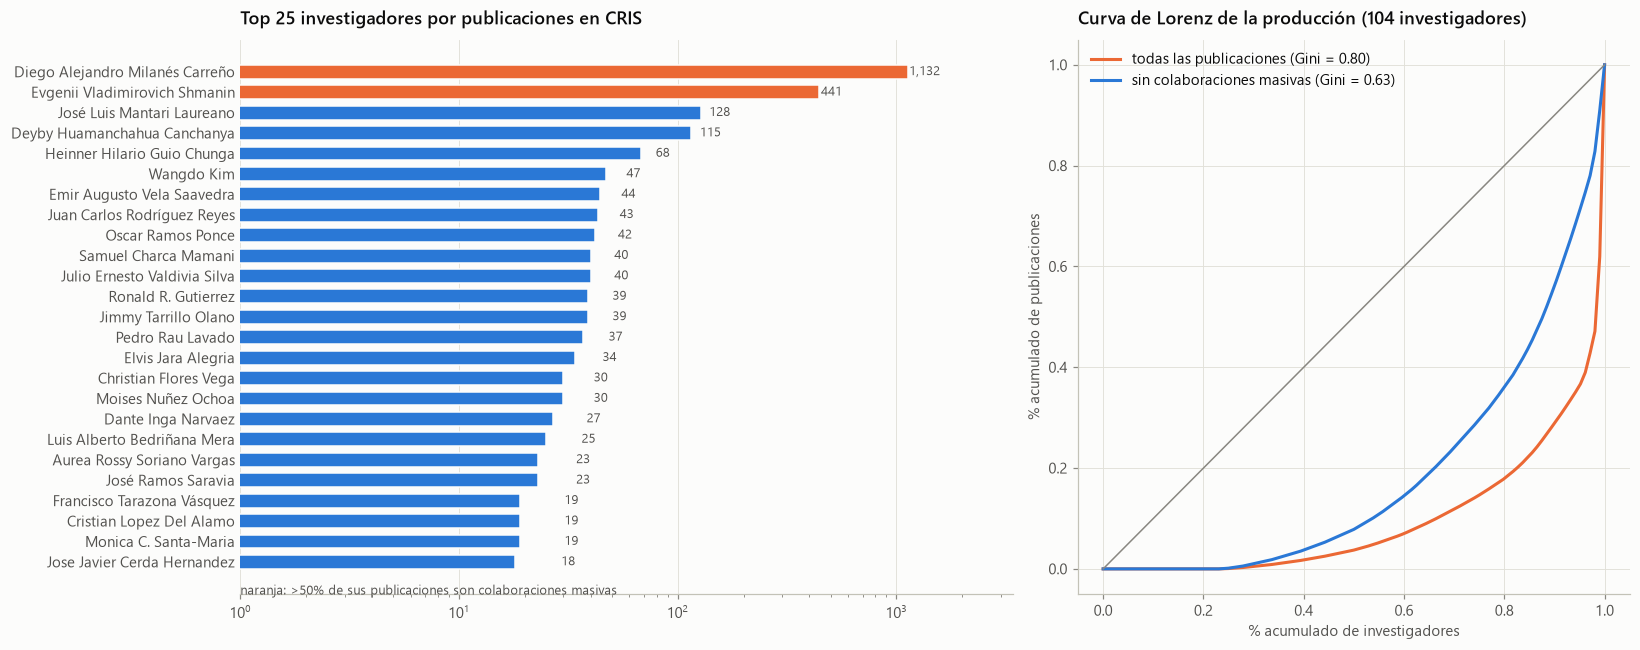

Sin colaboraciones masivas: el 10% más productivo concentra 43% de las publicaciones; el 50% menos productivo, 8%.


In [35]:
n = perfiles.set_index("nombre").n_publicaciones.sort_values(ascending=False)
n_sin = (pubs[~pubs.mega].groupby("investigador").size().reindex(n.index, fill_value=0)
         .sort_values(ascending=False))
pct_mega = pubs.groupby("investigador").mega.mean()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6), gridspec_kw={"width_ratios": [1.4, 1]})
top25 = n.head(25)
barh(ax1, top25, color=[ORANGE if pct_mega.get(i, 0) > .5 else BLUE for i in top25.sort_values().index],
     title="Top 25 investigadores por publicaciones en CRIS")
ax1.set_xscale("log"); ax1.set_xlim(1, top25.max() * 3)
ax1.text(1, -1.6, "naranja: >50% de sus publicaciones son colaboraciones masivas", fontsize=8.5, color=INK2)

for serie, lab, color in [(n, "todas las publicaciones", ORANGE), (n_sin, "sin colaboraciones masivas", BLUE)]:
    x = np.sort(serie.values)
    cum = np.r_[0, np.cumsum(x) / x.sum()]
    ax2.plot(np.linspace(0, 1, len(cum)), cum, color=color, label=f"{lab} (Gini = {gini(x):.2f})")
ax2.plot([0, 1], [0, 1], color=MUTED, lw=1)
ax2.set_title("Curva de Lorenz de la producción (104 investigadores)"); ax2.set_xlabel("% acumulado de investigadores")
ax2.set_ylabel("% acumulado de publicaciones"); ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()

s = n_sin
print(f"Sin colaboraciones masivas: el 10% más productivo concentra {s.head(int(len(s) * .1)).sum() / s.sum():.0%} "
      f"de las publicaciones; el 50% menos productivo, {s.tail(len(s) // 2).sum() / s.sum():.0%}.")

### 6.3 Tamaño de los equipos de autores

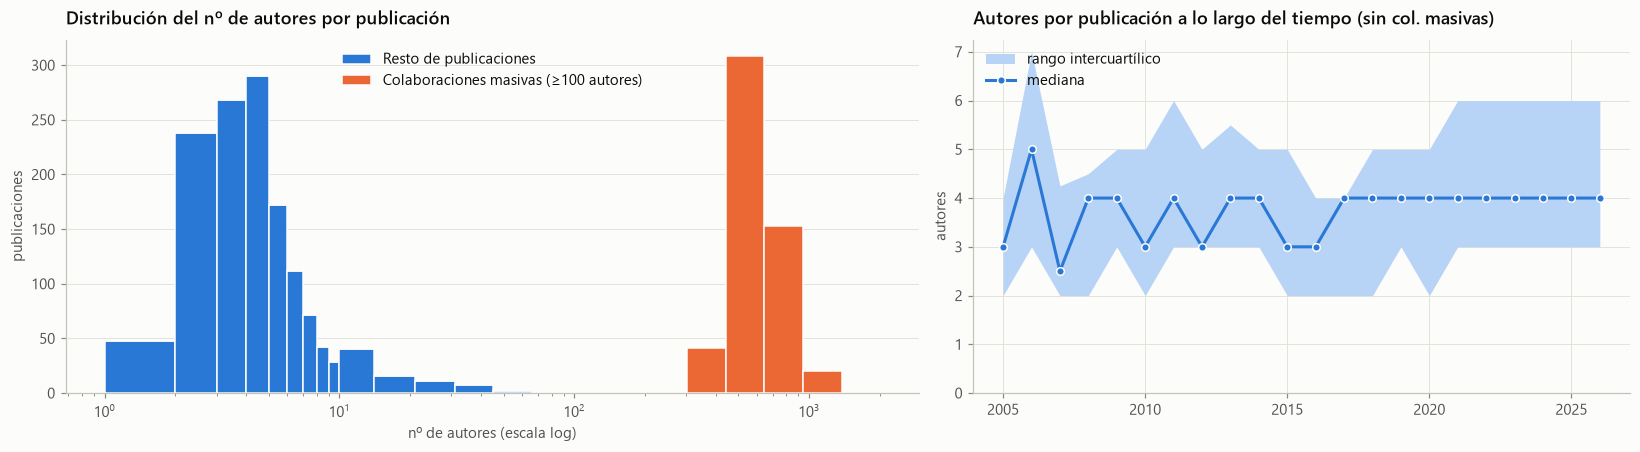

Publicaciones con autor único (sin col. masivas): 3.6%
Con firma colectiva (solo el consorcio, nº de autores desconocido): 609


,count,mean,std,min,25%,50%,75%,max
mega,,,,,,,,
Colaboración masiva,525.0,611.6,151.4,202.0,527.0,588.0,694.0,2011.0
Resto,1345.0,4.8,4.4,1.0,3.0,4.0,5.0,49.0


In [36]:
na = pubs_u.dropna(subset=["n_autores"])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
bins = np.unique(np.r_[np.arange(1, 11), np.logspace(1, np.log10(na.n_autores.max() + 1), 15).astype(int)])
ax1.hist([na[~na.mega].n_autores, na[na.mega].n_autores], bins=bins, color=[BLUE, ORANGE], stacked=True,
         label=["Resto de publicaciones", MEGA_LAB], edgecolor=SURFACE, linewidth=1)
ax1.set_xscale("log"); ax1.set_xlabel("nº de autores (escala log)"); ax1.set_ylabel("publicaciones")
ax1.set_title("Distribución del nº de autores por publicación"); ax1.legend(); ax1.grid(axis="x", visible=False)

q = na[~na.mega].groupby("anio_num").n_autores.quantile([.25, .5, .75]).unstack().loc[2005:2026]
ax2.fill_between(q.index, q[.25], q[.75], color=BLUES_RAMP[1], lw=0, label="rango intercuartílico")
ax2.plot(q.index, q[.5], color=BLUE, marker="o", ms=5, mec=SURFACE, label="mediana")
ax2.set_title("Autores por publicación a lo largo del tiempo (sin col. masivas)"); ax2.set_ylim(bottom=0)
ax2.set_ylabel("autores"); ax2.legend(loc="upper left")
plt.tight_layout(); plt.show()

print(f"Publicaciones con autor único (sin col. masivas): {(na[~na.mega].n_autores == 1).mean():.1%}")
print(f"Con firma colectiva (solo el consorcio, nº de autores desconocido): {pubs_u.n_autores.isna().sum()}")
display(na.groupby(na.mega.map({False: "Resto", True: "Colaboración masiva"})).n_autores.describe().round(1))

### 6.4 Revistas y eventos

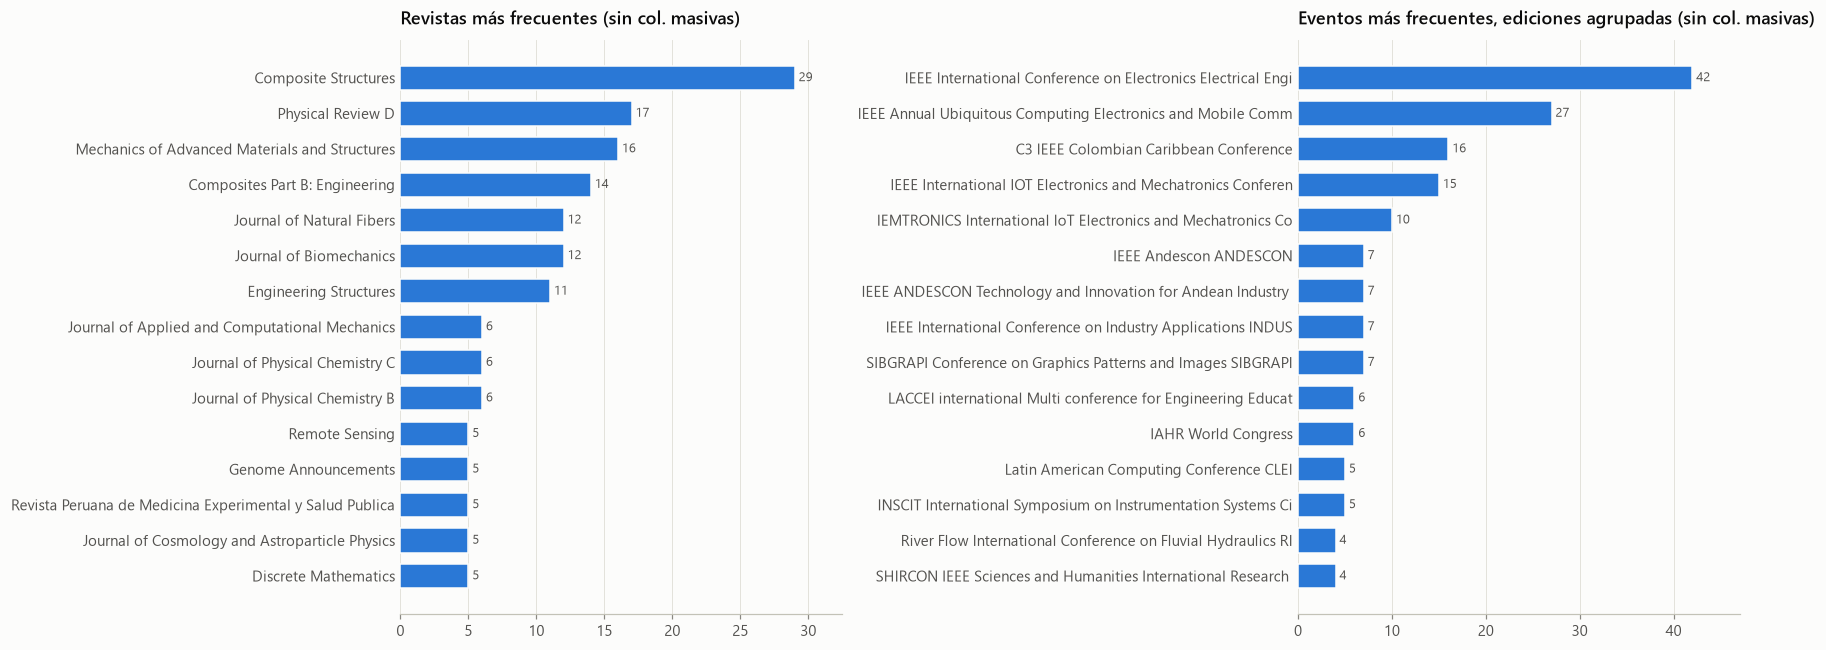

Revistas/eventos distintos (sin col. masivas): 791 para 1347 publicaciones

Revistas de las colaboraciones masivas:
venue
Journal of High Energy Physics                                                      326
Physical Review Letters                                                             275
Physical Review D - Particles, Fields, Gravitation and Cosmology                    210
Physical Review D                                                                    92
Physics Letters, Section B: Nuclear, Elementary Particle and High-Energy Physics     77


In [37]:
def serie_evento(s):
    """Nombre de la serie de un evento: sin años, ordinales ni 'Proceedings of (the)'."""
    s = re.sub(r"\b(19|20)\d{2}\b|\b\d+(st|nd|rd|th)\b|Proceedings( of)?( the)?|[-–:,]", " ", s)
    return re.sub(r"\s+", " ", s).strip()

v = pubs_u[~pubs_u.mega].dropna(subset=["venue"])
es_conf = v.tipo.str.contains("conferencia")
ev = v[es_conf].venue.map(serie_evento).to_frame("serie")
ev["clave"] = ev.serie.map(lambda s: " ".join(sorted(set(norm(s).split()))))   # independiente de orden/mayúsculas
etiqueta = ev.groupby("clave").serie.agg(lambda s: s.mode().iloc[0][:60])
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 6))
barh(ax1, v[v.tipo.str.startswith("Artículo") & ~es_conf].venue.str[:60].value_counts().head(15),
     title="Revistas más frecuentes (sin col. masivas)")
barh(ax2, ev.clave.value_counts().head(15).rename(etiqueta),
     title="Eventos más frecuentes, ediciones agrupadas (sin col. masivas)")
plt.tight_layout(); plt.show()
print("Revistas/eventos distintos (sin col. masivas):", v.venue.nunique(), "para", len(v), "publicaciones")
print("\nRevistas de las colaboraciones masivas:"); print(pubs_u[pubs_u.mega].venue.value_counts().head(5).to_string())

### 6.5 Idioma y vocabulario de los títulos

Idioma original según el detalle (sin col. masivas, %):
idioma_original
Inglés       96.9
Español       3.0
Portugués     0.1

Validación de la heurística por palabras vacías del título frente al idioma original:


idioma_original,Español,Inglés,Portugués,Sueco
heurística,,,,
en,0,2412,0,1
es,40,2,2,0
indeterminado,0,22,0,0


Acierto de la heurística: 98.9%


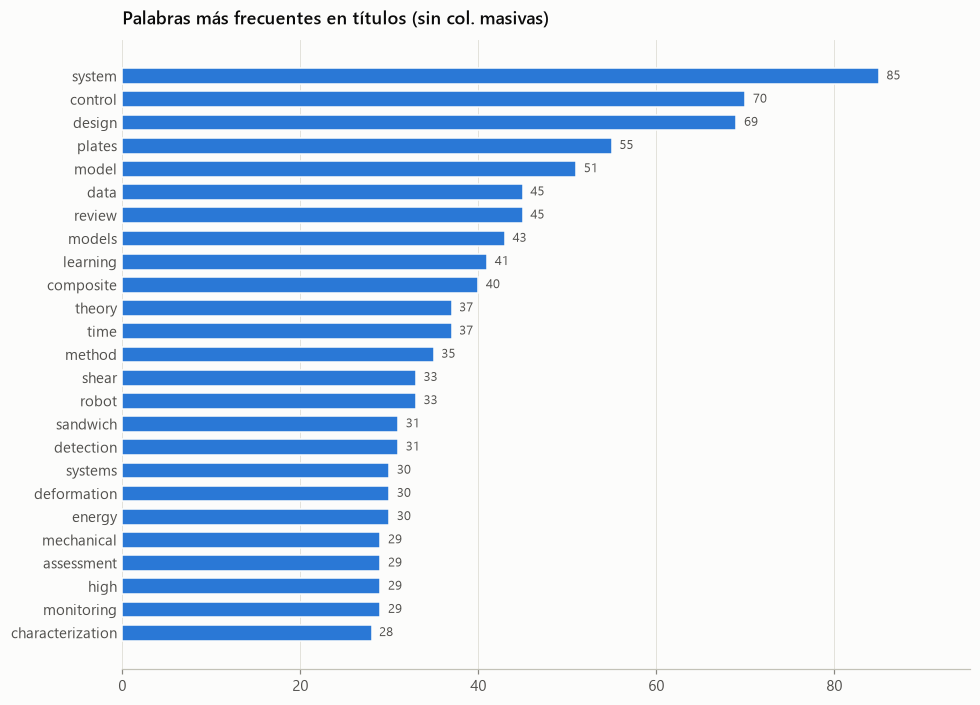

In [38]:
ES = set("de la el en los las del y para con por una un al sobre entre como su desde".split())
EN = set("the of and in for on with a an to from by using based at its into".split())
PT = set("do da dos das em para com uma um ao".split())

def idioma(t):
    w = re.findall(r"[a-záéíóúñãõç]+", t.lower())
    s = {"es": sum(x in ES for x in w), "en": sum(x in EN for x in w), "pt": sum(x in PT and x not in ES for x in w)}
    return max(s, key=s.get) if max(s.values()) > 0 else "indeterminado"

pubs_u["idioma"] = pubs_u.titulo.map(idioma)
nh = pubs_u[~pubs_u.mega]
print("Idioma original según el detalle (sin col. masivas, %):")
print((nh.idioma_original.value_counts(normalize=True) * 100).round(1).to_string())
print("\nValidación de la heurística por palabras vacías del título frente al idioma original:")
display(pd.crosstab(pubs_u.idioma.rename("heurística"), pubs_u.idioma_original))
acierto = pubs_u.idioma.map({"en": "Inglés", "es": "Español", "pt": "Portugués"}) == pubs_u.idioma_original
print(f"Acierto de la heurística: {acierto.mean():.1%}")

STOP = ES | EN | PT | set("study analysis case new evaluation peru peruvian lima effect effects through towards "
                          "under via vs approach use".split())
palabras = Counter(w for t in nh.titulo for w in re.findall(r"[a-záéíóúñ]{4,}", t.lower()) if w not in STOP)
fig, ax = plt.subplots(figsize=(9, 6.5))
barh(ax, pd.Series(dict(palabras.most_common(25))), title="Palabras más frecuentes en títulos (sin col. masivas)")
plt.tight_layout(); plt.show()

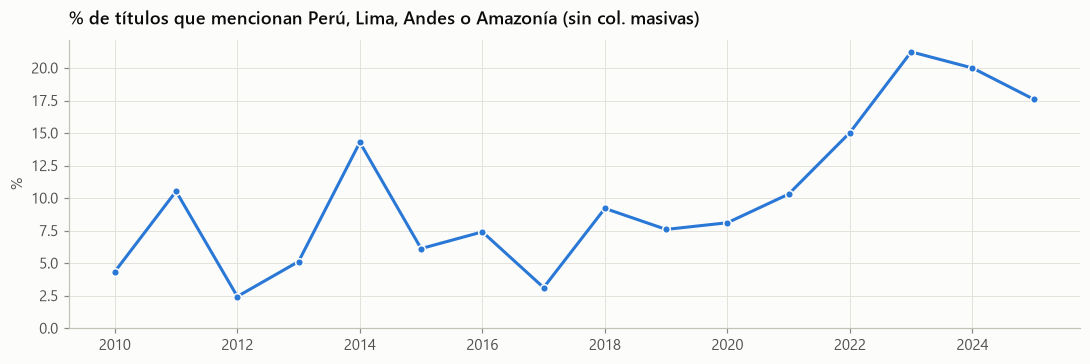

Global: 11.8%


In [39]:
# Menciones geográficas a Perú en títulos, por año
nh = nh.assign(peru=nh.titulo.str.contains(r"\bPer[uú]\b|\bPeruvian\b|\bLima\b|Andes|Andean|Amazon", case=False))
p = nh[nh.anio_num.between(2010, 2025)].groupby("anio_num").peru.mean() * 100
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.plot(p.index, p.values, color=BLUE, marker="o", ms=5, mec=SURFACE)
ax.set_title("% de títulos que mencionan Perú, Lima, Andes o Amazonía (sin col. masivas)"); ax.set_ylabel("%")
ax.set_ylim(bottom=0); plt.tight_layout(); plt.show()
print(f"Global: {nh.peru.mean():.1%}")

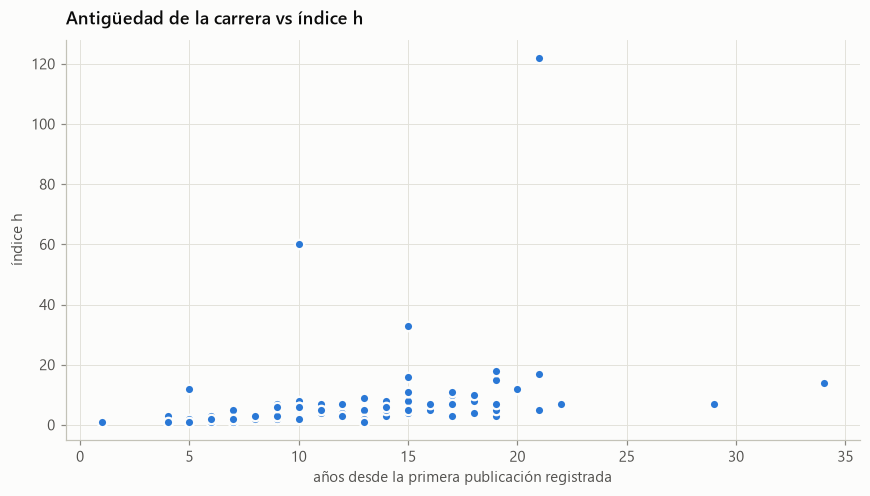

Spearman: 0.62


In [40]:
# Antigüedad de la carrera: año de la primera publicación registrada vs índice h
car = pubs.groupby("investigador").anio_num.agg(primer_anio="min", ultimo_anio="max")
perfiles = perfiles.drop(columns=["primer_anio", "ultimo_anio"], errors="ignore").merge(
    car, left_on="nombre", right_index=True, how="left")
perfiles["anios_carrera"] = HOY.year - perfiles.primer_anio

d = perfiles.dropna(subset=["anios_carrera", "indice_h"])
fig, ax = plt.subplots(figsize=(8, 4.6))
ax.scatter(d.anios_carrera, d.indice_h, s=38, color=BLUE, edgecolor=SURFACE, linewidth=1.5)
ax.set_xlabel("años desde la primera publicación registrada"); ax.set_ylabel("índice h")
ax.set_title("Antigüedad de la carrera vs índice h")
plt.tight_layout(); plt.show()
print("Spearman:", round(d.anios_carrera.corr(d.indice_h, method="spearman"), 3))

**Producción, equipos, revistas y temas**

- **Concentración alta**: Gini de 0,80 con todas las publicaciones y de 0,63 sin colaboraciones masivas. Incluso sin ellas, el 10 % más productivo firma el 43 % de las publicaciones y la mitad menos productiva solo el 8 %.
- **Los equipos son pequeños**: la mediana es de 4 autores (rango intercuartílico 3–5), estable desde 2017. Solo el 3,6 % tiene un único autor. La distribución es claramente **bimodal**: equipos normales de 1–10 autores frente a colaboraciones de ~600 (mediana 588, máximo 2011, *The Physics of the B Factories*). Son cifras con el conteo corregido de 3.3; la primera versión, basada en la referencia, duplicaba los autores ocultos y daba ~1000 para las colaboraciones.
- Hay **791 revistas y eventos distintos para 1347 publicaciones**, una dispersión muy alta. Destacan *Composite Structures* (29) y otras revistas de mecánica de materiales y estructuras. Entre los eventos dominan las conferencias IEEE regionales y latinoamericanas (INTERCON, UEMCON, C3, IEMTRONICS, ANDESCON, LACCEI): un perfil fuertemente ingenieril.
- El 96,9 % de las publicaciones está en inglés y el 3 % en español, según el campo `Idioma original` del detalle. La heurística por palabras del título acierta el 98,9 %; sus errores son casi todos títulos en inglés sin palabras vacías. Las palabras más frecuentes son *system*, *control*, *design*, *plates*, *model*, *data* y *learning*.
- **Investigación aplicada al contexto local en aumento**: el porcentaje de títulos que mencionan Perú, Lima, los Andes o la Amazonía pasa de < 10 % antes de 2020 a ~20 % en 2023–2024.
- Los años transcurridos desde la primera publicación correlacionan con el índice h (Spearman 0,62), como es esperable en métricas acumulativas.

## 7. Detalle de publicaciones

Análisis que solo son posibles con `utec_publicaciones_detalle/`: filiación institucional, posición de los autores UTEC, editoriales, conferencias, resúmenes y huella por publicación. Salvo que se indique, se excluyen las colaboraciones masivas.

### 7.1 Filiación UTEC: ¿qué parte de la producción se hizo en UTEC?

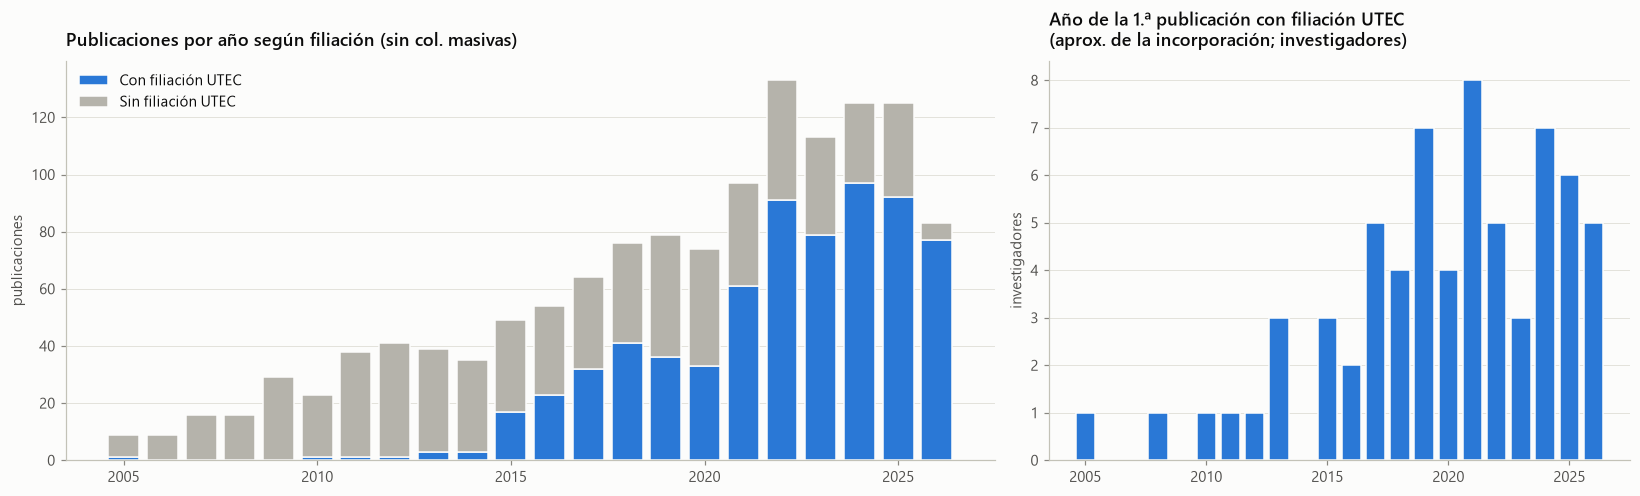

Con filiación UTEC: 34% de todas | 51% sin col. masivas | 13% de las col. masivas
% con filiación UTEC por año (sin col. masivas): {2015: 35, 2016: 43, 2017: 50, 2018: 54, 2019: 46, 2020: 45, 2021: 63, 2022: 68, 2023: 70, 2024: 78, 2025: 74, 2026: 93}
Investigadores con publicaciones pero ninguna con filiación UTEC: 13 de 80
Publicaciones con filiación UTEC anteriores a 2013 (UTEC inicia actividad académica después):
 anio_num                                                                 titulo                    investigadores
     2010 A methodology for supply chain design an application to auto-part indu              [José Ramos Saravia]
     2011              Dynamic motion capture and edition using a stack of tasks               [Oscar Ramos Ponce]
     2012 Erratum: Evidence for CP violation in time-integrated D0→h -h + decay  [Diego Alejandro Milanés Carreño]
     2009 Erratum: Exclusive initial-state-radiation production of the DD̄, D*D̄ [Diego Alejandro Milanés Carreño]
    

In [41]:
nm = pubs_u[~pubs_u.mega]
FIL = {True: "Con filiación UTEC", False: "Sin filiación UTEC"}
fa = (nm.groupby(["anio_num", "afiliacion_utec"]).size().unstack(fill_value=0)
      .rename(columns=FIL)[list(FIL.values())].loc[2005:2026])
pa = pubs[pubs.afiliacion_utec].groupby("investigador").anio_num.min()   # 1.ª publicación con filiación UTEC

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1.6, 1]})
bottom = np.zeros(len(fa))
for col, color in zip(fa.columns, [BLUE, OTHER]):
    ax1.bar(fa.index, fa[col], bottom=bottom, color=color, width=.8, edgecolor=SURFACE, linewidth=1, label=col)
    bottom += fa[col].values
ax1.set_title("Publicaciones por año según filiación (sin col. masivas)"); ax1.set_ylabel("publicaciones")
ax1.legend(loc="upper left"); ax1.grid(axis="x", visible=False)
c = pa.value_counts().sort_index()
ax2.bar(c.index, c.values, color=BLUE, width=.8, edgecolor=SURFACE)
ax2.set_title("Año de la 1.ª publicación con filiación UTEC\n(aprox. de la incorporación; investigadores)")
ax2.set_ylabel("investigadores"); ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

print(f"Con filiación UTEC: {pubs_u.afiliacion_utec.mean():.0%} de todas | {nm.afiliacion_utec.mean():.0%} sin col. masivas "
      f"| {pubs_u[pubs_u.mega].afiliacion_utec.mean():.0%} de las col. masivas")
print("% con filiación UTEC por año (sin col. masivas):",
      (fa.iloc[:, 0] / fa.sum(axis=1) * 100).loc[2015:2026].round(0).astype(int).to_dict())
con_pubs = perfiles.loc[perfiles.n_publicaciones > 0, "nombre"]
print(f"Investigadores con publicaciones pero ninguna con filiación UTEC: {(~con_pubs.isin(pa.index)).sum()} de {len(con_pubs)}")
print("Publicaciones con filiación UTEC anteriores a 2013 (UTEC inicia actividad académica después):")
print(pubs_u.loc[pubs_u.afiliacion_utec & (pubs_u.anio_num < 2013), ["anio_num", "titulo", "investigadores"]]
      .assign(titulo=lambda d: d.titulo.str[:70]).to_string(index=False))

perfiles["primer_anio_utec"] = perfiles.nombre.map(pa)
perfiles["pct_afiliacion_utec"] = perfiles.nombre.map(pubs.groupby("investigador").afiliacion_utec.mean())

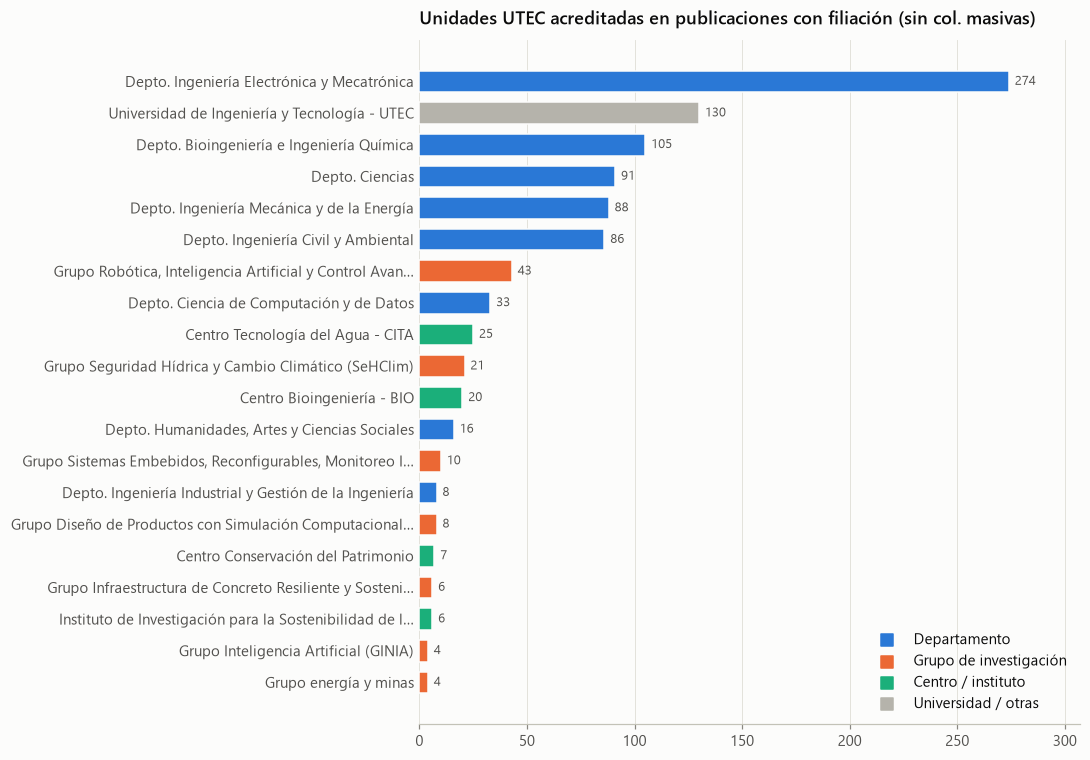

Unidades por publicación: {'mean': 1.44, '50%': 1.0, 'max': 4.0}
Publicaciones acreditadas solo a la universidad (sin depto., grupo ni centro): 1
Con algún departamento acreditado: 99% | de ellas, el departamento coincide con el del perfil: 100%


In [42]:
# Unidades UTEC a las que se acredita cada publicación con filiación
def tipo_org(o):
    return next((t for t in ("Departamento", "Grupo", "Centro", "Instituto") if o.lower().startswith(t.lower())), "Universidad / otras")
def abrev(o):
    o = re.sub(r"^Departamento de ", "Depto. ", o)
    o = re.sub(r"^Grupo de [Ii]nvestigación (en )?", "Grupo ", o)
    o = re.sub(r"^Centro de Investigación (en |y )?", "Centro ", o)
    return o if len(o) <= 55 else o[:54] + "…"

orgs = nm[nm.afiliacion_utec].assign(org=lambda d: d.organizaciones_utec.map(split_pipe)).explode("org")
oc = orgs.org.value_counts()
COL_ORG = {"Departamento": BLUE, "Grupo": ORANGE, "Centro": AQUA, "Instituto": AQUA, "Universidad / otras": OTHER}
top = oc.head(20)
fig, ax = plt.subplots(figsize=(10, 7))
barh(ax, top.rename(abrev), color=[COL_ORG[tipo_org(o)] for o in top.sort_values().index],
     title="Unidades UTEC acreditadas en publicaciones con filiación (sin col. masivas)")
for t, c in [("Departamento", BLUE), ("Grupo de investigación", ORANGE), ("Centro / instituto", AQUA), ("Universidad / otras", OTHER)]:
    ax.scatter([], [], s=60, color=c, marker="s", label=t)
ax.legend(loc="lower right")
plt.tight_layout(); plt.show()

print("Unidades por publicación:", orgs.groupby("url").size().describe()[["mean", "50%", "max"]].round(2).to_dict())
print("Publicaciones acreditadas solo a la universidad (sin depto., grupo ni centro):",
      nm[nm.afiliacion_utec].organizaciones_utec.eq("Universidad de Ingeniería y Tecnología - UTEC").sum())

# ¿El departamento acreditado coincide con el del perfil? (publicaciones con un solo investigador del dataset)
dep_de = perfiles.set_index("nombre").departamento
uno = nm[nm.afiliacion_utec & nm.n_investigadores_utec.eq(1)].copy()
uno["dep_perfil"] = uno.investigadores.str[0].map(dep_de)
uno = uno[uno.dep_perfil.ne("Sin departamento")]
uno["algun_depto"] = uno.organizaciones_utec.str.contains("Departamento de")
uno["coincide"] = [("Departamento de " + d) in o for d, o in zip(uno.dep_perfil, uno.organizaciones_utec)]
print(f"Con algún departamento acreditado: {uno.algun_depto.mean():.0%} | "
      f"de ellas, el departamento coincide con el del perfil: {uno[uno.algun_depto].coincide.mean():.0%}")

**Filiación UTEC**

- **Solo el 34 % de las publicaciones únicas tiene filiación UTEC**: el 51 % sin colaboraciones masivas y el 13 % de las masivas. El resto es producción anterior a la llegada a UTEC, o de colaboraciones externas.
- La parte con filiación UTEC **crece sin interrupción**: 35 % en 2015, ~50 % en 2017–2020, 63–70 % en 2021–2023 y 74–78 % en 2024–2025. 2026 va por el 93 %, aunque con el año incompleto. Casi todo el crecimiento posterior a 2020 es producción hecha en UTEC.
- El **año de la primera publicación con filiación UTEC** sirve para aproximar la incorporación de cada investigador. Las llegadas se reparten entre 2013 y 2026, con picos en 2019, 2021 y 2024. **13 de los 80 investigadores con publicaciones aún no tienen ninguna con filiación UTEC** (incorporaciones recientes).
- ⚠️ Hay 13 publicaciones con filiación UTEC anteriores a 2013, cuando UTEC aún no tenía actividad académica. Son fe de erratas de BaBar (asociadas a registros posteriores) y algunos registros mal etiquetados en Pure. Conviene tratarlas como externas.
- Las **unidades acreditadas** son casi siempre el departamento del autor: el 99 % de las publicaciones con un solo investigador del dataset acredita algún departamento, y en el 100 % de ellas coincide con el del perfil. Electrónica y Mecatrónica destaca (274). El grupo con más publicaciones es RIC (43), seguido del centro CITA (25). Computación aparece con pocas publicaciones (33) pese a ser el departamento más numeroso. Puede deberse a una plantilla más reciente o con menos publicaciones indexadas; con estos datos no se puede distinguir.

### 7.2 Posición de los autores UTEC en la lista de autores

Posición del (de algún) autor UTEC:
posicion
primer autor       457
último autor       421
intermedio         419
autor único         53
no identificado      1


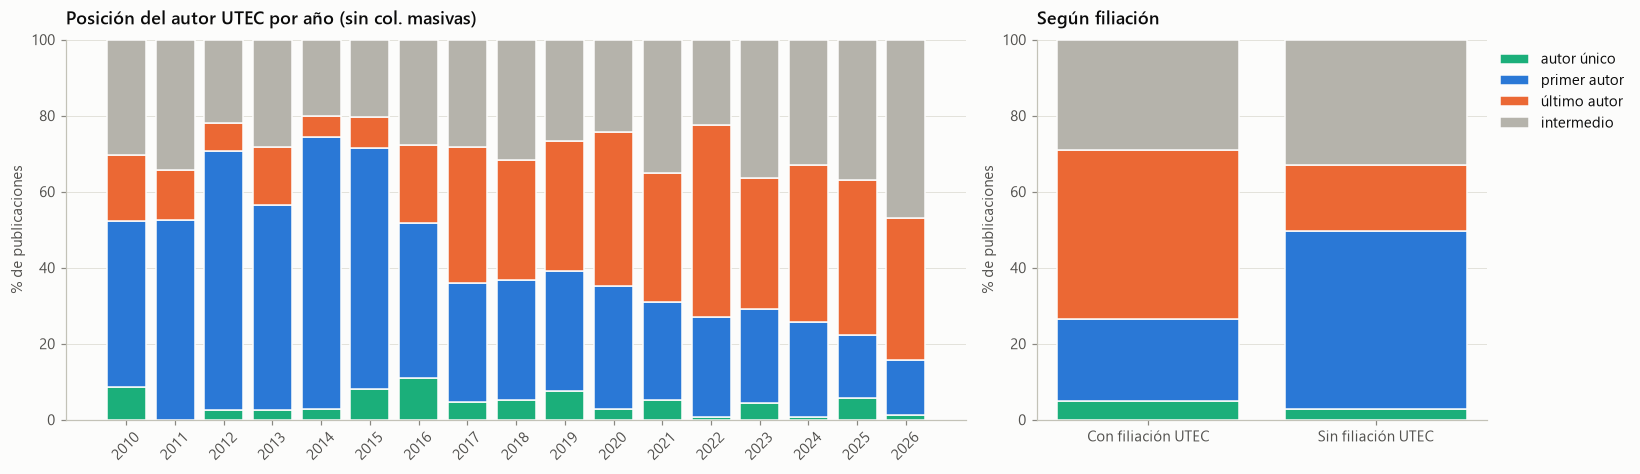

posicion,autor único,primer autor,último autor,intermedio
afiliacion_utec,,,,
Con filiación UTEC,5.0,22.0,44.0,29.0
Sin filiación UTEC,3.0,47.0,17.0,33.0


In [43]:
def posicion(r):
    toks = [t for t in r.autores.split(", ") if t]
    if len(toks) == 1: return "autor único"
    pos = [i for i, t in enumerate(toks) if any(nm_ in t for nm_ in r.autores_utec_nombres)]
    if not pos: return "no identificado"
    if 0 in pos: return "primer autor"
    if len(toks) - 1 in pos: return "último autor"
    return "intermedio"

nm = nm.assign(posicion=nm.apply(posicion, axis=1))
print("Posición del (de algún) autor UTEC:"); print(nm.posicion.value_counts().to_string())
ORD_POS = ["autor único", "primer autor", "último autor", "intermedio"]
COL_POS = [AQUA, BLUE, ORANGE, OTHER]
ps = nm[nm.posicion.isin(ORD_POS)]
py = pd.crosstab(ps.anio_num, ps.posicion, normalize="index").loc[2010:2026, ORD_POS] * 100
pf = pd.crosstab(ps.afiliacion_utec.map(FIL), ps.posicion, normalize="index")[ORD_POS] * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4.4), gridspec_kw={"width_ratios": [2, 1]})
for ax, t in [(ax1, py), (ax2, pf)]:
    bottom = np.zeros(len(t))
    for col, color in zip(ORD_POS, COL_POS):
        ax.bar(t.index.astype(str), t[col], bottom=bottom, color=color, width=.8, edgecolor=SURFACE, linewidth=1, label=col)
        bottom += t[col].values
    ax.set_ylim(0, 100); ax.set_ylabel("% de publicaciones"); ax.grid(axis="x", visible=False)
ax1.set_title("Posición del autor UTEC por año (sin col. masivas)"); ax1.tick_params(axis="x", rotation=45)
ax2.set_title("Según filiación"); ax2.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()
display(pf.round(0))

perfiles["pct_primer_o_ultimo"] = perfiles.nombre.map(
    ps.explode("investigadores").groupby("investigadores").posicion.apply(
        lambda s: s.isin(["autor único", "primer autor", "último autor"]).mean()))

**Posición en la lista de autores**

- Se identifica la posición del autor UTEC en el 99,9 % de las publicaciones. En conjunto, se reparte casi por igual entre primer autor (457), último autor (421) e intermedio (419); la autoría única es rara (53).
- **El cambio con la filiación es fuerte**. Sin filiación UTEC (antes de llegar), predominan los **primeros autores (47 %)**: es el perfil de doctorando o postdoc. Con filiación UTEC predominan los **últimos autores (44 %)**, la posición del investigador principal que dirige a estudiantes.
- La serie anual lo muestra: en 2011–2015 el primer autor supera el 50 %, y desde 2017 el último autor se mantiene en ~30–50 %. Es coherente con un cuerpo docente que empieza a formar sus propios grupos.
- `pct_primer_o_ultimo` se agrega a la tabla integrada como indicador de **liderazgo** por investigador.

### 7.3 Editoriales, revisión por pares e indexación

Prefijos DOI sin editorial asignada (top 8): {'10.3850': 7, '10.22055': 6, '10.1029': 5, '10.7712': 4, '10.4067': 3, '10.14569': 3, '10.1139': 3, '10.1108': 3}


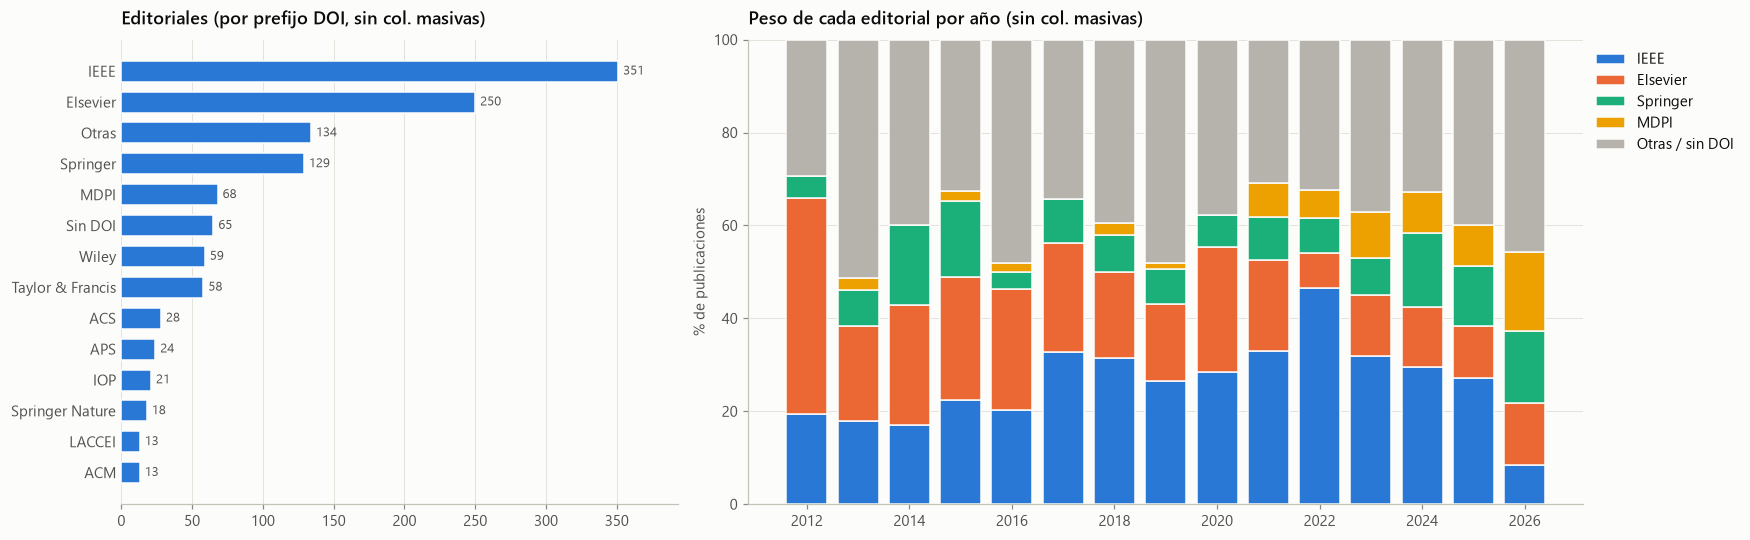

,% de publicaciones únicas
con DOI,97.0
con enlace a Scopus,99.8
revisión por pares exhaustiva,98.1
estado 'Publicada',99.9
con resumen,98.3
con huella,98.5


Tipos sin revisión por pares: {'Comentario/Debate': 42, 'Editorial': 6}
En prensa: [[2026, 'Impacts of storytelling on experiential service assessment'], [2026, 'Leveraging Smartwatch-Based Accelerometry to Assess Functional Capacity in Older Adults'], [2026, 'ManyWaves: A Visual Analytics Approach for Exploring Multivariate Spatiotemporal Data Based on the Graph Wavelet Transform']]


In [44]:
EDITORIAL = {"10.1109": "IEEE", "10.1016": "Elsevier", "10.1007": "Springer", "10.1140": "Springer",
             "10.1186": "Springer", "10.1038": "Springer Nature", "10.3390": "MDPI", "10.1103": "APS",
             "10.1088": "IOP", "10.1080": "Taylor & Francis", "10.1201": "Taylor & Francis", "10.1002": "Wiley",
             "10.1111": "Wiley", "10.1021": "ACS", "10.1117": "SPIE", "10.1145": "ACM", "10.1371": "PLOS",
             "10.1093": "Oxford UP", "10.1177": "SAGE", "10.3389": "Frontiers", "10.1063": "AIP", "10.1039": "RSC",
             "10.1136": "BMJ", "10.1155": "Hindawi", "10.1142": "World Scientific", "10.18687": "LACCEI",
             "10.5220": "SciTePress", "10.1051": "EDP Sciences", "10.1098": "Royal Society", "10.1017": "Cambridge UP",
             "10.1061": "ASCE", "10.1115": "ASME", "10.1590": "SciELO", "10.1128": "ASM", "10.1515": "De Gruyter",
             "10.17843": "Rev. Peru. Med. Exp. Salud Pública"}
pubs_u["editorial"] = np.where(pubs_u.doi_prefijo.isna(), "Sin DOI",
                               pubs_u.doi_prefijo.map(EDITORIAL).fillna("Otras"))
nm = nm.assign(editorial=nm.url.map(pubs_u.set_index("url").editorial))
print("Prefijos DOI sin editorial asignada (top 8):",
      nm.loc[nm.editorial.eq("Otras"), "doi_prefijo"].value_counts().head(8).to_dict())

TOP_ED = ["IEEE", "Elsevier", "Springer", "MDPI"]
ey = (nm.assign(ed=nm.editorial.where(nm.editorial.isin(TOP_ED), "Otras / sin DOI"))
      .pipe(lambda d: pd.crosstab(d.anio_num, d.ed, normalize="index")).loc[2012:2026, TOP_ED + ["Otras / sin DOI"]] * 100)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(16, 5), gridspec_kw={"width_ratios": [1, 1.5]})
barh(ax1, nm.editorial.value_counts().head(14), title="Editoriales (por prefijo DOI, sin col. masivas)")
bottom = np.zeros(len(ey))
for col, color in zip(ey.columns, SERIES[:4] + [OTHER]):
    ax2.bar(ey.index, ey[col], bottom=bottom, color=color, width=.8, edgecolor=SURFACE, linewidth=1, label=col)
    bottom += ey[col].values
ax2.set_ylim(0, 100); ax2.set_ylabel("% de publicaciones"); ax2.grid(axis="x", visible=False)
ax2.set_title("Peso de cada editorial por año (sin col. masivas)"); ax2.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.tight_layout(); plt.show()

ind = pd.Series({
    "con DOI": pubs_u.doi.ne("").mean(), "con enlace a Scopus": pubs_u.scopus.ne("").mean(),
    "revisión por pares exhaustiva": pubs_u.revisada_pares.mean(), "estado 'Publicada'": pubs_u.estado.eq("Publicada").mean(),
    "con resumen": pubs_u.len_resumen.gt(0).mean(), "con huella": pubs_u.n_conceptos_pub.gt(0).mean()})
display((ind * 100).round(1).rename("% de publicaciones únicas").to_frame())
print("Tipos sin revisión por pares:", pubs_u.loc[~pubs_u.revisada_pares, "tipo"].value_counts().to_dict())
print("En prensa:", pubs_u.loc[pubs_u.estado.ne("Publicada"), ["anio_num", "titulo"]].values.tolist())

**Editoriales e indexación**

- Según el prefijo DOI, **IEEE (351) y Elsevier (250)** son las editoriales principales, seguidas de Springer (129) y MDPI (68). IEEE sube del ~20 % en 2012–2016 a ~30 % desde 2017, con un pico del 47 % en 2022, de la mano de las conferencias.
- **MDPI crece**: casi ausente antes de 2016, ronda el 6–10 % en 2021–2025 y llega al 17 % en lo que va de 2026. Conviene vigilarlo en un análisis de calidad editorial.
- **Cobertura alta de identificadores**: 97 % con DOI y 99,8 % con enlace a Scopus. Esto permite cruzar con fuentes externas (citas por artículo en OpenAlex o Crossref, cuartiles de revista) en una etapa posterior.
- El 98 % tiene revisión por pares exhaustiva; las excepciones son comentarios y editoriales. Solo 3 publicaciones siguen "en prensa" (2026).

### 7.4 Conferencias: dónde y en qué modalidad

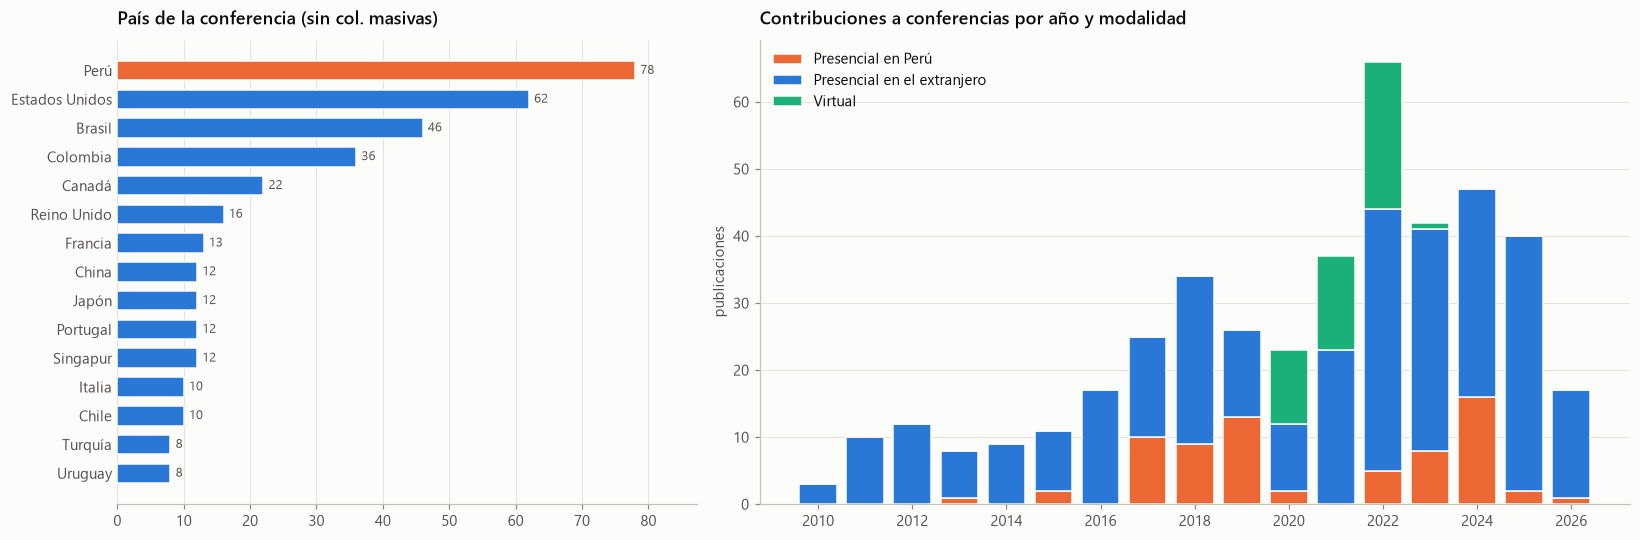

Publicaciones con datos de conferencia: 438 | países: 48 | Perú: 18% | virtuales: 11%
Ciudades en Perú: {'Lima': 46, 'Arequipa': 13, 'Virtual, Lima': 9, 'Cusco': 8, 'Hybrid, Cajamarca': 1, 'Piura': 1}
Mes de inicio de las conferencias: {1: 7, 2: 18, 3: 16, 4: 25, 5: 11, 6: 38, 7: 27, 8: 54, 9: 56, 10: 67, 11: 90, 12: 29}


In [45]:
cf = nm[nm.pais_conf.notna()].copy()
cf["modalidad"] = np.where(cf.virtual, "Virtual", np.where(cf.pais_conf.eq("Perú"), "Presencial en Perú",
                                                           "Presencial en el extranjero"))
MOD = ["Presencial en Perú", "Presencial en el extranjero", "Virtual"]
my = pd.crosstab(cf.anio_num, cf.modalidad).reindex(columns=MOD, fill_value=0).loc[2010:2026]
pc = cf.pais_conf.value_counts().head(15)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [1, 1.5]})
barh(ax1, pc, color=[ORANGE if p == "Perú" else BLUE for p in pc.sort_values().index],
     title="País de la conferencia (sin col. masivas)")
bottom = np.zeros(len(my))
for col, color in zip(MOD, [ORANGE, BLUE, AQUA]):
    ax2.bar(my.index, my[col], bottom=bottom, color=color, width=.8, edgecolor=SURFACE, linewidth=1, label=col)
    bottom += my[col].values
ax2.set_title("Contribuciones a conferencias por año y modalidad"); ax2.set_ylabel("publicaciones")
ax2.legend(loc="upper left"); ax2.grid(axis="x", visible=False)
ax2.xaxis.set_major_locator(mpl.ticker.MaxNLocator(integer=True))
plt.tight_layout(); plt.show()

print(f"Publicaciones con datos de conferencia: {len(cf)} | países: {cf.pais_conf.nunique()} | "
      f"Perú: {cf.pais_conf.eq('Perú').mean():.0%} | virtuales: {cf.virtual.mean():.0%}")
print("Ciudades en Perú:", cf.loc[cf.pais_conf.eq("Perú"), "ciudad_conf"].value_counts().to_dict())
print("Mes de inicio de las conferencias:", cf.conf_inicio.dt.month.value_counts().sort_index().to_dict())

**Conferencias**

- 438 contribuciones (sin colaboraciones masivas) tienen país, ciudad y fechas del evento, en **48 países**. **Perú es el primero (18 %)**: Lima, Arequipa y Cusco, sobre todo INTERCON. Le siguen EE. UU., Brasil y Colombia, este último por la IEEE Colombian Caribbean Conference en Barranquilla.
- Las conferencias en Perú son marginales hasta 2016 y alcanzan su máximo en 2024 (16).
- La **modalidad virtual** se concentra en 2020–2022, con un pico en 2022. ⚠️ Solo se detecta cuando el portal pone "Virtual" en la ciudad o el evento. Muchas conferencias de 2020–2021 figuran con su ciudad nominal, así que la cifra real de virtuales es mayor.
- Las conferencias se concentran en **agosto–noviembre** (noviembre es el mes pico), en línea con el calendario de INTERCON (agosto) y de otras conferencias IEEE regionales del segundo semestre.

### 7.5 Resúmenes: temas latentes

Se modelan temas con **NMF sobre TF-IDF** de los resúmenes en inglés (sin colaboraciones masivas, resúmenes de más de 100 caracteres). Cada publicación recibe una mezcla de temas, y cada tema se etiqueta con sus 3 términos más pesados.

In [46]:
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import NMF

docs = nm[nm.idioma_original.eq("Inglés") & nm.len_resumen.gt(100)].copy()
SW = list(ENGLISH_STOP_WORDS | set(
    "paper study results proposed used using based approach method methods data model models analysis present presents "
    "work research new also show shows use obtained different high order case however peru peruvian formula presented "
    "article".split()))
vec = TfidfVectorizer(stop_words=SW, max_df=0.4, min_df=5, ngram_range=(1, 2), max_features=6000,
                      token_pattern=r"(?u)\b[a-zA-Z][a-zA-Z-]{2,}\b")
Xt = vec.fit_transform(docs.resumen)
K = 12
nmf = NMF(n_components=K, random_state=0, init="nndsvda", max_iter=600)
W = nmf.fit_transform(Xt)
terms = np.array(vec.get_feature_names_out())
top_terms = [terms[c.argsort()[::-1][:10]] for c in nmf.components_]
ETQ_TEMA = [" · ".join(t[:3]) for t in top_terms]
docs["tema"] = W.argmax(axis=1)
Wn = pd.DataFrame(W / np.maximum(W.sum(axis=1, keepdims=True), 1e-12), index=docs.url, columns=ETQ_TEMA)

temas = pd.DataFrame({"tema": ETQ_TEMA, "publicaciones (tema principal)": docs.tema.value_counts().sort_index().values,
                      "términos": [", ".join(t) for t in top_terms]})
print(f"Documentos: {len(docs):,} | vocabulario: {len(terms):,}")
temas.sort_values("publicaciones (tema principal)", ascending=False)

Documentos: 1,292 | vocabulario: 4,396


,tema,publicaciones (tema principal),términos
3,classification · eeg · accuracy,179,"classification, eeg, accuracy, signals, learning, bci, subjects, brain, feat..."
2,control · robot · controller,158,"control, robot, controller, motion, robots, trajectory, design, position, mo..."
10,surface · species · reaction,151,"surface, species, reaction, leaching, samples, adsorption, chemical, films, ..."
6,water · river · precipitation,142,"water, river, precipitation, hydrological, soil, climate, events, regions, r..."
7,rehabilitation · exoskeletons · exoskeleton,124,"rehabilitation, exoskeletons, exoskeleton, design, development, device, knee..."
5,strength · fiber · fibers,116,"strength, fiber, fibers, concrete, properties, steel, composites, materials,..."
9,genetic · tuberculosis · populations,112,"genetic, tuberculosis, populations, patients, native, associated, variants, ..."
0,energy · power · solar,112,"energy, power, solar, systems, consumption, lora, production, network, desig..."
1,shear · theory · plates,109,"shear, theory, plates, equations, boundary, solution, boundary conditions, d..."
11,graph · graphs · set,35,"graph, graphs, set, minimum, connected, longest, conjecture, cardinality, ve..."


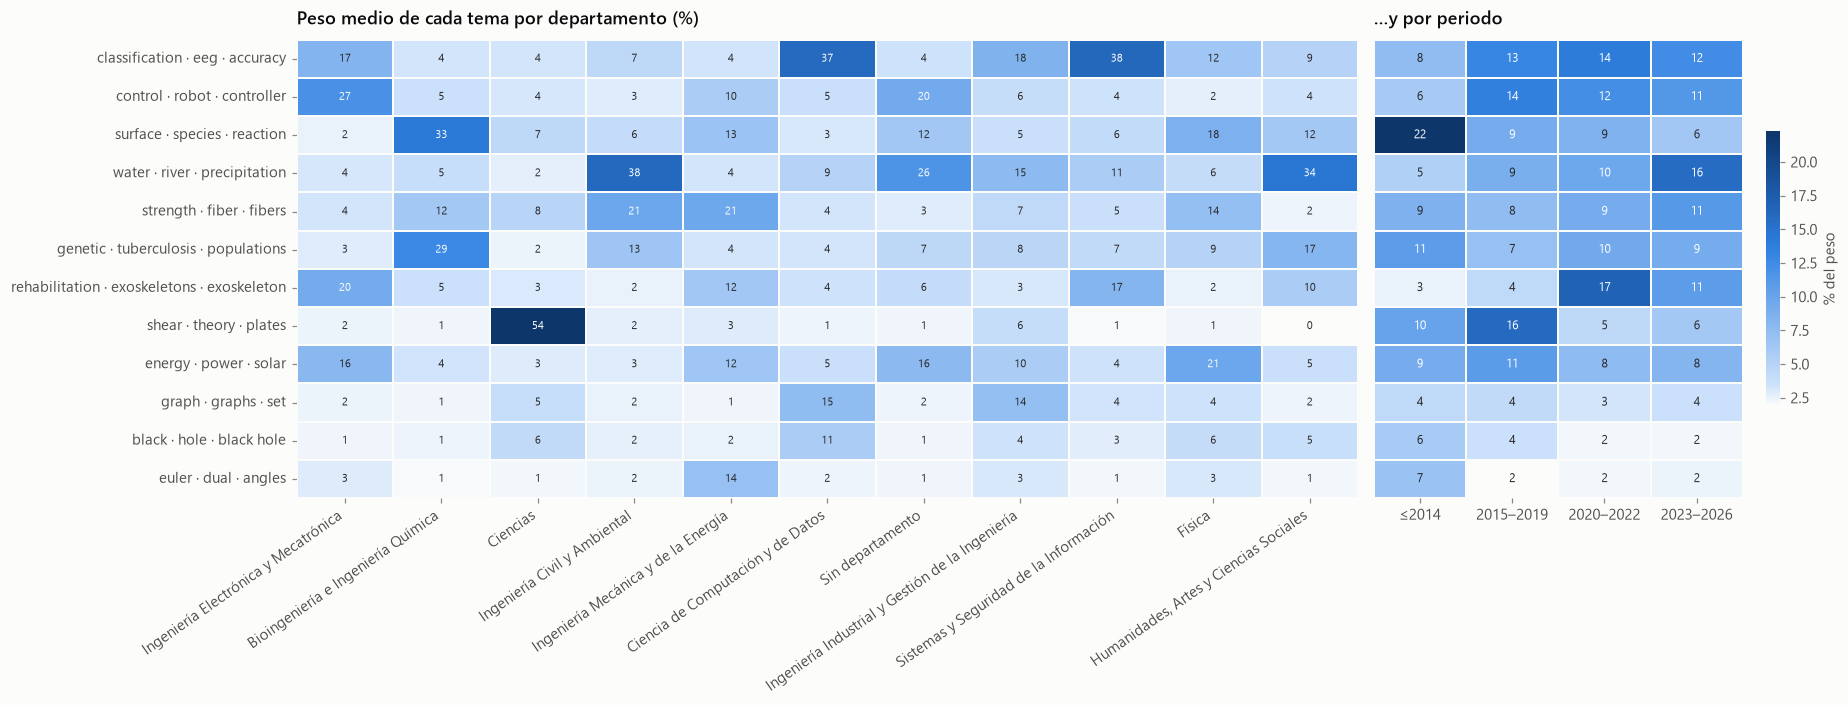

Publicaciones por periodo: {'≤2014': 260, '2015–2019': 306, '2020–2022': 295, '2023–2026': 431}


In [47]:
# Temas por departamento y por periodo (peso medio de cada tema; una publicación cuenta para cada investigador que la firma)
td = (docs[["url", "investigadores"]].explode("investigadores")
      .assign(departamento=lambda d: d.investigadores.map(dep_de)).join(Wn, on="url"))
TD = td.groupby("departamento")[ETQ_TEMA].mean() * 100
TD = TD.loc[td.departamento.value_counts().loc[lambda s: s >= 15].index]
orden_temas = Wn.sum().sort_values(ascending=False).index
PER = pd.cut(docs.anio_num, [0, 2014, 2019, 2022, 2030], labels=["≤2014", "2015–2019", "2020–2022", "2023–2026"])
TP = Wn.groupby(PER.values, observed=True).mean().T * 100

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(17, 6.5), gridspec_kw={"width_ratios": [2.3, 1]})
sns.heatmap(TD[orden_temas].T, cmap=CMAP_SEQ, annot=True, fmt=".0f", annot_kws={"fontsize": 7.5}, linewidths=1,
            linecolor=SURFACE, cbar=False, ax=ax1)
ax1.set_title("Peso medio de cada tema por departamento (%)"); ax1.set_xlabel(""); ax1.set_ylabel("")
plt.setp(ax1.get_xticklabels(), rotation=35, ha="right")
sns.heatmap(TP.loc[orden_temas], cmap=CMAP_SEQ, annot=True, fmt=".0f", annot_kws={"fontsize": 8}, linewidths=1,
            linecolor=SURFACE, cbar_kws={"shrink": .6, "label": "% del peso"}, ax=ax2, yticklabels=False)
ax2.set_title("…y por periodo"); ax2.set_xlabel("")
plt.tight_layout(); plt.show()
print("Publicaciones por periodo:", PER.value_counts().sort_index().to_dict())

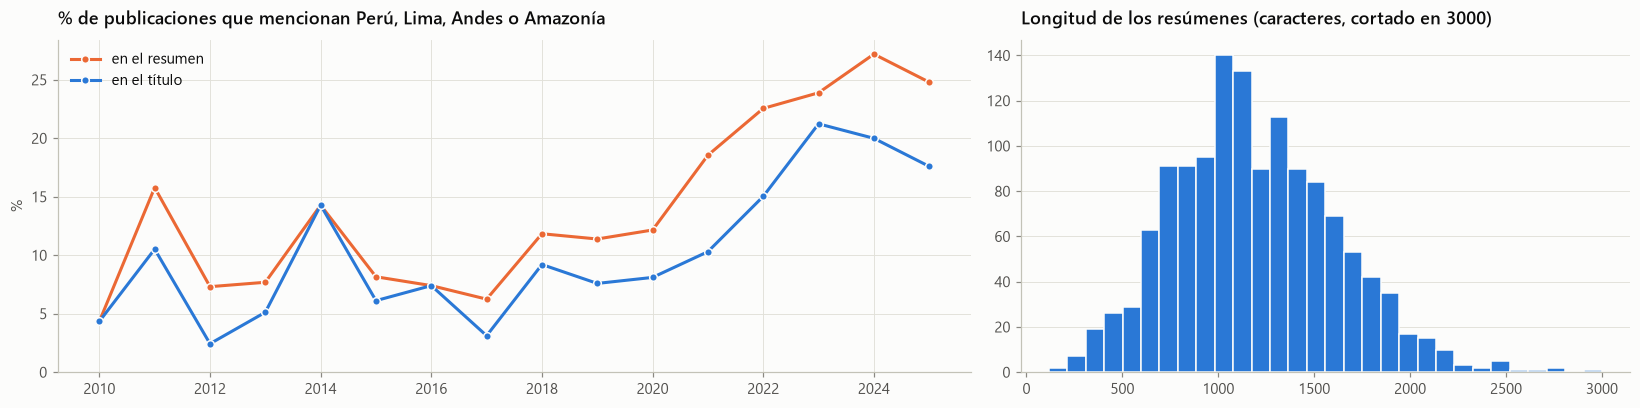

Menciones globales: título 12.2% | resumen 16.9%
Mediana de longitud del resumen por tipo: {'Artículo': 1258, 'Artículo de la conferencia': 1116, 'Artículo de revisión': 1183, 'Capítulo': 1029, 'Carta': 2091, 'Comentario/Debate': 421, 'Contribución a la conferencia': 1046, 'Libro': 695}


In [48]:
# Perú en resúmenes vs títulos
RE_PERU = r"\bPer[uú]\b|\bPeruvian\b|\bLima\b|Andes|Andean|Amazon"
pp = nm[nm.anio_num.between(2010, 2025)].assign(
    en_titulo=lambda d: d.titulo.str.contains(RE_PERU, case=False),
    en_resumen=lambda d: d.resumen.str.contains(RE_PERU, case=False))
g = pp.groupby("anio_num")[["en_titulo", "en_resumen"]].mean() * 100
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 3.8), gridspec_kw={"width_ratios": [1.5, 1]})
ax1.plot(g.index, g.en_resumen, color=ORANGE, marker="o", ms=5, mec=SURFACE, label="en el resumen")
ax1.plot(g.index, g.en_titulo, color=BLUE, marker="o", ms=5, mec=SURFACE, label="en el título")
ax1.set_title("% de publicaciones que mencionan Perú, Lima, Andes o Amazonía"); ax1.set_ylabel("%")
ax1.set_ylim(bottom=0); ax1.legend(loc="upper left")
r = nm[nm.len_resumen.gt(0)]
ax2.hist(r.len_resumen.clip(upper=3000), bins=30, color=BLUE, edgecolor=SURFACE)
ax2.set_title("Longitud de los resúmenes (caracteres, cortado en 3000)"); ax2.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(f"Menciones globales: título {pp.en_titulo.mean():.1%} | resumen {pp.en_resumen.mean():.1%}")
print("Mediana de longitud del resumen por tipo:", r.groupby("tipo").len_resumen.median().astype(int).to_dict())

**Temas en los resúmenes**

- NMF identifica **12 líneas de investigación nítidas**. Las principales son señales/EEG/BCI y clasificación, control y robótica, química de superficies y materiales, agua e hidrología, exoesqueletos y rehabilitación, fibras/concreto/compuestos, genética de poblaciones y tuberculosis, energía, y teoría de placas y láminas. Más pequeñas: teoría de grafos, ángulos de Euler duales en biomecánica y astrofísica (agujeros negros y cúmulos).
- **Cada departamento tiene una firma clara**:
  - Ciencias: 54 % placas y láminas, la línea de Mantari.
  - Civil y Ambiental: 38 % agua.
  - Bioingeniería: química de superficies (33 %) y genética (29 %).
  - Computación: 37 % clasificación y 15 % grafos.
  - Electrónica y Mecatrónica: control y robótica (27 %) y rehabilitación (20 %).
  - Humanidades: 34 % agua, por los estudios socioambientales.
- **Evolución**: la química de superficies pierde peso (22 % → 6 %), mientras que agua/hidrología (5 % → 16 %) y exoesqueletos/rehabilitación (3 % → 11–17 %) son las líneas que más crecen. La teoría de placas tuvo su auge en 2015–2019.
- **Contexto peruano**: los resúmenes mencionan Perú, Lima, los Andes o la Amazonía más que los títulos (16,9 % frente a 12,2 %), y la diferencia se amplía con el tiempo. **En 2024, uno de cada cuatro resúmenes** sitúa su trabajo en Perú.
- La mediana de los resúmenes va de ~1000 a ~1250 caracteres según el tipo (unas 150–200 palabras). Son suficientes para modelar temas o construir un buscador semántico.

### 7.6 Huella por publicación

Cada publicación trae hasta 8 conceptos de la huella de Elsevier, con área y peso. Esto permite ver la **evolución temática** año a año y comprobar de dónde sale la huella de cada investigador.

Conceptos por publicación: {0: 37, 1: 237, 2: 344, 3: 297, 4: 269, 5: 219, 6: 157, 7: 120, 8: 799}
(el máximo de 8 lo alcanza el 32% de las publicaciones: Pure muestra como mucho 8)


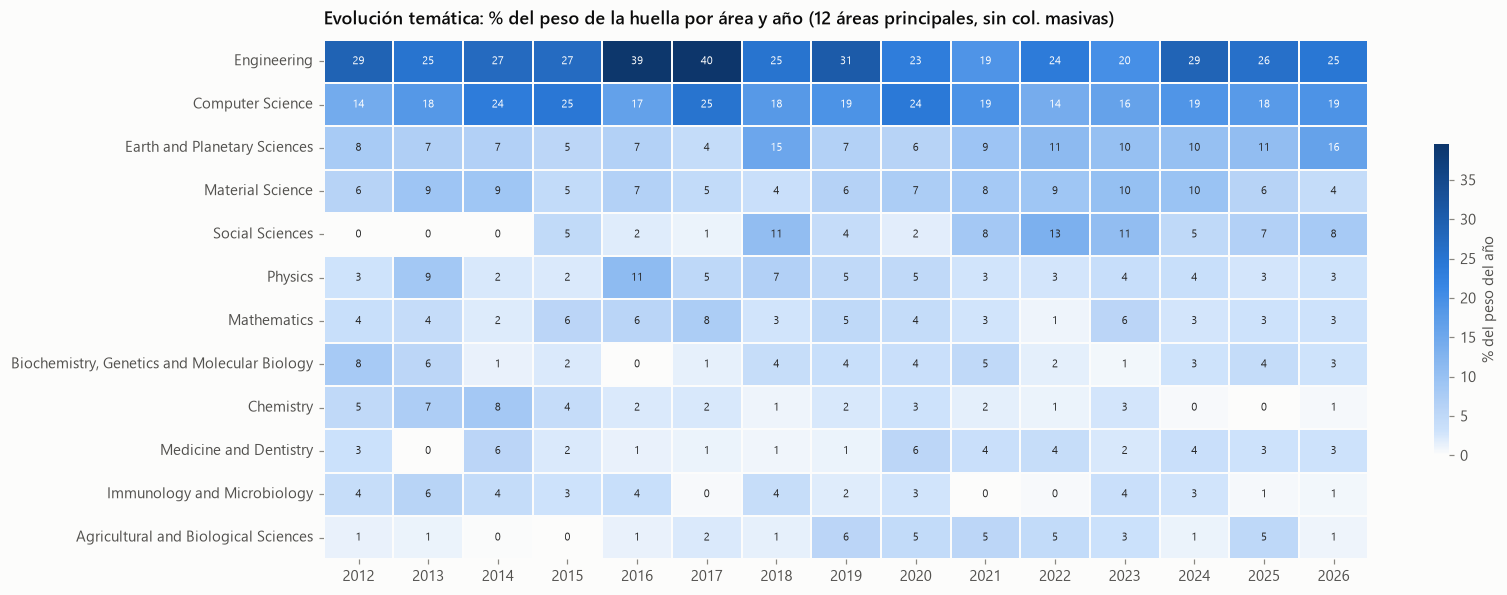

In [49]:
hpn = huella_pub[huella_pub.url.isin(nm.url)].merge(nm[["url", "anio_num"]], on="url")
print(f"Conceptos por publicación: {pubs_u.n_conceptos_pub.value_counts().sort_index().to_dict()}")
print("(el máximo de 8 lo alcanza el", f"{pubs_u.n_conceptos_pub.eq(8).mean():.0%} de las publicaciones: Pure muestra como mucho 8)")
AY = hpn[hpn.anio_num.between(2012, 2026)].pivot_table(index="area", columns="anio_num", values="peso", aggfunc="sum", fill_value=0)
AY = AY.div(AY.sum(), axis=1) * 100
AY = AY.loc[AY.mean(axis=1).sort_values(ascending=False).index[:12]]
fig, ax = plt.subplots(figsize=(15, 5.5))
sns.heatmap(AY, cmap=CMAP_SEQ, annot=True, fmt=".0f", annot_kws={"fontsize": 7.5}, linewidths=1, linecolor=SURFACE,
            cbar_kws={"shrink": .6, "label": "% del peso del año"}, ax=ax)
ax.set_title("Evolución temática: % del peso de la huella por área y año (12 áreas principales, sin col. masivas)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

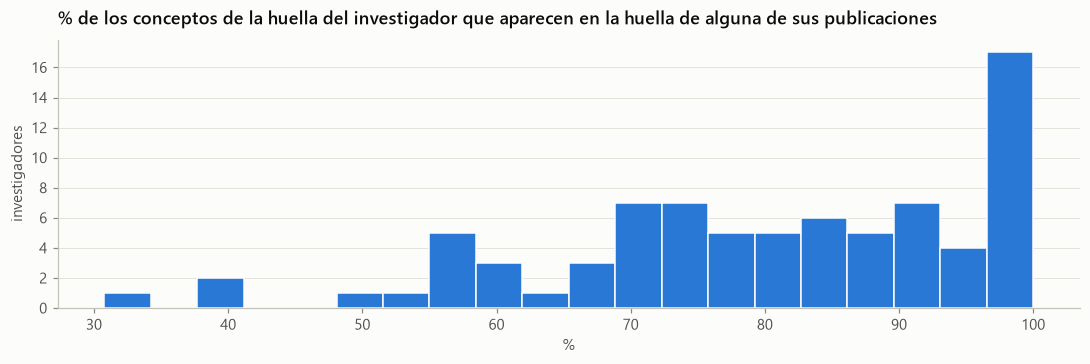

                                                       count   mean    std    min    25%    50%    75%    max
coseno                                                  80.0   0.89   0.09   0.56   0.85   0.90   0.96    1.0
% conceptos del perfil presentes en sus publicaciones   80.0  80.01  16.45  30.77  71.22  82.38  93.39  100.0

Relación con el nº de publicaciones (Spearman): 0.36


,investigador,coseno,% conceptos del perfil presentes en sus publicaciones,conceptos perfil,publicaciones
54,Lucia Rivera Charún,0.61,30.77,26,2
79,Yamilet Rosario Serrano Llerena,0.89,40.00,25,3
44,José Andrés De Leo Martínez,0.56,40.54,37,3
2,Alberto Donayre Torres,0.73,48.86,88,10
20,Elmer Ramirez Quiroz,0.80,54.84,62,6


In [50]:
# ¿La huella del investigador es la suma de las huellas de sus publicaciones?
hpi = (huella_pub.merge(pub_inv[["investigador", "url"]], on="url")
       .groupby(["investigador", "url", "concepto"]).peso.max().groupby(["investigador", "concepto"]).sum())
hri = huella.groupby(["investigador", "concepto"]).peso.max()
filas = []
for inv in hri.index.get_level_values(0).unique():
    a, b = hri.loc[inv], hpi.loc[inv] if inv in hpi.index.get_level_values(0) else pd.Series(dtype=float)
    idx = a.index.union(b.index)
    va, vb = a.reindex(idx, fill_value=0).values, b.reindex(idx, fill_value=0).values
    filas.append({"investigador": inv, "coseno": va @ vb / (np.linalg.norm(va) * np.linalg.norm(vb) or 1),
                  "% conceptos del perfil presentes en sus publicaciones": a.index.isin(b.index).mean() * 100,
                  "conceptos perfil": len(a), "publicaciones": (pub_inv.investigador == inv).sum()})
coh = pd.DataFrame(filas)
fig, ax = plt.subplots(figsize=(10, 3.4))
ax.hist(coh["% conceptos del perfil presentes en sus publicaciones"], bins=20, color=BLUE, edgecolor=SURFACE)
ax.set_title("% de los conceptos de la huella del investigador que aparecen en la huella de alguna de sus publicaciones")
ax.set_xlabel("%"); ax.set_ylabel("investigadores"); ax.grid(axis="x", visible=False)
plt.tight_layout(); plt.show()
print(coh[["coseno", "% conceptos del perfil presentes en sus publicaciones"]].describe().round(2).T.to_string())
print("\nRelación con el nº de publicaciones (Spearman):",
      round(coh.publicaciones.corr(coh["% conceptos del perfil presentes en sus publicaciones"], method="spearman"), 2))
coh.nsmallest(5, "% conceptos del perfil presentes en sus publicaciones").round(2)

**Huella por publicación**

- El 32 % de las publicaciones alcanza el máximo de 8 conceptos: **la huella por publicación está truncada**. Los pesos absolutos no deben compararse entre publicaciones con muchos y pocos conceptos.
- **Evolución por área**: Engineering y Computer Science dominan todos los años. Earth and Planetary Sciences gana peso (5–8 % → 10–16 % desde 2022) y Social Sciences aparece con fuerza desde 2018. Las dos tendencias coinciden con la línea de agua y clima de los resúmenes. Chemistry y Biochemistry pierden peso.
- **La huella del investigador se construye con las de sus publicaciones**: en mediana, el 82 % de los conceptos del perfil aparece en alguna de sus publicaciones, y el coseno entre ambos vectores es de 0,90. La coincidencia es menor en quienes tienen pocas publicaciones (Spearman 0,36 con el nº de publicaciones). Probablemente Elsevier calcula la huella del perfil con el texto completo de todas sus publicaciones y no solo con los 8 conceptos visibles por publicación.
- Esto valida usar la huella por publicación para análisis temáticos **por año, departamento o grupo**, algo que la huella agregada por investigador no permite.

## 8. Red de coautoría interna

Dos investigadores están conectados si firman juntos al menos una publicación del dataset. El peso de la arista es el nº de publicaciones compartidas.

In [51]:
G = nx.Graph()
G.add_nodes_from(perfiles.loc[perfiles.n_publicaciones > 0, "nombre"])
for xs in pubs_u.loc[pubs_u.n_investigadores_utec > 1, "investigadores"]:
    for a, b in combinations(xs, 2):
        w = G.get_edge_data(a, b, {"weight": 0})["weight"]
        G.add_edge(a, b, weight=w + 1)

dep_map = perfiles.set_index("nombre").departamento
comp = sorted(nx.connected_components(G), key=len, reverse=True)
print(f"Nodos (con ≥1 publicación): {G.number_of_nodes()} | aristas: {G.number_of_edges()} | "
      f"densidad: {nx.density(G):.3f}")
print(f"Componentes: {len(comp)} | mayor componente: {len(comp[0])} nodos | aislados: {nx.number_of_isolates(G)}")

intra = sum(dep_map[a] == dep_map[b] for a, b in G.edges())
print(f"Aristas dentro del mismo departamento: {intra}/{G.number_of_edges()} ({intra / G.number_of_edges():.0%})")

cent = pd.DataFrame({"grado": dict(G.degree()), "grado_ponderado": dict(G.degree(weight="weight")),
                     "intermediación": nx.betweenness_centrality(G)}).round(3)
cent["departamento"] = dep_map
cent.sort_values("grado", ascending=False).head(10)

Nodos (con ≥1 publicación): 80 | aristas: 36 | densidad: 0.011
Componentes: 50 | mayor componente: 23 nodos | aislados: 43
Aristas dentro del mismo departamento: 19/36 (53%)


,grado,grado_ponderado,intermediación,departamento
Ruth Canahuire Cabello,5,9,0.016,Sin departamento
José Luis Mantari Laureano,5,9,0.039,Ciencias
Carmen Elena Flores Barreda,4,10,0.030,Bioingeniería e Ingeniería Química
Helard Alvarez Sanchez,3,4,0.026,Ingeniería Mecánica y de la Energía
Christian Flores Vega,3,3,0.029,Ingeniería Electrónica y Mecatrónica
Wangdo Kim,3,7,0.034,Ingeniería Mecánica y de la Energía
Monica C. Santa-Maria,3,3,0.001,Ingeniería Civil y Ambiental
Moises Nuñez Ochoa,3,8,0.013,Ingeniería Electrónica y Mecatrónica
Julio Ernesto Valdivia Silva,3,7,0.007,Bioingeniería e Ingeniería Química
Emir Augusto Vela Saavedra,3,8,0.008,Ingeniería Mecánica y de la Energía


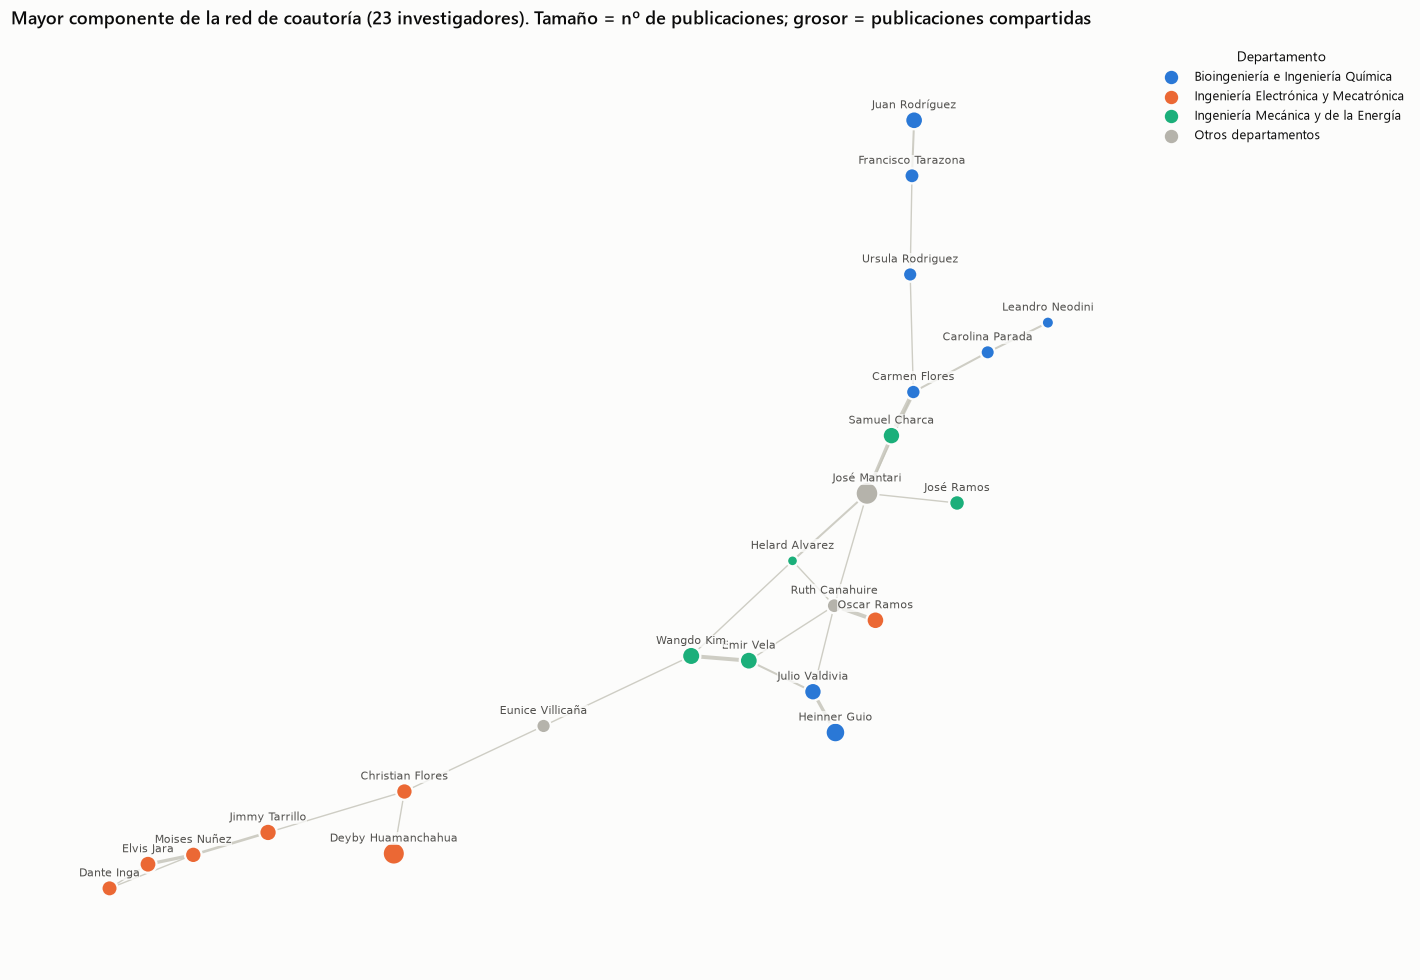

In [52]:
H = G.subgraph(comp[0]).copy()
pos = nx.spring_layout(H, weight="weight", k=0.6, seed=7, iterations=300)
top_dep = pd.Series([dep_map[n] for n in H]).value_counts().index[:3]
col = {d: c for d, c in zip(top_dep, SERIES[:3])}
npub = perfiles.set_index("nombre").n_publicaciones

fig, ax = plt.subplots(figsize=(13, 9))
w = np.array([H[a][b]["weight"] for a, b in H.edges()])
nx.draw_networkx_edges(H, pos, width=0.5 + 2.5 * w / w.max(), edge_color=AXIS, alpha=.8, ax=ax)
nx.draw_networkx_nodes(H, pos, node_size=[20 + 18 * np.sqrt(npub[n]) for n in H],
                       node_color=[col.get(dep_map[n], OTHER) for n in H], edgecolors=SURFACE, linewidths=1.5, ax=ax)
etq = {n: corto(n) for n in H}
dy = 0.012 * (max(y for _, y in pos.values()) - min(y for _, y in pos.values()))
nx.draw_networkx_labels(H, {n: (x, y + dy) for n, (x, y) in pos.items()}, etq, font_size=7.5, font_color=INK2,
                        ax=ax, verticalalignment="bottom", bbox=dict(fc=SURFACE, ec="none", alpha=.75, pad=0.3))
for d, c in list(col.items()) + [("Otros departamentos", OTHER)]:
    ax.scatter([], [], s=60, color=c, label=d)
ax.legend(loc="upper left", bbox_to_anchor=(1.0, 1.0), fontsize=8.5, title="Departamento", title_fontsize=9)
ax.set_title(f"Mayor componente de la red de coautoría ({H.number_of_nodes()} investigadores). "
             "Tamaño = nº de publicaciones; grosor = publicaciones compartidas")
ax.axis("off"); plt.tight_layout(); plt.show()

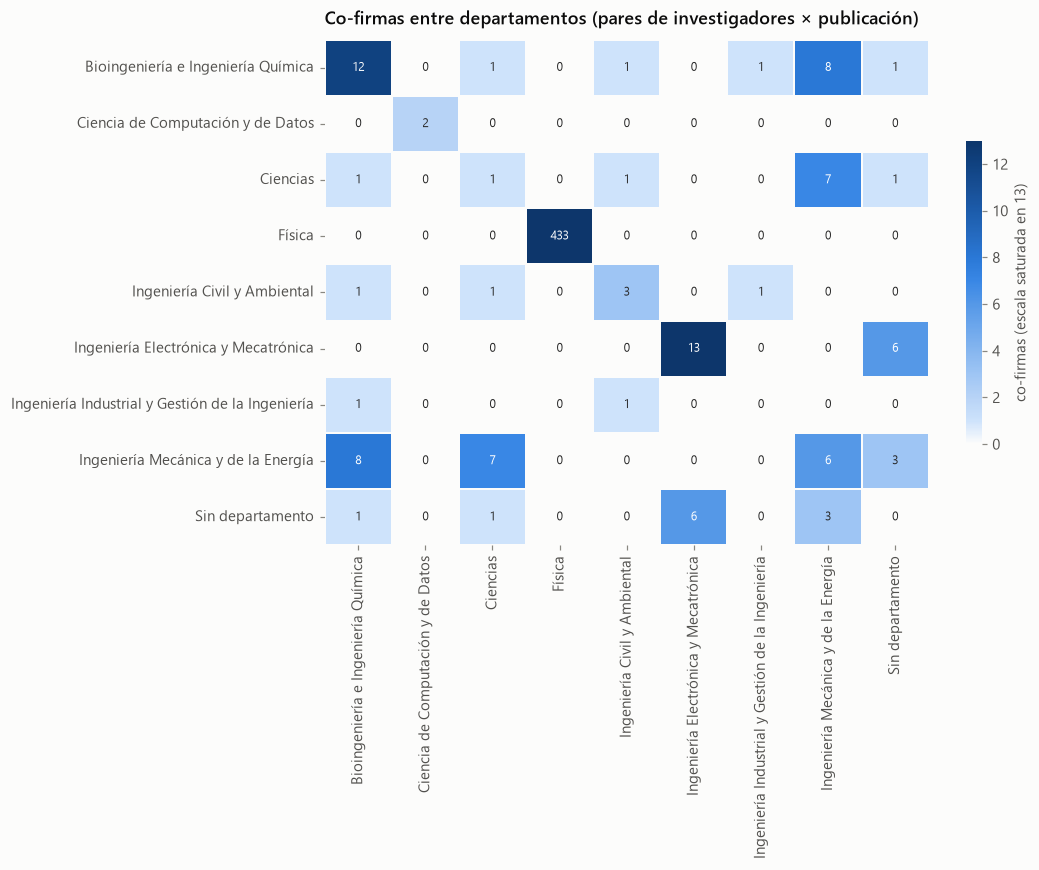

In [53]:
# Matriz departamento × departamento de publicaciones compartidas
deps = sorted(perfiles.departamento.unique())
M = pd.DataFrame(0, index=deps, columns=deps)
for a, b, d in G.edges(data=True):
    da, db = dep_map[a], dep_map[b]
    M.loc[da, db] += d["weight"]
    if da != db: M.loc[db, da] += d["weight"]
M = M.loc[M.sum(axis=1) > 0, M.sum(axis=0) > 0]
vmax = np.sort(M.values.ravel())[-2]   # la celda Física–Física (colaboraciones masivas) satura la escala
fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(M, cmap=CMAP_SEQ, vmax=vmax, annot=True, fmt="d", annot_kws={"fontsize": 8}, linewidths=1,
            linecolor=SURFACE, cbar_kws={"shrink": .6, "label": f"co-firmas (escala saturada en {vmax})"}, ax=ax)
ax.set_title("Co-firmas entre departamentos (pares de investigadores × publicación)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); plt.show()

**Red de coautoría interna**

- La red es **muy dispersa**: 80 investigadores con publicaciones, apenas 36 aristas (densidad 0,011) y **43 aislados**. Más de la mitad no comparte ninguna publicación con otro de los 104 perfiles.
- La mayor componente reúne a 23 investigadores y conecta dos núcleos: uno de **Electrónica y Mecatrónica** (Tarrillo, Núñez, Jara, Inga, Flores) y otro **Mecánica–Bioingeniería–Ciencias**. Hacen de puente José Mantari, Ruth Canahuire, Wangdo Kim y Eunice Villicaña.
- El 53 % de las aristas son dentro del mismo departamento. Las colaboraciones entre departamentos más frecuentes son Bioingeniería–Mecánica y Ciencias–Mecánica.
- La celda Física–Física (433 co-firmas) es en realidad un solo par, Milanés–Shmanin, inflado por las colaboraciones LHCb.
- ⚠️ La red solo mide co-firmas **entre los 104 perfiles del dataset**, no con el resto de UTEC ni con coautores externos.

## 9. Huella digital (temas de investigación)

La huella digital (*fingerprint*) de Elsevier extrae conceptos de los resúmenes de las publicaciones indexadas. Cada concepto tiene un área (Scopus ASJC) y un peso relativo (100% = el concepto más fuerte del investigador).

Investigadores con publicaciones pero sin huella: []
Investigadores con huella pero sin publicaciones: []


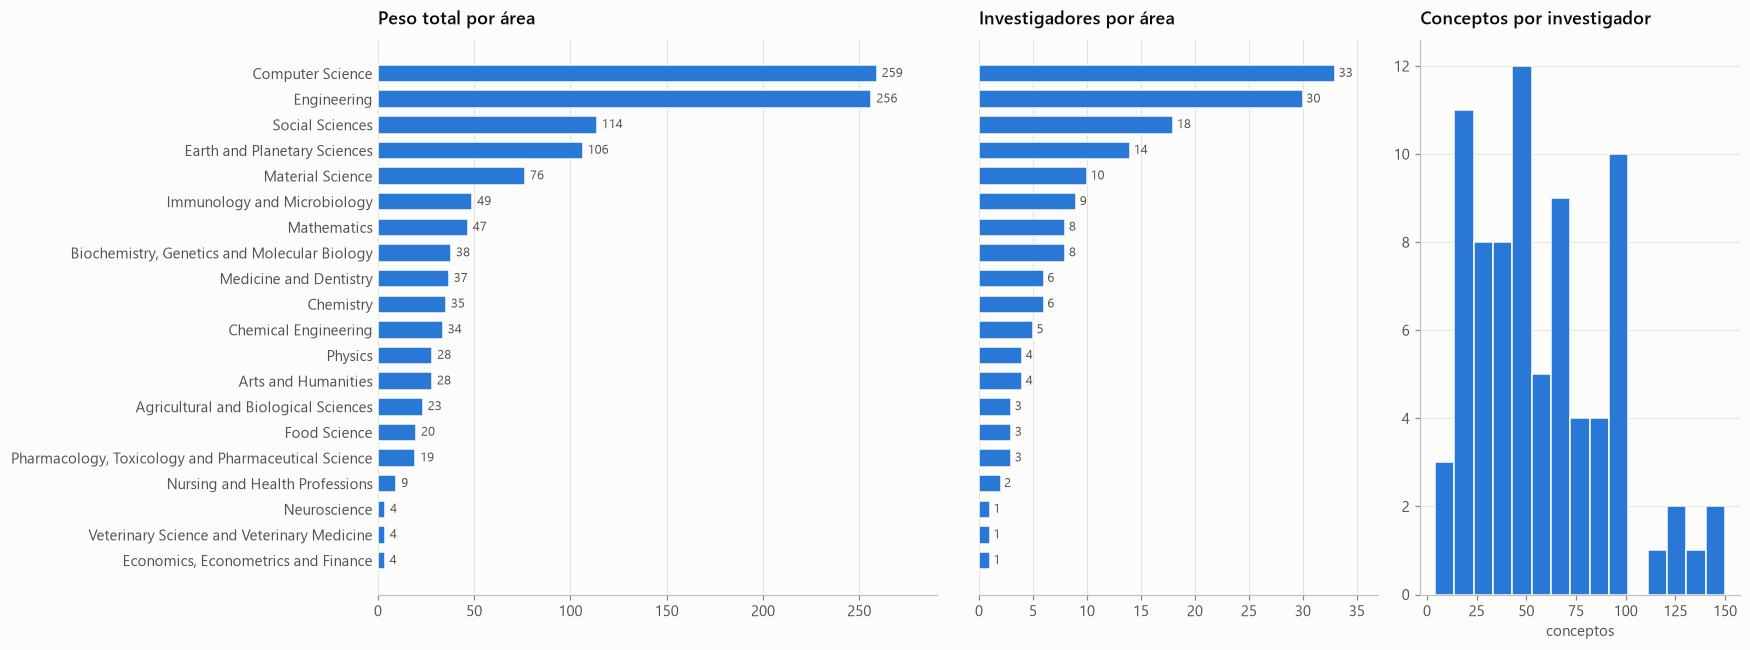

In [54]:
print("Investigadores con publicaciones pero sin huella:",
      sorted(set(perfiles.loc[perfiles.n_publicaciones > 0, "nombre"]) - set(huella.investigador)))
print("Investigadores con huella pero sin publicaciones:",
      sorted(set(huella.investigador) - set(perfiles.loc[perfiles.n_publicaciones > 0, "nombre"])))

fig, axes = plt.subplots(1, 3, figsize=(16, 6), gridspec_kw={"width_ratios": [1.4, 1, 0.8]})
barh(axes[0], huella.groupby("area").peso.sum(), title="Peso total por área", fmt="{:,.0f}")
barh(axes[1], huella.groupby("area").investigador.nunique(), title="Investigadores por área")
axes[1].set_yticks([])
axes[2].hist(huella.groupby("investigador").size(), bins=15, color=BLUE, edgecolor=SURFACE)
axes[2].set_title("Conceptos por investigador"); axes[2].set_xlabel("conceptos"); axes[2].grid(axis="x", visible=False)
plt.tight_layout(); plt.show()

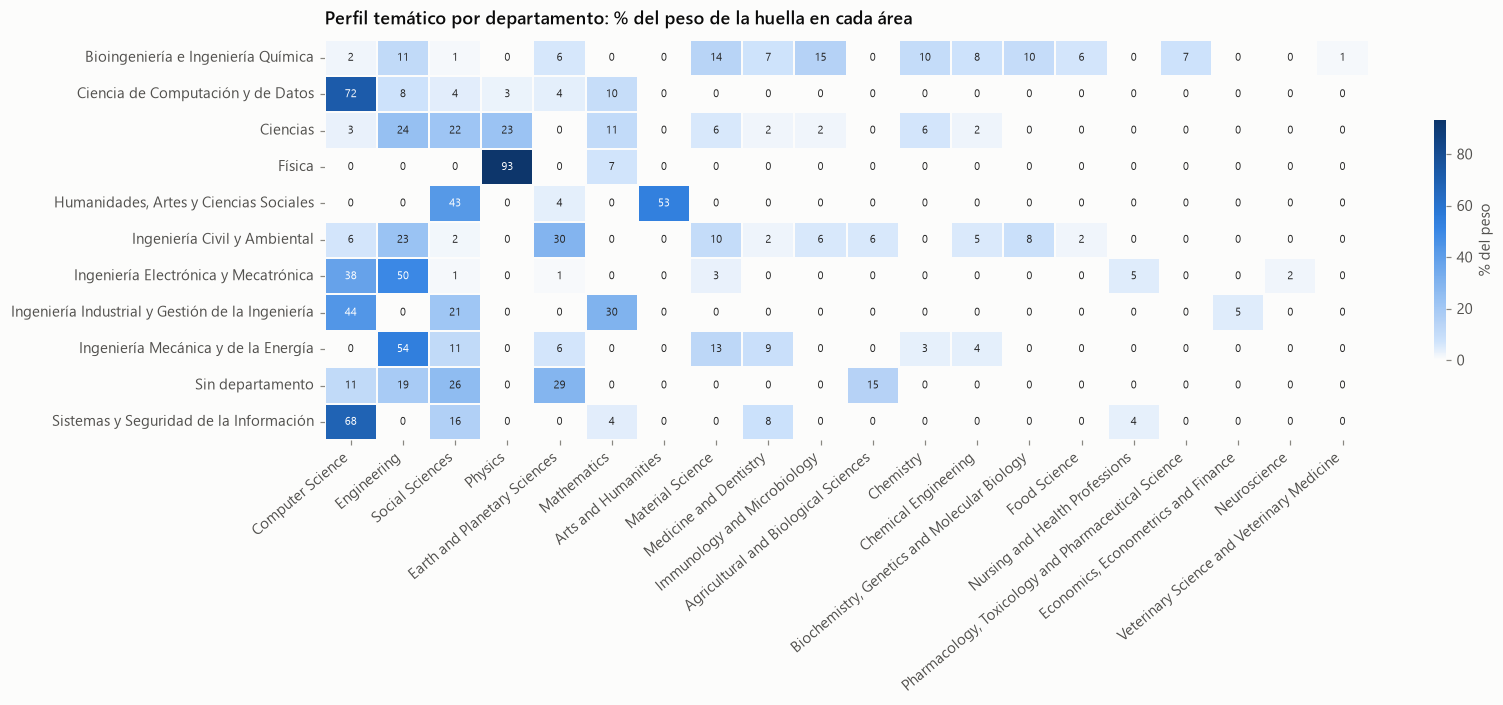

In [55]:
# Perfil temático de cada departamento: % del peso de la huella por área
hd = huella.assign(departamento=huella.investigador.map(dep_map))
P = hd.pivot_table(index="departamento", columns="area", values="peso", aggfunc="sum", fill_value=0)
P = P.div(P.sum(axis=1), axis=0) * 100
P = P[P.sum().sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(15, 6.5))
sns.heatmap(P, cmap=CMAP_SEQ, annot=True, fmt=".0f", annot_kws={"fontsize": 7.5}, linewidths=1,
            linecolor=SURFACE, cbar_kws={"shrink": .6, "label": "% del peso"}, ax=ax)
ax.set_title("Perfil temático por departamento: % del peso de la huella en cada área")
ax.set_xlabel(""); ax.set_ylabel(""); plt.setp(ax.get_xticklabels(), rotation=40, ha="right")
plt.tight_layout(); plt.show()

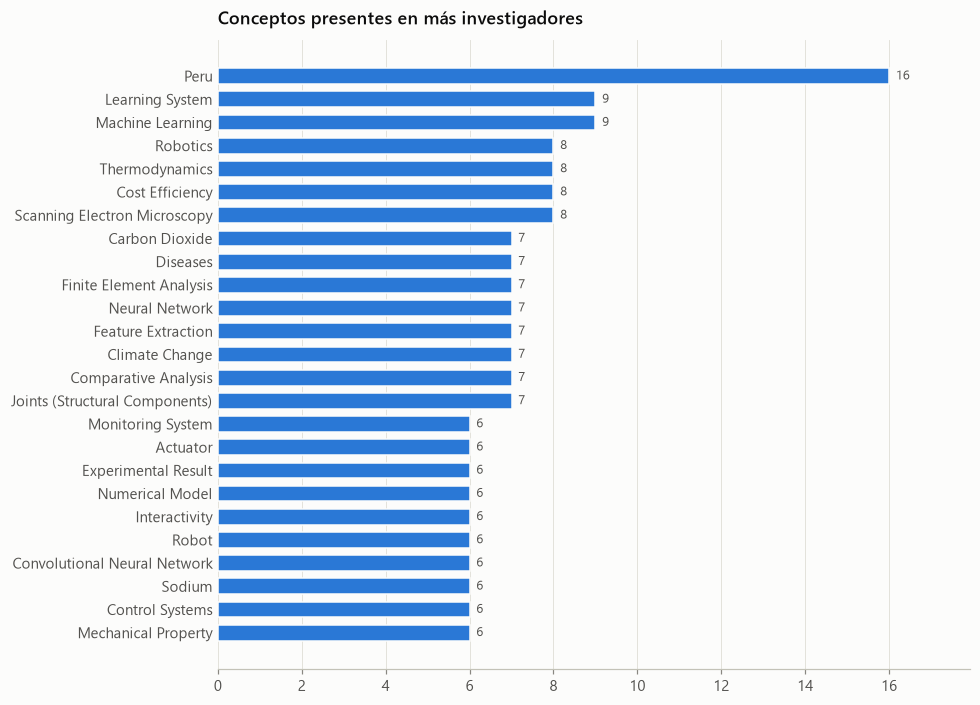

Conceptos que aparecen en un solo investigador: 82% de 3,356


,nombre,departamento,entropia_areas
49,Deyby Huamanchahua Canchanya,Ingeniería Electrónica y Mecatrónica,1.581390
18,Paul Cardenas Lizana,Bioingeniería e Ingeniería Química,1.563552
41,Heinner Hilario Guio Chunga,Bioingeniería e Ingeniería Química,1.562869
95,Julio Ernesto Valdivia Silva,Bioingeniería e Ingeniería Química,1.561062
90,Francisco Tarazona Vásquez,Bioingeniería e Ingeniería Química,1.558464


,nombre,departamento,entropia_areas
2,Helard Alvarez Sanchez,Ingeniería Mecánica y de la Energía,0.0
8,Walter Sebastian Barrutia Alta,Ingeniería Electrónica y Mecatrónica,0.0
9,Jesús Edwin Bellido Angulo,Sin departamento,0.0
29,José Andrés De Leo Martínez,"Humanidades, Artes y Ciencias Sociales",0.0
32,Luis Ernesto Flores Luyo,Ingeniería Industrial y Gestión de la Ingeniería,0.0


In [56]:
# Conceptos compartidos por más investigadores
cc = huella.groupby("concepto").investigador.nunique().sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 6.5))
barh(ax, cc.head(25), title="Conceptos presentes en más investigadores")
plt.tight_layout(); plt.show()
print(f"Conceptos que aparecen en un solo investigador: {(cc == 1).mean():.0%} de {len(cc):,}")

# Diversidad temática: entropía de Shannon de la distribución del peso entre áreas
def entropia(s):
    p = s / s.sum(); return max(0.0, -(p * np.log2(p)).sum())
div = huella.groupby(["investigador", "area"]).peso.sum().groupby("investigador").apply(entropia)
perfiles["entropia_areas"] = perfiles.nombre.map(div)
perfiles["n_conceptos"] = perfiles.nombre.map(huella.groupby("investigador").size()).fillna(0).astype(int)
display(perfiles.dropna(subset=["entropia_areas"]).nlargest(5, "entropia_areas")[["nombre", "departamento", "entropia_areas"]])
display(perfiles.dropna(subset=["entropia_areas"]).nsmallest(5, "entropia_areas")[["nombre", "departamento", "entropia_areas"]])

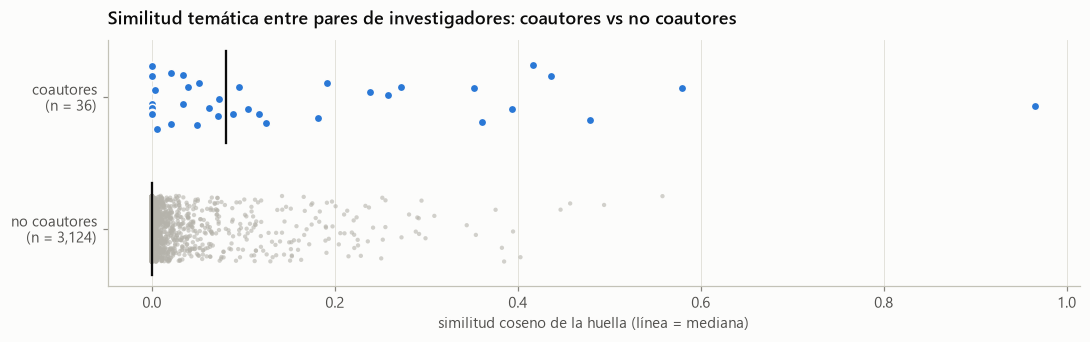

            count   mean    std  min    25%    50%    75%    max
coautores                                                       
False      3124.0  0.012  0.043  0.0  0.000  0.000  0.002  0.558
True         36.0  0.170  0.212  0.0  0.021  0.081  0.262  0.966


**Pares temáticamente cercanos que aún no publican juntos** (posibles colaboraciones):

,a,b,similitud,coautores,mismo_depto,depto_a,depto_b
2241,Jhedmar Jhonatan Callupe Luna,Oscar Ramos Ponce,0.558,False,True,Ingeniería Electrónica y Mecatrónica,Ingeniería Electrónica y Mecatrónica
1314,Deyby Huamanchahua Canchanya,Oscar Ramos Ponce,0.494,False,True,Ingeniería Electrónica y Mecatrónica,Ingeniería Electrónica y Mecatrónica
3049,Oscar Ramos Ponce,Sergio Aranda Egusquiza,0.457,False,True,Ingeniería Electrónica y Mecatrónica,Ingeniería Electrónica y Mecatrónica
3011,Monica C. Santa-Maria,Pedro Rau Lavado,0.447,False,True,Ingeniería Civil y Ambiental,Ingeniería Civil y Ambiental
2412,Jose Fiestas Iquira,Sashwat Tanay,0.403,False,False,Ciencia de Computación y de Datos,Ciencias
1321,Deyby Huamanchahua Canchanya,Ruth Canahuire Cabello,0.395,False,False,Ingeniería Electrónica y Mecatrónica,Sin departamento
1286,Deyby Huamanchahua Canchanya,Jhedmar Jhonatan Callupe Luna,0.385,False,True,Ingeniería Electrónica y Mecatrónica,Ingeniería Electrónica y Mecatrónica
2248,Jhedmar Jhonatan Callupe Luna,Ruth Canahuire Cabello,0.383,False,False,Ingeniería Electrónica y Mecatrónica,Sin departamento
3084,Pedro Rau Lavado,Ronald R. Gutierrez,0.376,False,True,Ingeniería Civil y Ambiental,Ingeniería Civil y Ambiental
144,Akira Armando Wong Sato,Pedro Rau Lavado,0.354,False,False,Sin departamento,Ingeniería Civil y Ambiental


In [57]:
# Similitud temática entre investigadores (coseno sobre los pesos de conceptos)
# (un concepto puede repetirse en varias áreas: se toma su peso máximo)
X = huella.pivot_table(index="investigador", columns="concepto", values="peso", aggfunc="max", fill_value=0)
Xn = X.div(np.sqrt((X ** 2).sum(axis=1)), axis=0)
S = pd.DataFrame(Xn.values @ Xn.values.T, index=X.index.rename("a"), columns=X.index.rename("b"))

pares = S.where(np.triu(np.ones(S.shape, bool), 1)).stack().dropna().rename("similitud").reset_index()
pares.columns = ["a", "b", "similitud"]
pares["coautores"] = [G.has_edge(a, b) for a, b in zip(pares.a, pares.b)]
pares["mismo_depto"] = [dep_map[a] == dep_map[b] for a, b in zip(pares.a, pares.b)]

fig, ax = plt.subplots(figsize=(10, 3.2))
rng = np.random.default_rng(0)
for yy, (grupo, color, s) in enumerate([(False, OTHER, 8), (True, BLUE, 30)]):
    x = pares.loc[pares.coautores == grupo, "similitud"]
    ax.scatter(x, yy + rng.uniform(-.25, .25, len(x)), s=s, color=color, alpha=.6 if not grupo else 1,
               edgecolor=SURFACE if grupo else "none", linewidth=1)
    ax.plot([x.median()] * 2, [yy - .35, yy + .35], color=INK, lw=1.5)
ax.set_yticks([0, 1], [f"no coautores\n(n = {(~pares.coautores).sum():,})", f"coautores\n(n = {pares.coautores.sum()})"])
ax.set_xlabel("similitud coseno de la huella (línea = mediana)"); ax.grid(axis="y", visible=False)
ax.set_title("Similitud temática entre pares de investigadores: coautores vs no coautores")
plt.tight_layout(); plt.show()
print(pares.groupby("coautores").similitud.describe().round(3))

display(Markdown("**Pares temáticamente cercanos que aún no publican juntos** (posibles colaboraciones):"))
display(pares[~pares.coautores].nlargest(10, "similitud").assign(
    depto_a=lambda d: d.a.map(dep_map), depto_b=lambda d: d.b.map(dep_map)).round(3))

Pares con ambas medidas: 3,081 | Spearman huella vs resúmenes: 0.46


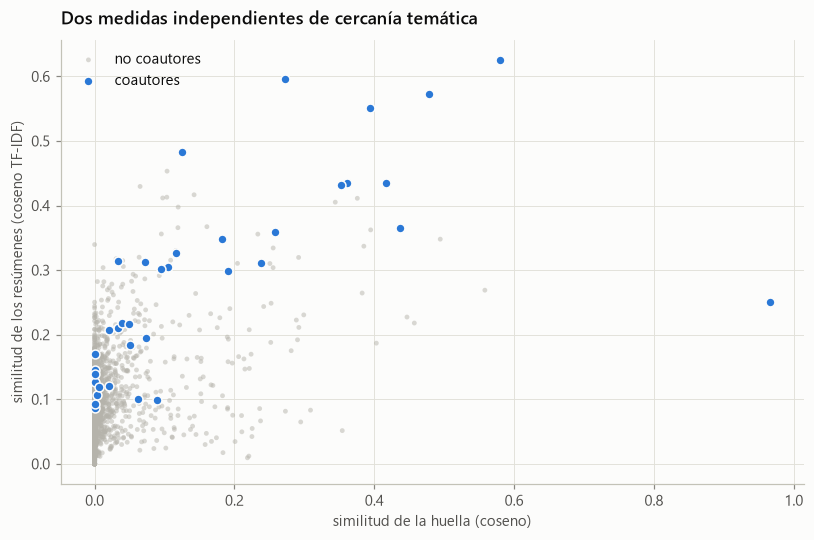

**Posibles colaboraciones confirmadas por ambas medidas** (no coautores, rango combinado):

,a,b,similitud,sim_resumenes,mismo_depto
1314,Deyby Huamanchahua Canchanya,Oscar Ramos Ponce,0.494,0.348,True
3084,Pedro Rau Lavado,Ronald R. Gutierrez,0.376,0.411,True
1321,Deyby Huamanchahua Canchanya,Ruth Canahuire Cabello,0.395,0.362,False
1498,Elvis Jara Alegria,Ruth Canahuire Cabello,0.344,0.405,False
1286,Deyby Huamanchahua Canchanya,Jhedmar Jhonatan Callupe Luna,0.385,0.337,True
1491,Elvis Jara Alegria,Oscar Ramos Ponce,0.292,0.320,True
1271,Deyby Huamanchahua Canchanya,Elvis Jara Alegria,0.255,0.334,True
1197,Daniel Vicente Horna Muñoz,Ronald R. Gutierrez,0.233,0.356,True
2241,Jhedmar Jhonatan Callupe Luna,Oscar Ramos Ponce,0.558,0.269,True
1194,Daniel Vicente Horna Muñoz,Pedro Rau Lavado,0.251,0.310,True


In [58]:
# Validación con una fuente independiente: similitud de los resúmenes (TF-IDF de la sección 7.5)
# Vector de cada investigador = media de los TF-IDF de sus resúmenes (sin col. masivas)
from sklearn.preprocessing import normalize
inv_docs = docs[["investigadores"]].reset_index(drop=True).explode("investigadores")
R = {}
for inv_, idx in inv_docs.groupby("investigadores").groups.items():
    R[inv_] = np.asarray(Xt[idx.values].mean(axis=0)).ravel()
R = pd.DataFrame(R).T
Rn = normalize(R.values)
S_res = pd.DataFrame(Rn @ Rn.T, index=R.index, columns=R.index)

pares["sim_resumenes"] = [S_res.at[a, b] if a in S_res.index and b in S_res.index else np.nan
                          for a, b in zip(pares.a, pares.b)]
pv = pares.dropna(subset=["sim_resumenes"])
print(f"Pares con ambas medidas: {len(pv):,} | Spearman huella vs resúmenes: "
      f"{pv.similitud.corr(pv.sim_resumenes, method='spearman'):.2f}")

fig, ax = plt.subplots(figsize=(7.5, 5))
for grupo, color, s in [(False, OTHER, 10), (True, BLUE, 34)]:
    d = pv[pv.coautores == grupo]
    ax.scatter(d.similitud, d.sim_resumenes, s=s, color=color, alpha=.5 if not grupo else 1,
               edgecolor=SURFACE if grupo else "none", linewidth=1, label="coautores" if grupo else "no coautores")
ax.set_xlabel("similitud de la huella (coseno)"); ax.set_ylabel("similitud de los resúmenes (coseno TF-IDF)")
ax.set_title("Dos medidas independientes de cercanía temática"); ax.legend(loc="upper left")
plt.tight_layout(); plt.show()

display(Markdown("**Posibles colaboraciones confirmadas por ambas medidas** (no coautores, rango combinado):"))
pv = pv.assign(rango=pv.similitud.rank(pct=True) + pv.sim_resumenes.rank(pct=True))
display(pv[~pv.coautores].nlargest(10, "rango")[["a", "b", "similitud", "sim_resumenes", "mismo_depto"]].round(3))

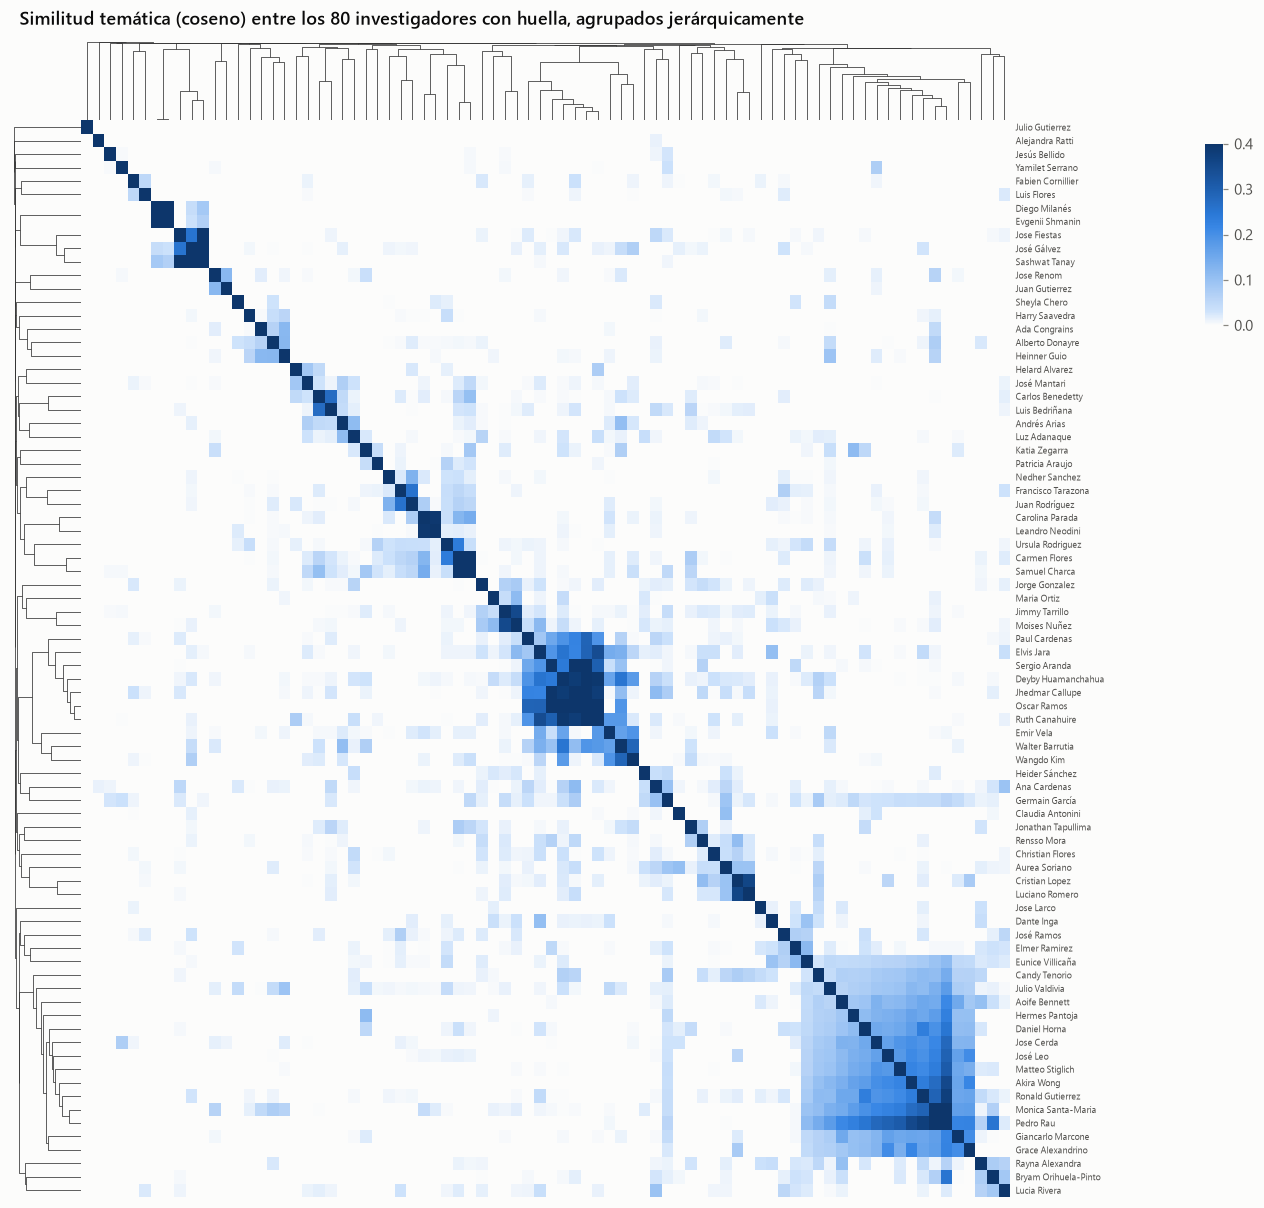

In [59]:
# Mapa de similitud agrupado (clustering jerárquico)
cg =sns.clustermap(S, cmap=CMAP_SEQ, vmin=0, vmax=0.4, figsize=(11, 11), xticklabels=False,
                    yticklabels=[corto(n) for n in S.index], dendrogram_ratio=0.07,
                    cbar_pos=(1.0, 0.75, 0.015, 0.15), method="average", metric="cosine")
cg.ax_heatmap.tick_params(axis="y", labelsize=6, length=0)
cg.ax_heatmap.set_xlabel(""); cg.ax_heatmap.set_ylabel("")
cg.figure.suptitle("Similitud temática (coseno) entre los 80 investigadores con huella, agrupados jerárquicamente",
                   x=0.02, y=1.01, ha="left", fontsize=12, fontweight="semibold")
plt.show()

In [60]:
# Coherencia temas declarados ↔ huella: ¿los temas de interés aparecen en los conceptos?
def solapamiento(r):
    temas = [norm(t) for t in split_pipe(r.temas_interes)]
    conc = " ".join(norm(c) for c in huella.loc[huella.investigador == r.nombre, "concepto"])
    if not temas or not conc: return np.nan
    palabras = {w for t in temas for w in re.findall(r"[a-z]{5,}", t)}
    return np.mean([w in conc for w in palabras]) if palabras else np.nan

perfiles["solap_temas_huella"] = perfiles.apply(solapamiento, axis=1)
print("Fracción de palabras de los temas declarados que aparecen en la huella:")
print(perfiles.solap_temas_huella.describe().round(2).to_string())
print("\nNota: los temas suelen estar en español y la huella en inglés, por lo que este solapamiento léxico es una cota inferior.")

Fracción de palabras de los temas declarados que aparecen en la huella:
count    71.00
mean      0.04
std       0.06
min       0.00
25%       0.00
50%       0.00
75%       0.08
max       0.25

Nota: los temas suelen estar en español y la huella en inglés, por lo que este solapamiento léxico es una cota inferior.


**Huella digital**

- Computer Science y Engineering concentran el mayor peso (33 y 30 investigadores, respectivamente). Les siguen Social Sciences y Earth and Planetary Sciences.
- **Los perfiles temáticos por departamento son coherentes** con su nombre: Física 93 % Physics, Computación 72 % Computer Science, Humanidades 53 % Arts & Humanities + 43 % Social Sciences. **Bioingeniería e Ingeniería Química es el departamento más interdisciplinario**: su peso se reparte entre 13 áreas, y los 5 investigadores de mayor entropía temática pertenecen a él.
- **Perú es el concepto compartido por más investigadores** (16), en línea con el aumento de títulos sobre el contexto local. Le siguen *Machine Learning*, *Robotics* y *Thermodynamics*.
- El **82 % de los conceptos aparece en un solo investigador**: la matriz investigador × concepto es muy dispersa.
- **Los coautores son temáticamente más parecidos** (similitud mediana 0,08 frente a ~0 entre no coautores). El clustering muestra bloques claros: robótica y mecatrónica (Huamanchahua, Callupe, Ramos, Aranda, Canahuire); agua, ambiente y ciencias sociales (Rau, Santa-Maria, Gutierrez, Wong, Marcone, Alexandrino…); física y astrofísica (Milanés, Shmanin, Fiestas, Gálvez, Tanay).
- **Posibles colaboraciones**: hay pares muy parecidos que no tienen ninguna publicación conjunta (se comprobó por título), por ejemplo Callupe–Ramos (0,56) y Huamanchahua–Ramos (0,49), del mismo departamento, o Fiestas (Computación)–Tanay (Ciencias), de departamentos distintos.
- **Validación con los resúmenes** (fuente independiente de la huella): la similitud TF-IDF de los resúmenes de cada par correlaciona con la de la huella (Spearman 0,46), y los coautores quedan arriba en ambas. Los pares que destacan en las dos medidas son los candidatos más sólidos a colaborar: Huamanchahua–Ramos, Rau–Gutierrez, Huamanchahua–Canahuire y Jara–Canahuire (estos dos últimos, entre departamentos distintos).
- Los temas de interés declarados casi no coinciden léxicamente con la huella, porque unos están en español y la otra en inglés. Para compararlos habría que traducirlos o usar *embeddings* multilingües.

## 10. Fotos

In [61]:
rows = []
for f in perfiles.archivo_foto:
    p = DATA / f
    im = Image.open(p)
    a = np.asarray(im.convert("L"), dtype=float)
    rows.append({"archivo": f, "formato": p.suffix.lower(), "ancho": im.size[0], "alto": im.size[1],
                 "modo": im.mode, "KB": p.stat().st_size / 1024, "brillo_medio": a.mean(),
                 "md5": hashlib.md5(p.read_bytes()).hexdigest()})
fot = pd.DataFrame(rows)
fot["placeholder"] = fot.md5.duplicated(keep=False)
display(fot.groupby(["formato", "modo"]).size().rename("n").to_frame().T)
display(fot[["ancho", "alto", "KB", "brillo_medio"]].describe().round(1).T)
print("Dimensiones:", fot.groupby(["ancho", "alto"]).size().sort_values(ascending=False).to_dict())
print("Imágenes idénticas (placeholder):", fot.loc[fot.placeholder, "archivo"].tolist())

formato .jpg .png     
modo     RGB  RGB RGBA
n         99    3    2

,count,mean,std,min,25%,50%,75%,max
ancho,104.0,160.3,2.1,160.0,160.0,160.0,160.0,175.0
alto,104.0,192.5,4.1,178.0,192.0,192.0,192.0,219.0
KB,104.0,6.1,0.8,3.5,5.6,6.0,6.6,8.3
brillo_medio,104.0,119.5,25.2,79.4,103.0,115.7,133.0,232.8


Dimensiones: {(160, 192): 99, (175, 219): 2, (160, 178): 1, (160, 199): 1, (160, 200): 1}
Imágenes idénticas (placeholder): ['fotos/eric-javier-biagioli.png', 'fotos/luis-ernesto-flores-luyo.png']


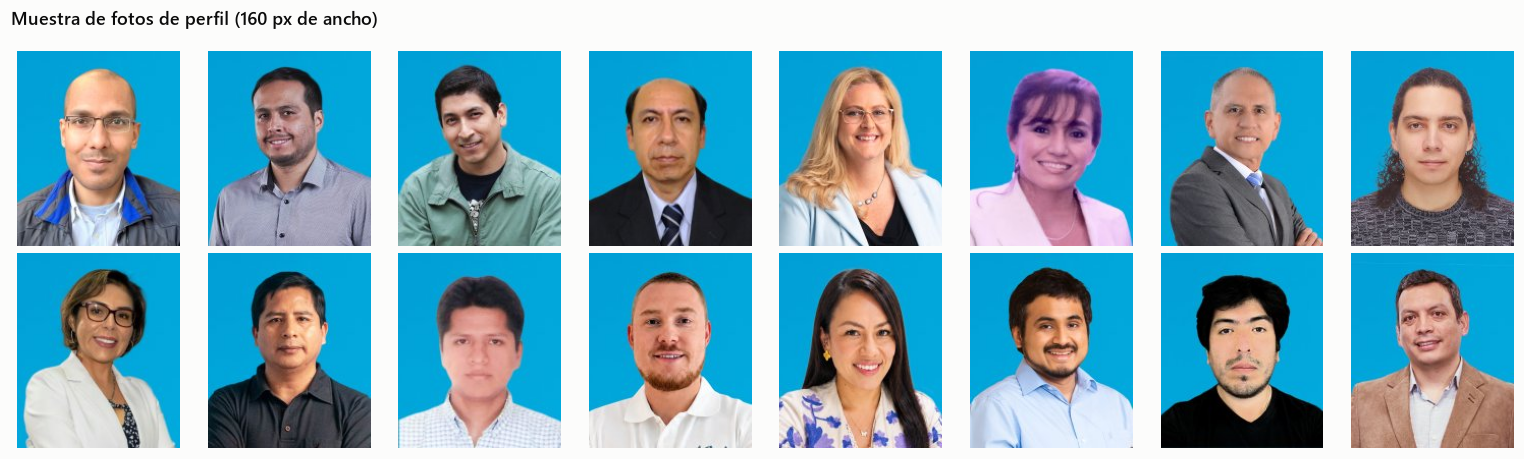

In [62]:
muestra = fot.sample(16, random_state=3).archivo.tolist()
fig, axes = plt.subplots(2, 8, figsize=(14, 4.2))
for ax, f in zip(axes.flat, muestra):
    ax.imshow(Image.open(DATA / f)); ax.axis("off")
fig.suptitle("Muestra de fotos de perfil (160 px de ancho)", x=0.01, ha="left", fontsize=12, fontweight="semibold")
plt.tight_layout(); plt.show()

**Fotos**: hay una foto por investigador (99 JPG y 5 PNG), casi todas de **160×192 px** y ~6 KB. Tienen un **fondo azul institucional uniforme**, lo que las hace aptas como avatares en visualizaciones (p. ej. nodos de la red). Dos archivos son el mismo *placeholder* (`no-portrait`) y deben tratarse como "sin foto". Dos PNG tienen canal alfa (RGBA), así que conviene convertirlas a RGB antes de componer imágenes.

## 11. Tabla integrada y conclusiones

### 11.1 Tabla por investigador

In [63]:
pubs_inv = pubs.groupby("investigador").agg(
    pubs_ultimos5=("anio_num", lambda s: (s.between(HOY.year - 5, HOY.year)).sum()),
    pubs_utec=("afiliacion_utec", "sum"),
    pct_articulos=("tipo", lambda s: s.eq("Artículo").mean()),
    mediana_autores=("n_autores", "median"))
grado_red = pd.Series(dict(G.degree()), name="coautores_utec")

master = (perfiles.merge(pubs_inv, left_on="nombre", right_index=True, how="left")
          .merge(grado_red, left_on="nombre", right_index=True, how="left"))
cols_master = ["nombre", "email", "departamento", "categoria", "directivo", "grado_max", "doctorado_en_curso",
               "renacyt", "renacyt_nivel", "citas", "indice_h", "n_publicaciones", "pubs_ultimos5",
               "pubs_utec", "pct_afiliacion_utec", "primer_anio_utec", "pct_primer_o_ultimo",
               "pct_articulos", "mediana_autores", "primer_anio", "anios_carrera", "coautores_utec",
               "n_conceptos", "entropia_areas", "n_temas", "n_grupos_centros", "n_identificadores",
               "tiene_orcid", "tiene_scopus", "tiene_google_scholar", "archivo_foto"]
master = master[cols_master]

OUT = Path("procesados"); OUT.mkdir(exist_ok=True)
master.to_csv(OUT / "investigadores_enriquecido.csv", index=False, encoding="utf-8")
tema_pub = docs.set_index("url").tema.map(dict(enumerate(ETQ_TEMA)))
(pubs_u.drop(columns=["autores_ref", "n_autores_det"])
 .assign(investigadores=pubs_u.investigadores.str.join(" | "),
         autores_utec_nombres=pubs_u.autores_utec_nombres.str.join(" | "),
         tema_resumen=pubs_u.url.map(tema_pub))
 .to_csv(OUT / "publicaciones_unicas.csv", index=False, encoding="utf-8"))
huella.to_csv(OUT / "huella_digital_limpia.csv", index=False, encoding="utf-8")
huella_pub.to_csv(OUT / "huella_publicaciones.csv", index=False, encoding="utf-8")
display(pd.DataFrame([(f.name, round(f.stat().st_size / 1024)) for f in sorted(OUT.iterdir())],
                     columns=["archivo", "KB"]))
master.head()

,archivo,KB
0,huella_digital_limpia.csv,319
1,huella_publicaciones.csv,1709
2,investigadores_enriquecido.csv,27
3,publicaciones_unicas.csv,12913


,nombre,email,departamento,categoria,directivo,grado_max,doctorado_en_curso,renacyt,renacyt_nivel,citas,indice_h,n_publicaciones,pubs_ultimos5,pubs_utec,pct_afiliacion_utec,primer_anio_utec,pct_primer_o_ultimo,pct_articulos,mediana_autores,primer_anio,anios_carrera,coautores_utec,n_conceptos,entropia_areas,n_temas,n_grupos_centros,n_identificadores,tiene_orcid,tiene_scopus,tiene_google_scholar,archivo_foto
0,Luz Antuanet Adanaque Infante,ladanaque@utec.edu.pe,Ciencia de Computación y de Datos,Docente de Enseñanza e Inv.,False,Maestría,True,VII,7.0,15.0,3.0,5,3.0,1.0,0.200000,2022.0,0.600000,0.2,3.0,2020.0,6.0,0.0,46,0.966711,3,0,5,True,True,True,fotos/luz-antuanet-adanaque-infante.jpg
1,José Manuel Aguilar Alfaro,jaguilar@utec.edu.pe,Negocios Digitales,Profesor Asociado,False,Doctorado,False,Sin RENACYT,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,4,1,1,True,False,False,fotos/josé-manuel-aguilar-alfaro.jpg
2,Helard Alvarez Sanchez,halvarez@utec.edu.pe,Ingeniería Mecánica y de la Energía,Solo investigador,False,Maestría,False,VII,7.0,10.0,2.0,3,1.0,3.0,1.000000,2017.0,0.666667,1.0,5.0,2017.0,9.0,3.0,17,0.000000,2,2,4,True,True,True,fotos/helard-alvarez-sanchez.jpg
3,Grace Alexandrino Ocaña,galexandrino@utec.edu.pe,"Humanidades, Artes y Ciencias Sociales",Profesor Auxiliar,False,Sin dato,False,VII,7.0,17.0,2.0,3,3.0,1.0,0.333333,2026.0,1.000000,1.0,4.0,2021.0,5.0,0.0,19,1.462847,3,0,4,True,True,True,fotos/grace-alexandrino-ocaña.jpg
4,Sergio Aranda Egusquiza,saranda@utec.edu.pe,Ingeniería Electrónica y Mecatrónica,Sin rol explícito,False,Maestría,False,Sin RENACYT,NaN,1.0,1.0,6,5.0,6.0,1.000000,2019.0,1.000000,0.0,2.5,2019.0,7.0,1.0,53,1.412782,10,1,3,True,True,False,fotos/sergio-aranda-egusquiza.jpg


In [64]:
# Investigadores sin publicaciones ni huella: ¿quiénes son?
sin = master[master.n_publicaciones == 0]
print(f"{len(sin)} investigadores sin publicaciones en CRIS")
display(sin.groupby("categoria").size().rename("n").to_frame().T)
display(sin[["nombre", "departamento", "categoria", "grado_max", "renacyt", "citas"]].head(25))

24 investigadores sin publicaciones en CRIS


categoria,Docente (otro),Docente de Enseñanza e Inv.,Profesor Asociado,Profesor Principal,Sin rol explícito,Solo investigador
n,1,2,1,1,16,3


,nombre,departamento,categoria,grado_max,renacyt,citas
1,José Manuel Aguilar Alfaro,Negocios Digitales,Profesor Asociado,Doctorado,Sin RENACYT,NaN
14,Eric Javier Biagioli,Ciencia de Computación y de Datos,Sin rol explícito,Sin dato,Sin RENACYT,NaN
15,Juan Bueno Villanueva,Ingeniería Industrial y Gestión de la Ingeniería,Sin rol explícito,Maestría,Sin RENACYT,NaN
20,Xyoby Chavez Pacheco,Ciencias,Sin rol explícito,Maestría,Sin RENACYT,NaN
24,Antuané De La Flor Basterrechea,"Humanidades, Artes y Ciencias Sociales",Sin rol explícito,Maestría,Sin RENACYT,NaN
27,Jose De La Puente Maldonado,Ingeniería Industrial y Gestión de la Ingeniería,Sin rol explícito,Título profesional,Sin RENACYT,NaN
28,Jose Gerardo Deustua Rossel,Sin departamento,Sin rol explícito,Sin dato,Sin RENACYT,NaN
36,Oscar Gamonal Pajares,Ingeniería Industrial y Gestión de la Ingeniería,Sin rol explícito,Maestría,Sin RENACYT,NaN
43,Oscar Hidalgo Wuest,"Humanidades, Artes y Ciencias Sociales",Sin rol explícito,Maestría,Sin RENACYT,NaN
44,Rocío Hoyos Diaz,Ciencias,Sin rol explícito,Maestría,Sin RENACYT,NaN


### 11.2 Conclusiones

**Sobre los datos**

1. Los ocho artefactos son **consistentes entre sí**. Los CSV reproducen el JSON salvo dos secciones marginales de los perfiles; el detalle de publicaciones describe exactamente las mismas 2479 publicaciones y los mismos 2976 pares (investigador, publicación). Las métricas cumplen las restricciones esperadas (citas ≥ h²).
2. **Problemas de calidad que hay que tratar**:
   - campos vacíos o constantes (`telefono`, `direccion`; en el detalle, `otros_enlaces`, `Número`, y en el JSON `archivos`, `citas_texto`, `citar_apa`)
   - fechas en tres formatos y con precisión variable
   - RENACYT con 13 etiquetas para 8 niveles
   - categoría docente ausente en un tercio de los perfiles
   - publicaciones repetidas entre investigadores, 14 títulos con varias URL y 5 DOI duplicados
   - **`n_autores` del detalle subcuenta en 1** cuando hay autores ocultos (artefacto del botón "Mostrar N otros"), y la referencia de `publicaciones.csv` los cuenta dos veces. El conteo corregido coincide con el BibTeX en el 99,6 % de los casos.
   - conceptos de la huella repetidos en varias áreas; la huella por publicación se trunca en 8 conceptos
   - algunas marcas de filiación UTEC anteriores a 2013 (fe de erratas y registros mal etiquetados)
   - 2 fotos *placeholder*
3. **Las métricas bibliométricas vienen de Scopus** y solo existen para 78 de 104 investigadores. Los 24 sin publicaciones en CRIS no tienen huella ni citas: es un subgrupo aparte, no datos faltantes al azar.

**Sobre el contenido**

4. **Dos investigadores de física de altas energías distorsionan casi todo**: firman el 46 % de las publicaciones únicas y acumulan el 78 % de las citas del dataset. Cualquier análisis agregado debe mostrarlos aparte.
5. Sin ellos, el conjunto de investigadores muestra una **producción en crecimiento** (×2,5 entre 2016 y 2022), apoyada en conferencias IEEE regionales y en artículos de revista de ingeniería. La producción está **concentrada** (Gini 0,63) y los equipos son pequeños (4 autores).
6. **Solo la mitad de esa producción se hizo con filiación UTEC** (51 % sin colaboraciones masivas). La proporción sube del 35 % en 2015 al 74–78 % en 2024–2025. Para hablar de "producción de UTEC" hay que filtrar por `afiliacion_utec`, no basta con estar en CRIS.
7. **Al llegar a UTEC, los investigadores pasan de primeros autores a autores senior**: con filiación UTEC firman en último lugar el 44 % de las veces (17 % antes) y en primer lugar el 22 % (47 % antes). Es el patrón de quien dirige equipos con estudiantes.
8. El **RENACYT es un buen resumen** del perfil bibliométrico (ρ = −0,79 con el índice h). El doctorado y la categoría docente se asocian con métricas más altas.
9. La **colaboración interna es escasa** (densidad 0,011, el 54 % de los investigadores con publicaciones están aislados). Aun así, dos medidas independientes, la huella y los resúmenes, coinciden en **pares temáticamente cercanos sin coautoría**: oportunidades concretas de colaboración.
10. El perfil temático confirma una universidad **centrada en ingeniería y computación**. Los resúmenes revelan 12 líneas claras, de las cuales las de mayor crecimiento reciente son agua/hidrología y exoesqueletos/rehabilitación. Bioingeniería es el polo interdisciplinario, y el interés por el contexto peruano crece (1 de cada 4 resúmenes lo menciona en 2024).

**Recomendaciones para la etapa de visualización**

- Usar **escala log** para citas, índice h, publicaciones y tamaño de equipo, y **separar siempre las colaboraciones masivas**.
- Contar sobre publicaciones únicas (`procesados/publicaciones_unicas.csv`, que ahora incluye resumen, DOI, editorial, filiación, conferencia y tema) y usar la tabla integrada `procesados/investigadores_enriquecido.csv` como base de los dashboards. `procesados/huella_publicaciones.csv` contiene la huella por publicación en formato largo.
- Ideas que los datos sostienen bien:
  - la red de coautoría con fotos como nodos
  - el mapa de calor departamento × área o tema
  - la línea de tiempo apilada por tipo y por filiación UTEC
  - la matriz de similitud temática como recomendador de colaboraciones
  - la escalera RENACYT vs índice h
  - un buscador de publicaciones por tema o resumen
  - un mapa de países de conferencias